## Proyecto final: Predicción de toxicidad en nanopatículas

### Introducción
Las nanopartículas (NPs) han adquirido gran relevancia en diversas áreas, como la medicina, la electrónica, la industria y el desarrollo de nuevos materiales, debido a las propiedades particulares que presentan a escala nanométrica. Sin embargo, estas mismas propiedades pueden favorecer interacciones con sistemas biológicos y generar efectos adversos. Por ello, la evaluación de su toxicidad es fundamental para garantizar su uso seguro y contribuir al desarrollo de nanomateriales con un menor impacto en la salud y el medio ambiente (Forest, 2022; Eker et al., 2024).

La toxicidad de las nanopartículas depende de múltiples factores, entre los que se encuentran su composición química, tamaño, carga superficial, área superficial, concentración y condiciones de exposición. La interacción entre estos factores dificulta anticipar su comportamiento biológico. Además, los estudios experimentales de toxicidad pueden implicar costos elevados, tiempos prolongados de experimentación y recursos especializados, lo que limita la cantidad de materiales y condiciones que pueden evaluarse (Escorihuela et al., 2018; Puzyn et al., 2011).

Por otro lado, después de la síntesis de nanopartículas, es común realizar diferentes técnicas de caracterización para determinar sus propiedades fisicoquímicas. Estos procedimientos generan información que permite establecer relaciones entre las características del material y su respuesta biológica (Sayes & Warheit, 2009; Escorihuela et al., 2018). Por lo tanto, existe la oportunidad de aprovechar los datos generados durante la caracterización como parte de los atributos de entrada de modelos predictivos de toxicidad.

En este contexto, el aprendizaje automático representa una alternativa para identificar patrones y relaciones entre las propiedades de las nanopartículas, las condiciones experimentales y su respuesta toxicológica. El desarrollo de modelos predictivos podría contribuir a reducir la cantidad de ensayos experimentales necesarios, optimizar recursos y orientar el diseño de nanomateriales más seguros, sin sustituir la validación experimental (Puzyn et al., 2011; Forest, 2022; Banaye Yazdipour et al., 2023).

El presente proyecto se enfoca en la predicción de la toxicidad de nanopartículas de óxidos metálicos mediante diferentes técnicas de aprendizaje automático. Además de evaluar el desempeño predictivo de los modelos, se analizará la influencia de la selección y reducción de características, la calidad de los datos, las técnicas de balanceo y la capacidad de generalización a tipos de nanopartículas no vistos durante el entrenamiento.

Para el proyecto se estableció las siguientes preguntas de investigación:

1. **¿Qué tan efectivos son los modelos de aprendizaje automático para predecir la toxicidad de nanopartículas de óxidos metálicos a partir de sus propiedades fisicoquímicas y condiciones experimentales?**

2. **¿Cómo influyen las técnicas de selección y reducción de características en el desempeño predictivo de los modelos?**

3. **¿Cómo afectan los registros duplicados, las etiquetas contradictorias y las técnicas de balanceo al desempeño de los modelos de clasificación?**

4. **¿Qué capacidad tienen los modelos para generalizar sus predicciones a tipos de nanopartículas no vistos durante el entrenamiento?**

### Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib_venn import venn2
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer 
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from functools import partial
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from itertools import product
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    accuracy_score,
    confusion_matrix,
    make_scorer,
    ConfusionMatrixDisplay,
    jaccard_score
)
from tqdm import tqdm
import time
from scipy.stats import randint, uniform, loguniform
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_validate, GridSearchCV, LeaveOneGroupOut

### 1. Análisis exploratorio de datos (EDA)

El **dataset** utilizado en este proyecto, denominado *Nanoparticle Toxicity Dataset*, se obtuvo de la plataforma Kaggle, donde fue publicado por UCI Machine Learning. Contiene información sobre nanopartículas de óxidos metálicos, incluyendo sus propiedades fisicoquímicas, condiciones de exposición y clasificación de toxicidad (UCI Machine Learning, s. f.).

En esta sección se explorará la estructura del conjunto de datos, la distribución de sus variables y las posibles relaciones entre las características de las nanopartículas y su toxicidad. Este análisis permitirá identificar patrones relevantes y aspectos que deberán considerarse durante el preprocesamiento y entrenamiento de los modelos.

#### 1.1. Inspección inicial del conjunto de datos

El conjunto de datos contiene **881 observaciones y 11 variables**, de las cuales 10 corresponden a características predictoras y una a la variable objetivo (`class`).

Las características incluyen nueve variables numéricas relacionadas con las propiedades fisicoquímicas y las condiciones de exposición, así como una variable categórica (`NPs`) que identifica el tipo de nanopartícula.

In [121]:
# Cargar el conjunto de datos
df = pd.read_csv("nanotox_dataset.csv")

# Dimensiones y primeras observaciones
print(f"Dimensiones: {df.shape[0]} registros y {df.shape[1]} variables")
display(df.head())

# Información general
print("\nInformación del conjunto de datos:")
df.info()

# Valores faltantes
print("\nValores faltantes por variable:")
display(df.isnull().sum().to_frame("Valores faltantes"))

# Distribución de la variable objetivo
print("\nDistribución de toxicidad:")
display(
    df["class"].value_counts()
    .to_frame("Frecuencia")
)


Dimensiones: 881 registros y 11 variables


,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,class
0,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.001,1.61,3,nonToxic
1,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.010,1.61,3,nonToxic
2,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.100,1.61,3,nonToxic
3,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,1.000,1.61,3,nonToxic
4,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,5.000,1.61,3,nonToxic



Información del conjunto de datos:
<class 'pandas.DataFrame'>
RangeIndex: 881 entries, 0 to 880
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   NPs         881 non-null    str    
 1   coresize    881 non-null    float64
 2   hydrosize   881 non-null    float64
 3   surfcharge  881 non-null    float64
 4   surfarea    881 non-null    float64
 5   Ec          881 non-null    float64
 6   Expotime    881 non-null    int64  
 7   dosage      881 non-null    float64
 8   e           881 non-null    float64
 9   NOxygen     881 non-null    int64  
 10  class       881 non-null    str    
dtypes: float64(7), int64(2), str(2)
memory usage: 75.8 KB

Valores faltantes por variable:


,Valores faltantes
NPs,0
coresize,0
hydrosize,0
surfcharge,0
surfarea,0
Ec,0
Expotime,0
dosage,0
e,0
NOxygen,0



Distribución de toxicidad:


,Frecuencia
class,
Toxic,476
nonToxic,405


No se identificaron valores faltantes. La variable objetivo distingue entre nanopartículas clasificadas como tóxicas (`Toxic`) y no tóxicas (`nonToxic`).

La presencia de registros duplicados y posibles inconsistencias en las etiquetas se estudiará posteriormente en una sección dedicada a la calidad de los datos.

#### 1.2. Distribución de la variable objetivo

Se analizará la distribución de las clases `Toxic` y `nonToxic` para identificar posibles desequilibrios que deban considerarse durante el entrenamiento y evaluación de los modelos.

,Frecuencia,Porcentaje (%)
class,,
Toxic,476,54.03
nonToxic,405,45.97


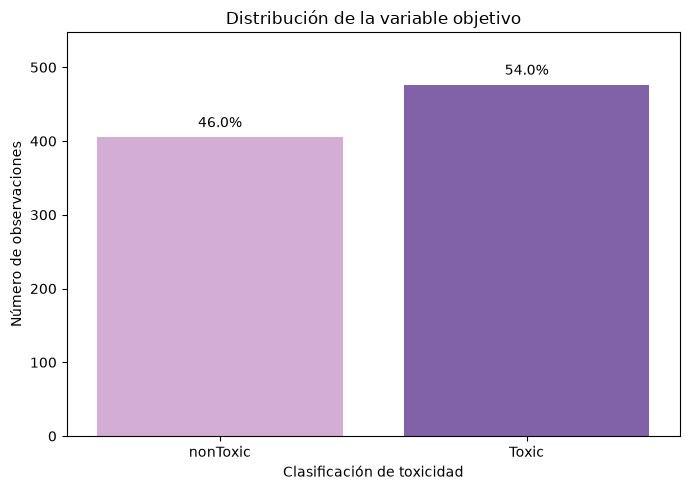

In [122]:
# Distribución de la variable objetivo
conteo_clases = df["class"].value_counts()
porcentaje_clases = df["class"].value_counts(normalize=True) * 100

tabla_clases = pd.DataFrame({
    "Frecuencia": conteo_clases,
    "Porcentaje (%)": porcentaje_clases.round(2)
})

display(tabla_clases)

# Visualización
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="class",
    order=["nonToxic", "Toxic"],
    hue="class",
    hue_order=["nonToxic", "Toxic"],
    palette=["#D9A7D9", "#8055B3"],
    legend=False
)

# Mostrar porcentajes
for barra in ax.patches:
    altura = barra.get_height()
    if altura > 0:
        porcentaje = altura / len(df) * 100
        ax.annotate(
            f"{porcentaje:.1f}%",
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 5),
            textcoords="offset points"
        )

plt.title("Distribución de la variable objetivo")
plt.xlabel("Clasificación de toxicidad")
plt.ylabel("Número de observaciones")
plt.ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()

La distribución de la variable objetivo es relativamente equilibrada, con un 54% de observaciones clasificadas como tóxicas y un 46% como no tóxicas. Por lo tanto, no se identifica un desbalance importante entre las clases

#### 1.3. Distribución de las características fisicoquímicas

Se examinarán las distribuciones de las nueve variables numéricas mediante histogramas para identificar asimetrías, valores extremos y diferencias de escala que puedan influir en el entrenamiento de los modelos.

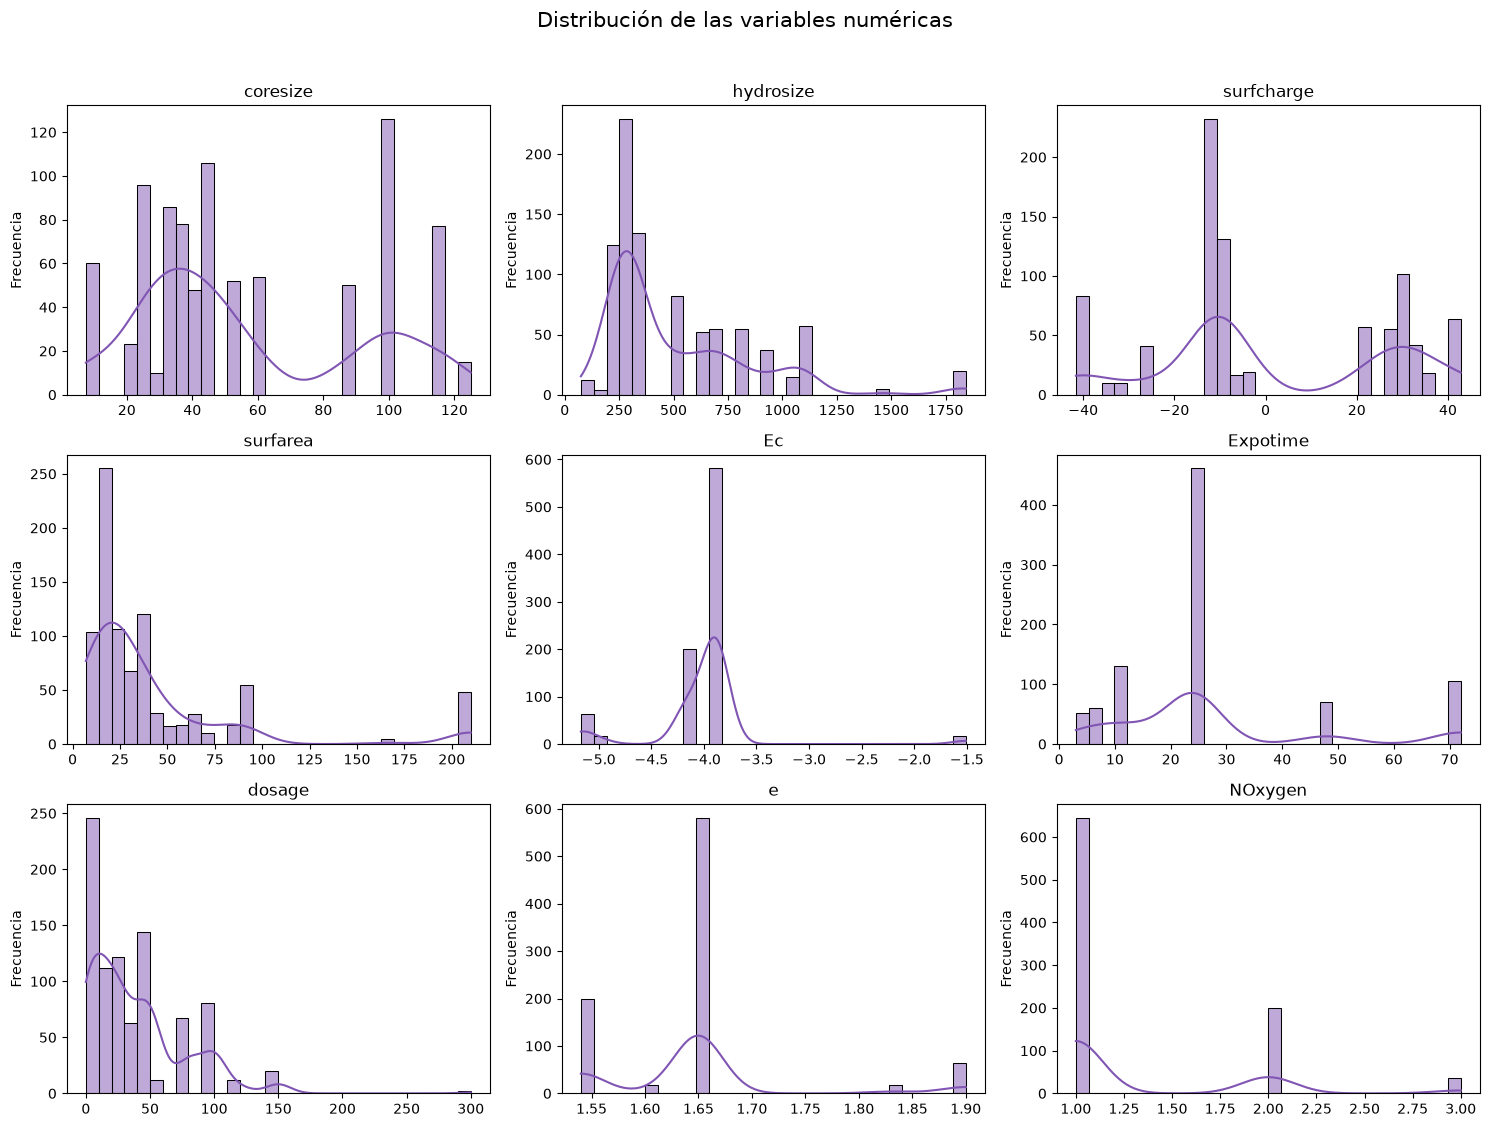

In [123]:
# Variables numéricas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

# Histogramas
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, columna in enumerate(variables_numericas):
    sns.histplot(
        data=df,
        x=columna,
        bins=30,
        kde=True,
        color="#8055B3",
        ax=axes[i]
    )

    axes[i].set_title(columna)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")

plt.suptitle(
    "Distribución de las variables numéricas",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

Las variables numéricas presentan distribuciones heterogéneas, con asimetrías y concentraciones en valores específicos. Algunas características, como `hydrosize`, `surfarea` y `dosage`, muestran valores extremos que podrían corresponder a distintas condiciones experimentales. Además, las diferencias de escala entre variables deberán considerarse durante el preprocesamiento, especialmente al aplicar PCA y entrenar modelos sensibles a la escala.

#### 1.4. Distribución de características por tipo de nanopartícula

Se compararán las propiedades fisicoquímicas de los distintos tipos de nanopartículas mediante *boxplots*, con el propósito de identificar diferencias en sus distribuciones y posibles valores atípicos.

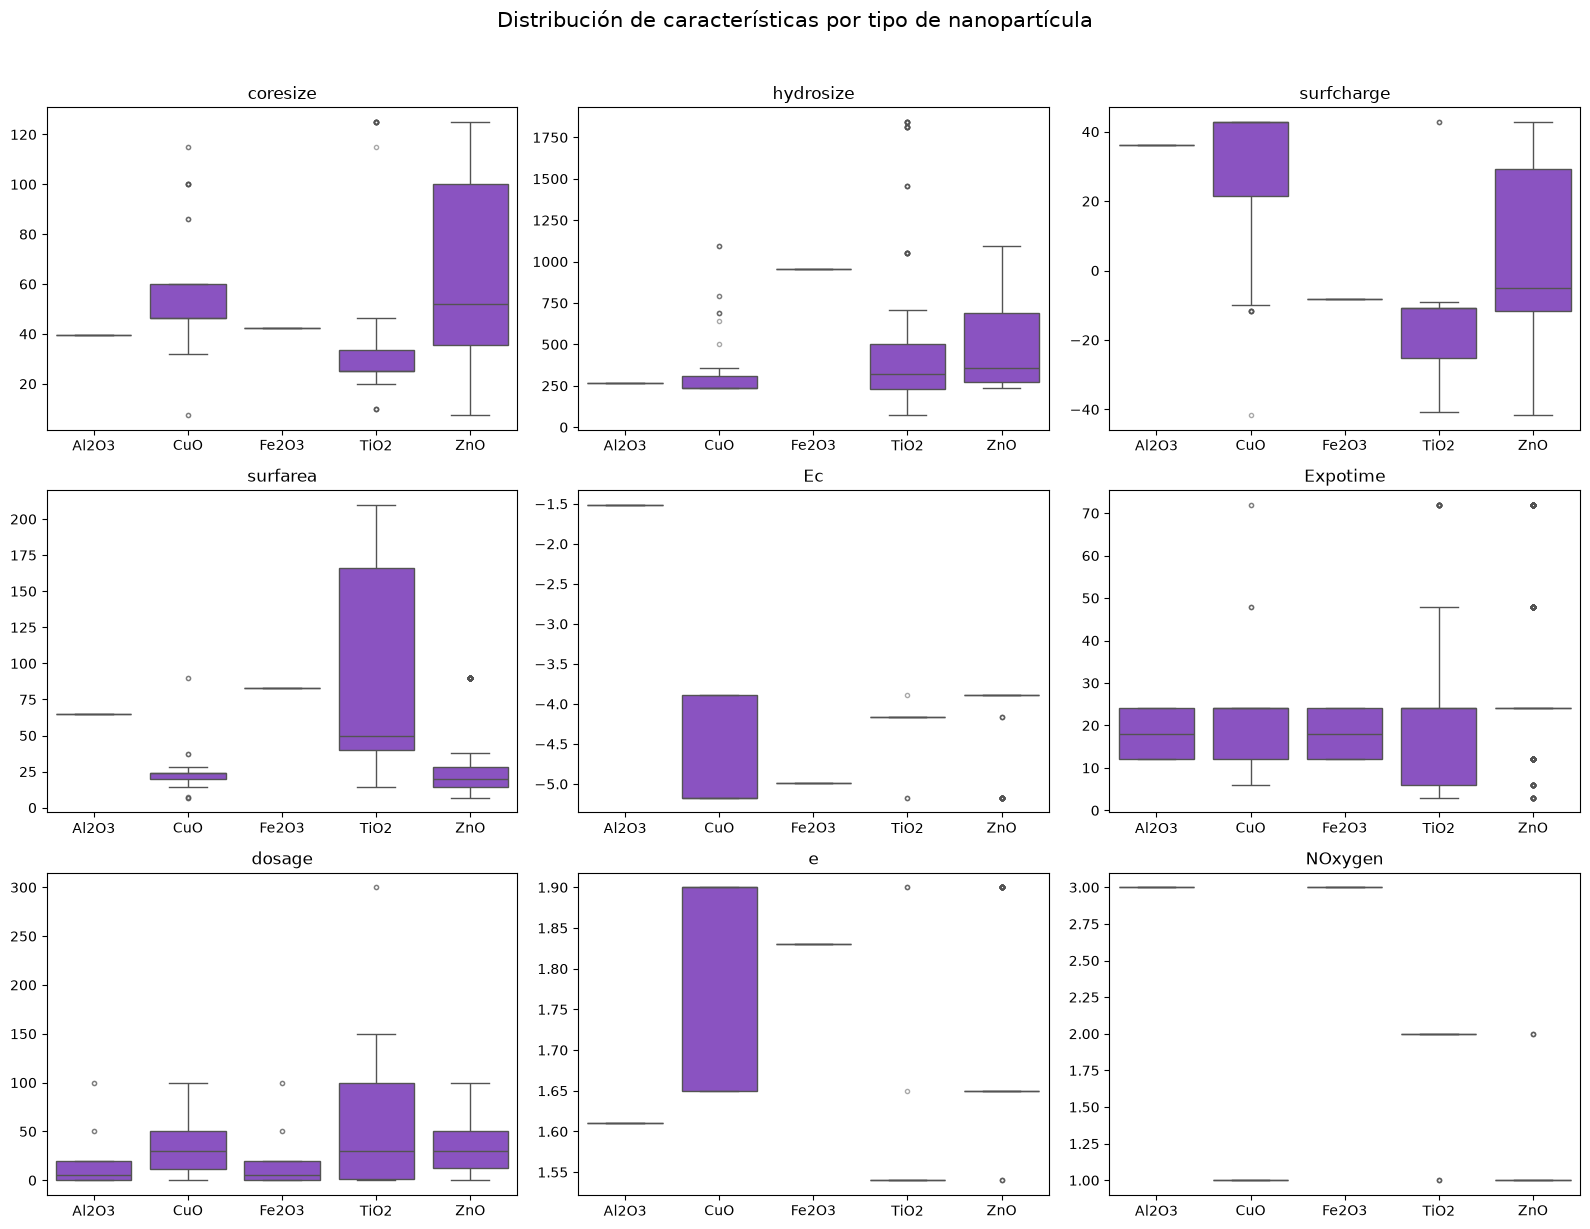

In [124]:
# Variables numéricas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

# Diagramas de caja por tipo de nanopartícula
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, columna in enumerate(variables_numericas):
    sns.boxplot(
        data=df,
        x="NPs",
        y=columna,
        color="#8A41D3",
        ax=axes[i],
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        }
    )

    axes[i].set_title(columna)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.suptitle(
    "Distribución de características por tipo de nanopartícula",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


Las distribuciones muestran diferencias entre los tipos de nanopartículas, tanto en sus propiedades fisicoquímicas como en las condiciones de exposición. Algunas variables, particularmente `Ec`, `e` y `NOxygen`, presentan valores estrechamente asociados con determinados materiales, mientras que otras, como `coresize`, `hydrosize` y `surfarea`, muestran mayor variabilidad. Estas diferencias sugieren que algunas características podrían actuar como indicadores de la identidad de las nanopartículas, lo cual deberá considerarse al evaluar su importancia predictiva.

#### 1.5. Relación entre el tipo de nanopartícula y la toxicidad

Se analizará la distribución de las clases `Toxic` y `nonToxic` para cada tipo de nanopartícula, con el propósito de identificar posibles diferencias en la proporción de observaciones tóxicas entre materiales.

class,nonToxic,Toxic
NPs,,
Al2O3,18,0
CuO,11,40
Fe2O3,18,0
TiO2,194,6
ZnO,164,430


class,nonToxic,Toxic
NPs,,
Al2O3,100.00,0.00
CuO,21.57,78.43
Fe2O3,100.00,0.00
TiO2,97.00,3.00
ZnO,27.61,72.39


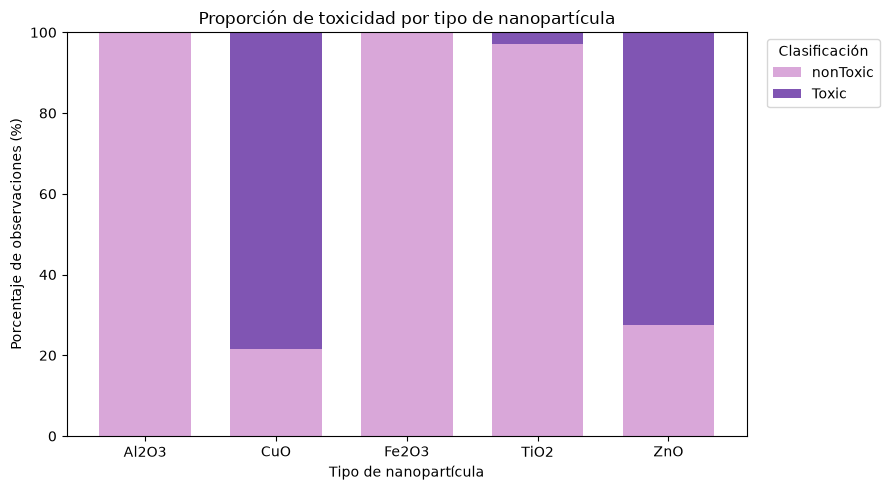

In [125]:
# Frecuencia de clases por tipo de nanopartícula
tabla_toxicidad = pd.crosstab(
    df["NPs"],
    df["class"]
).reindex(columns=["nonToxic", "Toxic"], fill_value=0)

display(tabla_toxicidad)

# Porcentaje de cada clase por nanopartícula
proporciones = (
    tabla_toxicidad.div(
        tabla_toxicidad.sum(axis=1), axis=0
    ) * 100
)

display(proporciones.round(2))

# Gráfico de barras apiladas
ax = proporciones.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

plt.title("Proporción de toxicidad por tipo de nanopartícula")
plt.xlabel("Tipo de nanopartícula")
plt.ylabel("Porcentaje de observaciones (%)")
plt.xticks(rotation=0)
plt.yticks(range(0, 101, 20))
plt.ylim(0, 100)
plt.legend(
    title="Clasificación",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

La proporción de toxicidad varía considerablemente entre los tipos de nanopartículas. Todas las observaciones de Al₂O₃ y Fe₂O₃ se clasifican como no tóxicas, mientras que CuO y ZnO presentan una mayoría de observaciones tóxicas. Por su parte, TiO₂ muestra una proporción muy baja de toxicidad. Estos resultados evidencian una asociación entre el tipo de nanopartícula y la variable objetivo, aunque no permiten determinar si las diferencias se deben al material o a las condiciones experimentales.

#### 1.6. Correlaciones entre variables numéricas

Se calculará la matriz de correlación de Pearson para identificar relaciones lineales entre las variables numéricas y detectar posibles redundancias. Este análisis permitirá explorar si algunas características aportan información similar, lo cual será relevante al evaluar posteriormente las técnicas de reducción y selección de características.

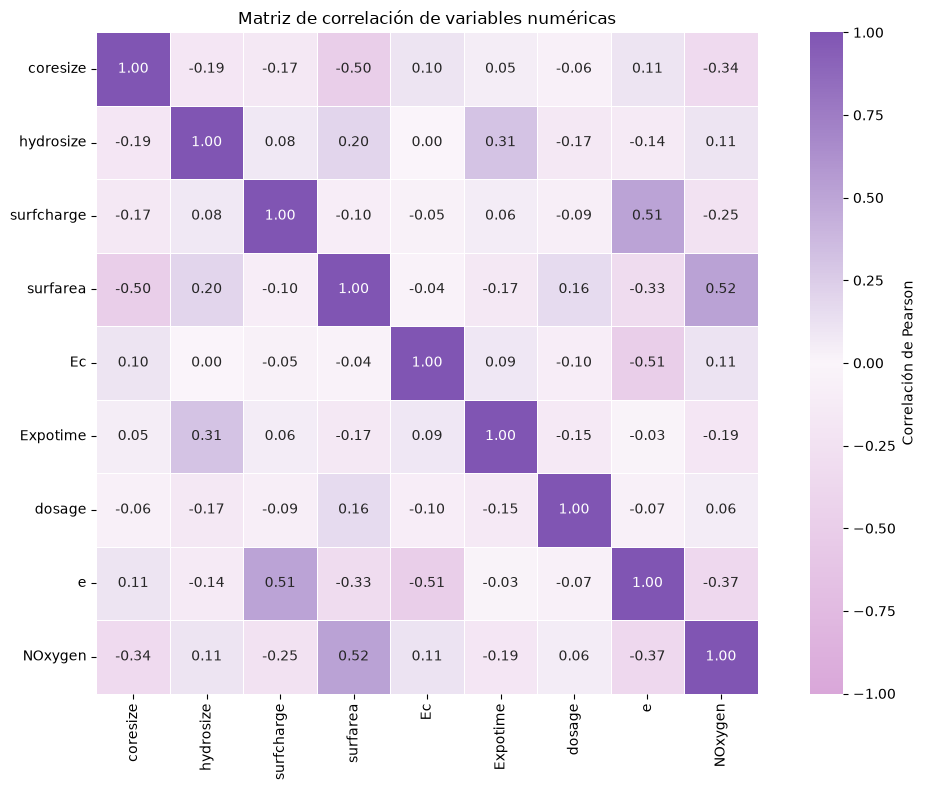

In [126]:
# Paleta de colores rosa - blanco - morad
colores = ["#D9A7D9", "#FAF5FA", "#8055B3"]

cmap_personalizado = LinearSegmentedColormap.from_list(
    "rosa_morado", colores
)

# Matriz de correlación de Pearson
correlacion = df[variables_numericas].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap=cmap_personalizado,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La matriz muestra correlaciones principalmente débiles o moderadas entre las variables numéricas. Las asociaciones más destacadas se encuentran entre `surfarea` y `NOxygen` (0.52), `surfcharge` y `e` (0.51), `Ec` y `e` (−0.51), y `coresize` y `surfarea` (−0.50). No se identifican correlaciones lineales suficientemente elevadas como para considerar alguna variable redundante de manera evidente, por lo que se conservarán todas las características para evaluar posteriormente el efecto de PCA y Mutual Information sobre el desempeño de los modelos.

### 2. Análisis y tratamiento de registros duplicados

Se examinará la presencia de registros duplicados y combinaciones de características con etiquetas contradictorias. Posteriormente, se definirán distintas estrategias de tratamiento para evaluar cómo influyen estas observaciones en el desempeño de los modelos de clasificación.

#### 2.1. Identificación y cuantificación de duplicados exactos

Se identificarán los registros completamente idénticos, considerando tanto las características predictoras como la etiqueta de toxicidad. Se cuantificarán los grupos repetidos y las observaciones excedentes para determinar la magnitud de la duplicación en el conjunto de datos.

In [127]:
# Número total de registros
n_original = len(df)

# Identificar registros pertenecientes a grupos duplicados
mascara_duplicados = df.duplicated(keep=False)
n_registros_repetidos = mascara_duplicados.sum()

# Identificar registros excedentes
n_excedentes = df.duplicated(keep="first").sum()

# Contar la frecuencia de cada registro único
frecuencias = (
    df.value_counts(dropna=False)
    .reset_index(name="frecuencia")
)

# Identificar grupos con más de una aparición
grupos_repetidos = frecuencias[
    frecuencias["frecuencia"] > 1
].copy()

# Resumen de duplicados
resumen_duplicados = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros en grupos duplicados",
        "Registros excedentes",
        "Grupos de registros repetidos",
        "Registros únicos"
    ],
    "Cantidad": [
        n_original,
        n_registros_repetidos,
        n_excedentes,
        len(grupos_repetidos),
        n_original - n_excedentes
    ]
})

resumen_duplicados["Porcentaje (%)"] = (
    resumen_duplicados["Cantidad"] / n_original * 100
).round(2)

display(resumen_duplicados)

,Indicador,Cantidad,Porcentaje (%)
0,Total de registros,881,100.00
1,Registros en grupos duplicados,657,74.57
2,Registros excedentes,487,55.28
3,Grupos de registros repetidos,170,19.30
4,Registros únicos,394,44.72


Se identificaron 657 observaciones pertenecientes a 170 grupos de registros repetidos, de las cuales 487 corresponden a copias adicionales. Esto representa el 55.28% del dataset, por lo que su eliminación reduciría las 881 observaciones originales a 394 registros únicos. La elevada proporción de duplicados hace necesario evaluar su influencia sobre el desempeño de los modelos antes de decidir cómo tratarlos.

#### 2.2. Análisis de frecuencia de duplicados

Se analizará la frecuencia de aparición de los registros repetidos para identificar si la duplicación se concentra en determinadas combinaciones de características y etiquetas de toxicidad.

,Número de grupos
frecuencia,
2,88
3,22
4,10
5,12
6,14
7,9
8,4
9,5
10,1


Los 10 registros más frecuentes:


,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,class,frecuencia
0,ZnO,115.0,360.0,-10.0,14.40,-3.89,24,50.0,1.65,1,Toxic,20
1,ZnO,35.6,295.5,-41.6,27.90,-3.89,24,10.0,1.65,1,Toxic,20
2,ZnO,35.6,295.5,-41.6,27.90,-3.89,24,100.0,1.65,1,Toxic,16
3,ZnO,115.0,500.0,-9.0,14.50,-3.89,24,50.0,1.65,1,Toxic,14
4,ZnO,100.0,273.4,-11.7,20.00,-3.89,24,80.0,1.65,1,Toxic,11
5,ZnO,115.0,360.0,-10.0,14.40,-3.89,24,30.0,1.65,1,Toxic,10
6,ZnO,115.0,500.0,-9.0,14.50,-3.89,24,80.0,1.65,1,Toxic,9
7,ZnO,60.0,936.0,-2.4,7.34,-3.89,24,20.0,1.65,1,Toxic,9
8,ZnO,52.0,640.0,29.4,15.00,-3.89,72,50.0,1.65,1,Toxic,9
9,ZnO,7.5,795.0,27.4,90.00,-3.89,24,25.0,1.65,1,Toxic,9


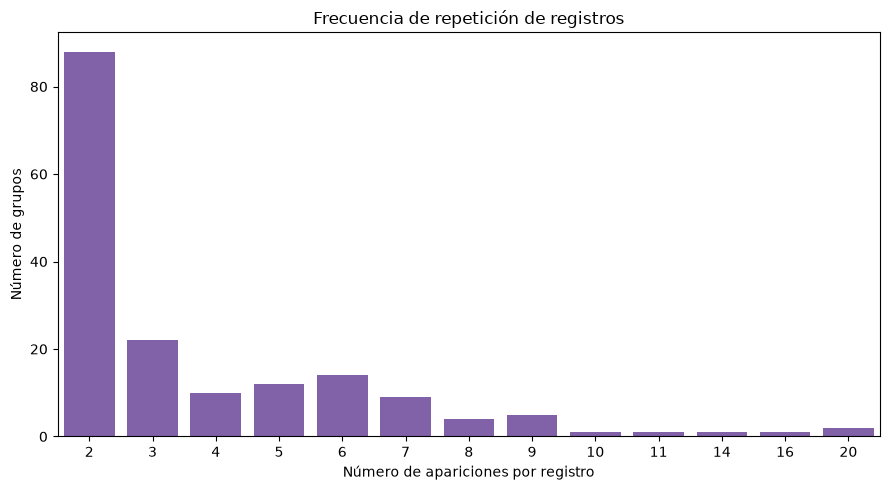

In [128]:
# Distribución de frecuencias de los grupos repetidos
distribucion_frecuencias = (
    grupos_repetidos["frecuencia"]
    .value_counts()
    .sort_index()
)

display(
    distribucion_frecuencias.to_frame("Número de grupos")
)

# Registros con mayor frecuencia de repetición
print("Los 10 registros más frecuentes:")
display(
    grupos_repetidos
    .sort_values("frecuencia", ascending=False)
    .head(10)
)

# Visualización
plt.figure(figsize=(9, 5))

sns.barplot(
    x=distribucion_frecuencias.index,
    y=distribucion_frecuencias.values,
    color="#8055B3"
)

plt.title("Frecuencia de repetición de registros")
plt.xlabel("Número de apariciones por registro")
plt.ylabel("Número de grupos")
plt.tight_layout()
plt.show()

La mayoría de los 170 grupos de registros repetidos aparecen entre dos y tres veces, aunque algunas combinaciones alcanzan hasta 20 apariciones. Los diez registros más frecuentes corresponden a nanopartículas de ZnO clasificadas como tóxicas, lo que sugiere que la duplicación podría favorecer determinadas condiciones experimentales y clases durante el entrenamiento. Por ello, será importante comparar el desempeño de los modelos con y sin registros duplicados.

#### 2.3. Identificación de etiquetas contradictorias

Se identificarán combinaciones de características predictoras que presentan diferentes etiquetas de toxicidad. Se cuantificarán estos casos y se examinará su distribución para evaluar posibles inconsistencias en el conjunto de datos.

In [129]:
# Variables predictoras
columnas_predictoras = df.columns.drop("class").tolist()

# Número de clases distintas por combinación de características
clases_por_combinacion = (
    df.groupby(columnas_predictoras, dropna=False)["class"]
    .nunique()
    .reset_index(name="n_clases")
)

# Combinaciones con etiquetas contradictorias
combinaciones_contradictorias = clases_por_combinacion[
    clases_por_combinacion["n_clases"] > 1
].copy()

# Recuperar todas las observaciones involucradas
registros_contradictorios = df.merge(
    combinaciones_contradictorias[columnas_predictoras],
    on=columnas_predictoras,
    how="inner"
)

# Resumen
print(
    "Combinaciones con etiquetas contradictorias:",
    len(combinaciones_contradictorias)
)

print(
    "Observaciones involucradas:",
    len(registros_contradictorios)
)

print(
    "Porcentaje del dataset:",
    f"{len(registros_contradictorios) / len(df) * 100:.2f}%"
)

# Distribución de clases en los registros contradictorios
display(
    registros_contradictorios["class"]
    .value_counts()
    .to_frame("Frecuencia")
)

# Resumen por combinación y etiqueta
resumen_contradicciones = (
    registros_contradictorios
    .groupby(
        columnas_predictoras + ["class"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(resumen_contradicciones)

Combinaciones con etiquetas contradictorias: 11
Observaciones involucradas: 64
Porcentaje del dataset: 7.26%


,Frecuencia
class,
Toxic,53
nonToxic,11


class,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,Toxic,nonToxic
0,ZnO,100.0,273.4,-11.7,20.0,-3.89,3,80.0,1.65,1,3,1
1,ZnO,100.0,273.4,-11.7,20.0,-3.89,6,80.0,1.65,1,6,1
2,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,25.0,1.65,1,2,1
3,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,30.0,1.65,1,5,1
4,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,35.0,1.65,1,3,1
5,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,40.0,1.65,1,5,1
6,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,25.0,1.65,1,6,1
7,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,30.0,1.65,1,7,1
8,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,35.0,1.65,1,7,1
9,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,40.0,1.65,1,5,1


Se identificaron 11 combinaciones de características con etiquetas contradictorias, que involucran 64 observaciones (7.26% del conjunto de datos). Todas corresponden a nanopartículas de ZnO y presentan una mayoría de etiquetas tóxicas (53 frente a 11 no tóxicas). Estas inconsistencias podrían introducir ambigüedad durante el aprendizaje, ya que observaciones con características idénticas tienen clasificaciones diferentes. Por ello, se evaluará posteriormente el efecto de conservar o excluir estas combinaciones, sin asumir que representan necesariamente errores de etiquetado.

#### 2.4. Impacto de los duplicados en la distribución de clases

Se comparará la distribución de toxicidad antes y después de eliminar los duplicados exactos, con el propósito de determinar si las observaciones repetidas modifican la proporción de las clases. También se analizará su distribución por tipo de nanopartícula para identificar posibles diferencias en la representación de los materiales.

,Original (%),Sin duplicados (%),Diferencia (pp)
class,,,
nonToxic,45.97,75.13,29.16
Toxic,54.03,24.87,-29.16


,Original (%),Sin duplicados (%)
NPs,,
Al2O3,2.04,4.57
CuO,5.79,9.39
Fe2O3,2.04,4.57
TiO2,22.70,31.22
ZnO,67.42,50.25


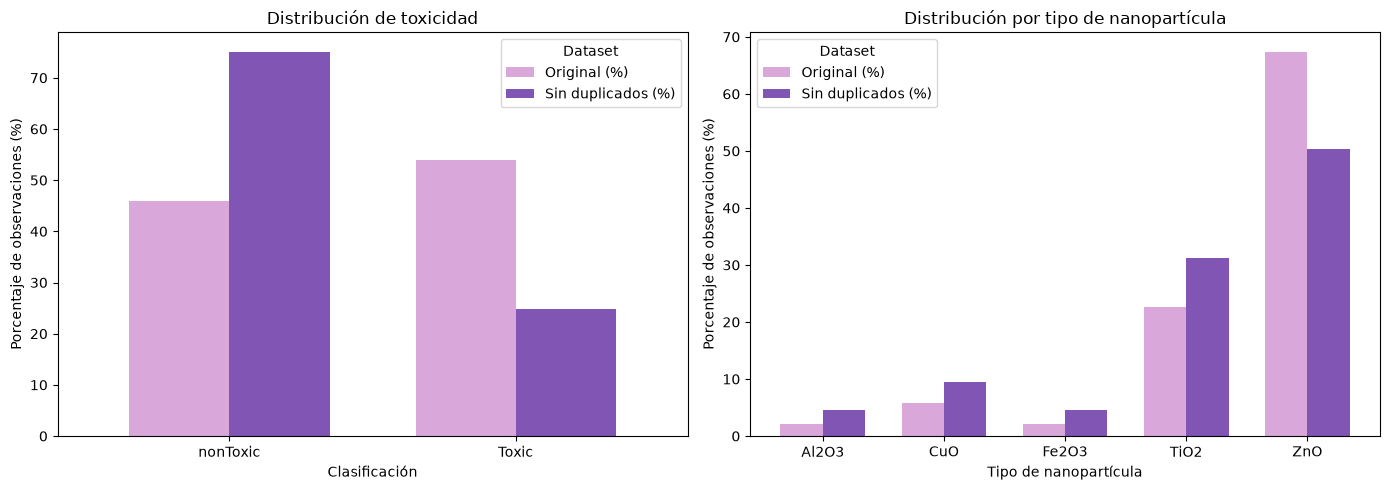

In [130]:
# Crear una versión sin duplicados exactos
df_sin_duplicados = df.drop_duplicates().copy()

# Comparar la distribución de clases
orden_clases = ["nonToxic", "Toxic"]

distribucion_original = (
    df["class"]
    .value_counts(normalize=True)
    .reindex(orden_clases, fill_value=0) * 100
)

distribucion_sin_duplicados = (
    df_sin_duplicados["class"]
    .value_counts(normalize=True)
    .reindex(orden_clases, fill_value=0) * 100
)

comparacion_clases = pd.DataFrame({
    "Original (%)": distribucion_original,
    "Sin duplicados (%)": distribucion_sin_duplicados
})

comparacion_clases["Diferencia (pp)"] = (
    comparacion_clases["Sin duplicados (%)"]
    - comparacion_clases["Original (%)"]
)

display(comparacion_clases.round(2))

# Comparar la representación de nanopartículas
orden_nps = sorted(df["NPs"].unique())

distribucion_nps = pd.DataFrame({
    "Original (%)": (
        df["NPs"].value_counts(normalize=True)
        .reindex(orden_nps, fill_value=0) * 100
    ),
    "Sin duplicados (%)": (
        df_sin_duplicados["NPs"]
        .value_counts(normalize=True)
        .reindex(orden_nps, fill_value=0) * 100
    )
})

display(distribucion_nps.round(2))

# Visualizaciones
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comparacion_clases[
    ["Original (%)", "Sin duplicados (%)"]
].plot(
    kind="bar",
    ax=axes[0],
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

axes[0].set_title("Distribución de toxicidad")
axes[0].set_xlabel("Clasificación")
axes[0].set_ylabel("Porcentaje de observaciones (%)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Dataset")

distribucion_nps.plot(
    kind="bar",
    ax=axes[1],
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

axes[1].set_title("Distribución por tipo de nanopartícula")
axes[1].set_xlabel("Tipo de nanopartícula")
axes[1].set_ylabel("Porcentaje de observaciones (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Dataset")

plt.tight_layout()
plt.show()

La eliminación de duplicados produjo cambios importantes en la composición del conjunto de datos. La proporción de observaciones tóxicas disminuyó del 54.03% al 24.87%, mientras que la representación de ZnO se redujo del 67.42% al 50.25%. Estos resultados muestran que los registros repetidos favorecen determinadas clases y materiales, por lo que su presencia podría influir en el aprendizaje y la evaluación de los modelos.

#### 2.5. Definición de estrategias de tratamiento de datos

Se definirán cuatro estrategias de tratamiento:

- **Original:** se conservarán todas las observaciones.
- **Sin contradicciones:** se excluirán las combinaciones de características con etiquetas contradictorias, conservando los duplicados restantes.
- **Sin duplicados:** se eliminarán los registros exactamente iguales.
- **Sin duplicados ni contradicciones:** se eliminarán los registros duplicados y las combinaciones con etiquetas contradictorias.

Estas estrategias permitirán evaluar de manera independiente y conjunta el efecto de los duplicados y las contradicciones sobre el desempeño predictivo.

Los tratamientos se aplicarán únicamente a los datos de entrenamiento, manteniendo las observaciones de evaluación sin modificaciones para garantizar una comparación consistente.

In [131]:
# Estrategias de tratamiento de datos

def tratar_duplicados(df_train, estrategia="original"):
    """
    Aplica una estrategia de tratamiento a los datos.

    Estrategias:
    - original
    - sin_contradicciones
    - sin_duplicados
    - sin_duplicados_ni_contradicciones
    """

    datos = df_train.copy()

    if estrategia == "original":
        return datos

    elif estrategia == "sin_duplicados":
        return datos.drop_duplicates().copy()

    elif estrategia in [
        "sin_contradicciones",
        "sin_duplicados_ni_contradicciones"
    ]:

        # Eliminar duplicados solo cuando corresponda
        if estrategia == "sin_duplicados_ni_contradicciones":
            datos = datos.drop_duplicates().copy()

        # Identificar variables predictoras
        predictores = datos.columns.drop("class").tolist()

        # Contar etiquetas distintas por combinación
        n_clases = datos.groupby(
            predictores,
            dropna=False
        )["class"].transform("nunique")

        # Conservar combinaciones sin contradicciones
        return datos.loc[n_clases == 1].copy()

    else:
        raise ValueError(
            f"Estrategia no reconocida: {estrategia}"
        )


# Definir las cuatro estrategias
estrategias = [
    "original",
    "sin_contradicciones",
    "sin_duplicados",
    "sin_duplicados_ni_contradicciones"
]


# Comparación descriptiva de las estrategias
resumen_estrategias = []

for estrategia in estrategias:

    datos = tratar_duplicados(df, estrategia)

    resumen_estrategias.append({
        "Estrategia": estrategia,
        "Registros": len(datos),
        "Registros eliminados": len(df) - len(datos),
        "Toxic (%)": round(
            (datos["class"] == "Toxic").mean() * 100, 2
        ),
        "nonToxic (%)": round(
            (datos["class"] == "nonToxic").mean() * 100, 2
        )
    })


# Mostrar resultados
resumen_estrategias = pd.DataFrame(resumen_estrategias)

display(resumen_estrategias)

,Estrategia,Registros,Registros eliminados,Toxic (%),nonToxic (%)
0,original,881,0,54.03,45.97
1,sin_contradicciones,817,64,51.77,48.23
2,sin_duplicados,394,487,24.87,75.13
3,sin_duplicados_ni_contradicciones,372,509,23.39,76.61


La eliminación exclusiva de contradicciones redujo el conjunto de datos de 881 a 817 observaciones, manteniendo una distribución de clases relativamente equilibrada (51.77% de registros tóxicos y 48.23% de no tóxicos). En contraste, la eliminación de duplicados produjo un desbalance considerable, reduciendo la proporción de registros tóxicos al 24.87%. Al eliminar tanto duplicados como contradicciones, esta proporción disminuyó al 23.39%.

Estos resultados indicaron que los duplicados tuvieron un mayor impacto sobre la distribución de clases que las contradicciones. Por ello, se considerará la aplicación de técnicas de balanceo principalmente en las variantes que eliminen duplicados, previa comprobación de la distribución en cada pliegue de entrenamiento.

### 3. Preparación de datos y estrategia de validación

Se definirán las variables predictoras, la variable objetivo y los grupos de observaciones relacionadas. Posteriormente, se establecerá una estrategia de validación cruzada estratificada por grupos para reducir el riesgo de fuga de información y garantizar que los tratamientos de duplicados se evalúen sobre particiones comparables.

#### 3.1. Definición de variables predictoras y variable objetivo

Se separarán las nueve variables numéricas y la variable categórica `NPs` de la variable objetivo `class`. Esta última se codificará de forma binaria, asignando 1 a las observaciones tóxicas y 0 a las no tóxicas.

In [132]:
# Variables predictoras
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

variables_categoricas = ["NPs"]

columnas_predictoras = (
    variables_numericas + variables_categoricas
)

X = df[columnas_predictoras].copy()

# Codificación de la variable objetivo
y = df["class"].map({
    "nonToxic": 0,
    "Toxic": 1
})

# Verificar que no existan etiquetas desconocidas
assert y.notna().all(), (
    "Se encontraron etiquetas de toxicidad no reconocidas."
)

y = y.astype(int)

# Resumen
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de clases:")
display(
    y.value_counts()
    .rename(index={0: "nonToxic", 1: "Toxic"})
    .to_frame("Frecuencia")
)

print("\nVariables predictoras:")
display(pd.DataFrame({
    "Variable": columnas_predictoras,
    "Tipo": (
        ["Numérica"] * len(variables_numericas)
        + ["Categórica"] * len(variables_categoricas)
    )
}))

Dimensiones de X: (881, 10)
Dimensiones de y: (881,)

Distribución de clases:


,Frecuencia
class,
Toxic,476
nonToxic,405



Variables predictoras:


,Variable,Tipo
0,coresize,Numérica
1,hydrosize,Numérica
2,surfcharge,Numérica
3,surfarea,Numérica
4,Ec,Numérica
5,Expotime,Numérica
6,dosage,Numérica
7,e,Numérica
8,NOxygen,Numérica
9,NPs,Categórica


#### 3.2. Identificación de grupos de observaciones relacionadas

Se agruparán las observaciones que compartan el mismo tipo de nanopartícula y las mismas propiedades fisicoquímicas, sin considerar la dosis ni el tiempo de exposición. Estos grupos se utilizarán durante la validación cruzada para mantener separadas las observaciones relacionadas y reducir el riesgo de fuga de información.

In [133]:
# Características utilizadas para identificar grupos
columnas_grupo = [
    "NPs", "coresize", "hydrosize",
    "surfcharge", "surfarea", "Ec",
    "e", "NOxygen"
]

# Crear identificadores de grupo sobre el dataset original
groups = pd.Series(
    df.groupby(
        columnas_grupo,
        dropna=False,
        sort=False
    ).ngroup(),
    index=df.index,
    name="grupo"
)

# Resumen de los grupos
resumen_grupos = (
    df.assign(grupo=groups)
    .groupby("grupo")
    .agg(
        registros=("class", "size"),
        toxicos=("class", lambda x: (x == "Toxic").sum()),
        no_toxicos=("class", lambda x: (x == "nonToxic").sum()),
        nanoparticula=("NPs", "first")
    )
    .sort_values("registros", ascending=False)
)

print("Número de grupos:", groups.nunique())
print("Tamaño mínimo:", resumen_grupos["registros"].min())
print("Tamaño máximo:", resumen_grupos["registros"].max())

print("\nLos 10 grupos más grandes:")
display(resumen_grupos.head(10))

# Verificar que registros con predictores idénticos
# no pertenezcan a grupos diferentes
verificacion = (
    df.assign(grupo=groups)
    .groupby(columnas_predictoras, dropna=False)["grupo"]
    .nunique()
)

assert verificacion.max() == 1, (
    "Existen observaciones idénticas en grupos diferentes."
)

print("\nVerificación de grupos: correcta.")

Número de grupos: 42
Tamaño mínimo: 1
Tamaño máximo: 119

Los 10 grupos más grandes:


,registros,toxicos,no_toxicos,nanoparticula
grupo,,,,
22,119,60,59,ZnO
27,55,50,5,ZnO
26,54,39,15,ZnO
25,53,39,14,ZnO
24,51,36,15,ZnO
4,48,0,48,TiO2
3,48,0,48,TiO2
23,47,32,15,ZnO
17,42,38,4,ZnO



Verificación de grupos: correcta.


Se identificaron 42 grupos de observaciones con características fisicoquímicas compartidas, cuyos tamaños varían entre 1 y 119 registros. Los grupos más grandes corresponden principalmente a ZnO y presentan diferentes proporciones de toxicidad. Esta heterogeneidad deberá considerarse al construir las particiones de validación, ya que podría dificultar el equilibrio de clases entre pliegues. La verificación confirmó que las observaciones con características predictoras idénticas permanecen dentro del mismo grupo.

#### 3.3. Construcción y verificación de las particiones de validación

Se utilizará validación cruzada estratificada por grupos (`StratifiedGroupKFold`) con cinco pliegues. Se verificará la distribución de clases y el número de observaciones en cada partición, así como la ausencia de grupos compartidos entre entrenamiento y validación.

Las mismas particiones se utilizarán posteriormente para comparar las estrategias de tratamiento de duplicados y los distintos modelos de clasificación.

In [134]:
# Configuración de validación cruzada
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Guardar las particiones para reutilizarlas
particiones_cv = list(
    cv.split(X, y, groups=groups)
)

resumen_cv = []

for i, (idx_train, idx_val) in enumerate(particiones_cv, 1):

    y_train = y.iloc[idx_train]
    y_val = y.iloc[idx_val]

    grupos_train = set(groups.iloc[idx_train])
    grupos_val = set(groups.iloc[idx_val])

    # Verificar ausencia de grupos compartidos
    grupos_compartidos = grupos_train.intersection(grupos_val)

    resumen_cv.append({
        "Pliegue": i,
        "Entrenamiento": len(idx_train),
        "Validación": len(idx_val),
        "Grupos train": len(grupos_train),
        "Grupos val": len(grupos_val),
        "Toxic train (%)": round(y_train.mean() * 100, 2),
        "Toxic val (%)": round(y_val.mean() * 100, 2),
        "Clases train": y_train.nunique(),
        "Clases val": y_val.nunique(),
        "Grupos compartidos": len(grupos_compartidos)
    })

resumen_cv = pd.DataFrame(resumen_cv)

display(resumen_cv)

# Verificaciones
assert (resumen_cv["Grupos compartidos"] == 0).all(), (
    "Se detectaron grupos compartidos."
)

assert (resumen_cv["Clases train"] == 2).all(), (
    "Algún entrenamiento contiene una sola clase."
)

assert (resumen_cv["Clases val"] == 2).all(), (
    "Alguna validación contiene una sola clase."
)

# Verificar que cada observación aparezca una vez en validación
indices_validacion = np.concatenate(
    [idx_val for _, idx_val in particiones_cv]
)

assert len(indices_validacion) == len(X)
assert len(np.unique(indices_validacion)) == len(X)

print("\nVerificación de particiones completada.")


,Pliegue,Entrenamiento,Validación,Grupos train,Grupos val,Toxic train (%),Toxic val (%),Clases train,Clases val,Grupos compartidos
0,1,724,157,34,8,54.56,51.59,2,2,0
1,2,731,150,35,7,53.63,56.00,2,2,0
2,3,729,152,33,9,54.05,53.95,2,2,0
3,4,613,268,32,10,54.49,52.99,2,2,0
4,5,727,154,34,8,53.51,56.49,2,2,0



Verificación de particiones completada.


Las cinco particiones conservaron ambas clases y presentaron proporciones de toxicidad relativamente similares, entre 51.59% y 56.49%. No se identificaron grupos compartidos entre entrenamiento y validación, lo que reduce el riesgo de fuga de información entre observaciones relacionadas. Aunque los tamaños de los pliegues fueron diferentes debido a la distribución de los grupos, las particiones resultaron adecuadas para continuar con la evaluación de los modelos.

#### 3.4. Aplicación de las estrategias de tratamiento en las particiones

Se aplicarán las cuatro estrategias de tratamiento de duplicados y contradicciones únicamente a los conjuntos de entrenamiento de cada pliegue. Se comparará el número de observaciones y la distribución de clases resultantes para determinar la necesidad de aplicar técnicas de balanceo. Los conjuntos de validación permanecerán sin modificaciones, garantizando las mismas condiciones de evaluación para las cuatro estrategias.

In [135]:
# Comparación de estrategias dentro de los pliegues

resultados_tratamiento = []

for i, (idx_train, idx_val) in enumerate(particiones_cv, 1):

    # Recuperar entrenamiento original
    df_train = df.iloc[idx_train].copy()

    # Validación sin modificaciones
    df_val = df.iloc[idx_val].copy()

    for estrategia in estrategias:

        # Aplicar tratamiento solo al entrenamiento
        df_train_tratado = tratar_duplicados(
            df_train,
            estrategia
        )

        resultados_tratamiento.append({
            "Pliegue": i,
            "Estrategia": estrategia,
            "Registros train": len(df_train_tratado),
            "Registros eliminados": (
                len(df_train) - len(df_train_tratado)
            ),
            "Registros val": len(df_val),
            "Toxic train (%)": round(
                (df_train_tratado["class"] == "Toxic").mean()
                * 100, 2
            ),
            "nonToxic train (%)": round(
                (df_train_tratado["class"] == "nonToxic").mean()
                * 100, 2
            ),
            "Toxic val (%)": round(
                (df_val["class"] == "Toxic").mean()
                * 100, 2
            ),
            "Clases train": df_train_tratado["class"].nunique()
        })

# Tabla comparativa
resultados_tratamiento = pd.DataFrame(
    resultados_tratamiento
)

display(resultados_tratamiento)

# Resumen por estrategia
resumen_tratamiento_cv = (
    resultados_tratamiento
    .groupby("Estrategia")
    .agg({
        "Registros train": ["mean", "min", "max"],
        "Registros eliminados": ["mean"],
        "Toxic train (%)": ["mean", "std", "min", "max"]
    })
    .reindex(estrategias)
    .round(2)
)

print("\nResumen por estrategia:")
display(resumen_tratamiento_cv)

# Verificaciones

# Cuatro estrategias por cada uno de los cinco pliegues
assert len(resultados_tratamiento) == (
    len(particiones_cv) * len(estrategias)
)

# Todos los entrenamientos deben conservar ambas clases
assert (
    resultados_tratamiento["Clases train"] == 2
).all(), "Algún entrenamiento contiene una sola clase."

# Verificar que la validación permanece sin modificaciones
assert (
    resultados_tratamiento
    .groupby("Pliegue")["Registros val"]
    .nunique() == 1
).all()

assert (
    resultados_tratamiento
    .groupby("Pliegue")["Toxic val (%)"]
    .nunique() == 1
).all()

print("\nVerificación de tratamientos completada.")

,Pliegue,Estrategia,Registros train,Registros eliminados,Registros val,Toxic train (%),nonToxic train (%),Toxic val (%),Clases train
0,1,original,724,0,157,54.56,45.44,51.59,2
1,1,sin_contradicciones,660,64,157,51.82,48.18,51.59,2
2,1,sin_duplicados,319,405,157,23.51,76.49,51.59,2
3,1,sin_duplicados_ni_contradicciones,297,427,157,21.55,78.45,51.59,2
4,2,original,731,0,150,53.63,46.37,56.00,2
5,2,sin_contradicciones,667,64,150,50.82,49.18,56.00,2
6,2,sin_duplicados,330,401,150,26.36,73.64,56.00,2
7,2,sin_duplicados_ni_contradicciones,308,423,150,24.68,75.32,56.00,2
8,3,original,729,0,152,54.05,45.95,53.95,2
9,3,sin_contradicciones,665,64,152,51.28,48.72,53.95,2



Resumen por estrategia:


Registros train            \
                                             mean  min  max   
Estrategia                                                    
original                                    704.8  613  731   
sin_contradicciones                         653.6  608  668   
sin_duplicados                              315.2  287  330   
sin_duplicados_ni_contradicciones           297.6  285  308   

                                  Registros eliminados Toxic train (%)        \
                                                  mean            mean   std   
Estrategia                                                                     
original                                           0.0           54.05  0.48   
sin_contradicciones                               51.2           51.82  1.43   
sin_duplicados                                   389.6           24.88  1.62   
sin_duplicados_ni_contradicciones                407.2           23.40  2.03   

                                                 
                                     min    max  
Estrategia                                       
original                           53.51  54.56  
sin_contradicciones                50.82  54.28  
sin_duplicados                     22.84  26.36  
sin_duplicados_ni_contradicciones  20.86  25.26


Verificación de tratamientos completada.


Los resultados mostraron que las estrategias original y sin contradicciones conservaron una distribución equilibrada de clases en todos los pliegues de entrenamiento, con proporciones promedio de observaciones tóxicas de 54.05% y 51.82%, respectivamente.

Por el contrario, las estrategias que eliminaron duplicados presentaron un desbalance considerable. Con esto en mente, se decidió aplicar técnicas de balanceo únicamente a las dos estrategias que eliminaron duplicados, manteniendo las mismas particiones de validación para todos los experimentos.

### 4. Representación de características

Se compararán tres estrategias de representación: conservar las características originales, aplicar reducción de dimensionalidad mediante PCA y realizar selección de características mediante Mutual Information. El objetivo será determinar cómo influyen estas técnicas en el desempeño de los modelos y cuáles resultan más adecuadas para la predicción de toxicidad.

#### 4.1. Representación sin reducción de dimensionalidad

Se construirá una representación que conservará todas las características predictoras del conjunto de datos. Las variables numéricas se estandarizarán mediante `StandardScaler`, mientras que la variable categórica `NPs` se transformará mediante `OneHotEncoder`.

Esta representación servirá como referencia para evaluar posteriormente el efecto de PCA y Mutual Information sobre el desempeño de los modelos.

In [136]:
# Pipeline para variables numéricas
pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Representación sin reducción de dimensionalidad
preprocesamiento_base = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, variables_numericas),
        ("cat", pipeline_categorico, variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento base definido correctamente.")

Preprocesamiento base definido correctamente.


In [137]:
# Primer pliegue de validación
idx_train, idx_val = particiones_cv[0]

X_train = X.iloc[idx_train]
X_val = X.iloc[idx_val]

# Crear una copia independiente del preprocesamiento
preprocesador_prueba = clone(preprocesamiento_base)

# Ajustar únicamente con entrenamiento
X_train_transformado = preprocesador_prueba.fit_transform(
    X_train
)

# Transformar validación sin volver a ajustar
X_val_transformado = preprocesador_prueba.transform(
    X_val
)

# Nombres de las características resultantes
nombres_caracteristicas = (
    preprocesador_prueba.get_feature_names_out()
)

print("Dimensiones originales:", X_train.shape)
print("Dimensiones transformadas:", X_train_transformado.shape)
print("Dimensiones de validación:", X_val_transformado.shape)

print("\nCaracterísticas resultantes:")
display(pd.DataFrame({
    "Característica": nombres_caracteristicas
}))

# Verificaciones
assert X_train_transformado.shape[1] == X_val_transformado.shape[1]
assert np.isfinite(X_train_transformado).all()
assert np.isfinite(X_val_transformado).all()

print("\nVerificación completada correctamente.")

Dimensiones originales: (724, 10)
Dimensiones transformadas: (724, 14)
Dimensiones de validación: (157, 14)

Características resultantes:


,Característica
0,coresize
1,hydrosize
2,surfcharge
3,surfarea
4,Ec
5,Expotime
6,dosage
7,e
8,NOxygen
9,NPs_Al2O3



Verificación completada correctamente.


El preprocesamiento generó 14 características a partir de las 10 variables predictoras originales: nueve variables numéricas estandarizadas y cinco columnas binarias correspondientes a los tipos de nanopartículas. Las dimensiones fueron consistentes entre entrenamiento y validación, confirmando que la representación puede aplicarse a ambos conjuntos sin modificar su estructura.

#### 4.2. Reducción de dimensionalidad mediante PCA

El Análisis de Componentes Principales (PCA) permite reducir la dimensionalidad mediante la transformación de las variables originales en componentes ortogonales que conservan la mayor cantidad posible de varianza (Jolliffe & Cadima, 2016). Se aplicará PCA sobre las variables numéricas estandarizadas, conservando los componentes necesarios para explicar al menos el 95% de la varianza acumulada. La variable categórica `NPs` se mantendrá mediante One-Hot Encoding.

Se examinará la cantidad de componentes seleccionados y la varianza explicada para determinar el grado de reducción alcanzado.

Preprocesamiento con PCA definido correctamente.
Componentes seleccionados: 7
Varianza acumulada: 95.07%
Dimensiones transformadas: (724, 12)
Dimensiones de validación: (157, 12)


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,27.29,27.29
1,PC2,16.99,44.28
2,PC3,15.98,60.26
3,PC4,11.91,72.17
4,PC5,10.02,82.19
5,PC6,7.08,89.27
6,PC7,5.81,95.07


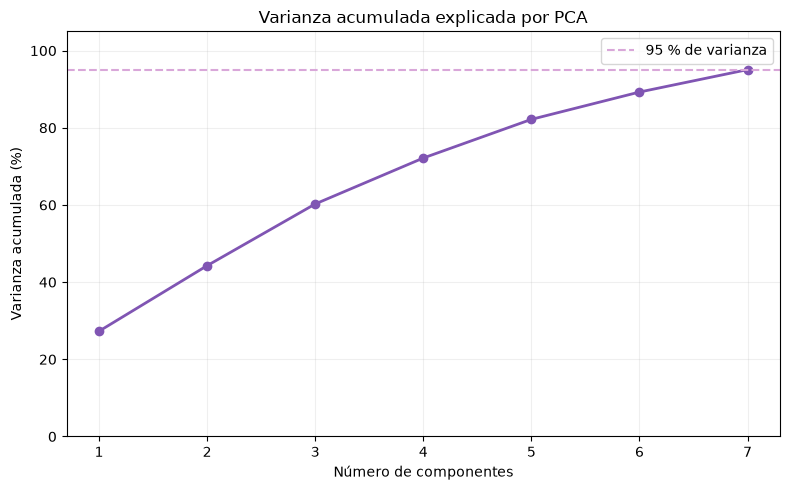

In [138]:
# Pipeline numérico con PCA
pipeline_numerico_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95))
])

# Representación con PCA
preprocesamiento_pca = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_pca, variables_numericas),
        ("cat", clone(pipeline_categorico), variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento con PCA definido correctamente.")

# Ajustar PCA únicamente con entrenamiento
preprocesador_pca_prueba = clone(preprocesamiento_pca)

X_train_pca = preprocesador_pca_prueba.fit_transform(X_train)
X_val_pca = preprocesador_pca_prueba.transform(X_val)

# Recuperar el PCA ajustado
pca_ajustado = (
    preprocesador_pca_prueba
    .named_transformers_["num"]
    .named_steps["pca"]
)

# Varianza explicada
varianza = pca_ajustado.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)

tabla_pca = pd.DataFrame({
    "Componente": [
        f"PC{i+1}" for i in range(len(varianza))
    ],
    "Varianza explicada (%)": varianza * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

print("Componentes seleccionados:", pca_ajustado.n_components_)
print("Varianza acumulada:", f"{varianza_acumulada[-1]*100:.2f}%")
print("Dimensiones transformadas:", X_train_pca.shape)
print("Dimensiones de validación:", X_val_pca.shape)

display(tabla_pca.round(2))

# Visualización
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada * 100,
    marker="o",
    color="#8055B3",
    linewidth=2
)

plt.axhline(
    y=95,
    color="#D9A7D9",
    linestyle="--",
    label="95 % de varianza"
)

plt.title("Varianza acumulada explicada por PCA")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada (%)")
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


PCA permitió reducir las nueve variables numéricas a siete componentes principales, conservando aproximadamente el 95% de la varianza acumulada. Al mantener las cinco variables binarias correspondientes al tipo de nanopartícula, la representación pasó de 14 a 12 características. Aunque la reducción fue relativamente pequeña, esta representación permitirá evaluar si la transformación de las variables originales mejora el desempeño predictivo de los modelos.

#### 4.3. Selección de características mediante Mutual Information

La información mutua permite cuantificar la dependencia estadística entre variables, incluyendo relaciones no lineales, por lo que puede utilizarse como criterio de selección de características (Guyon & Elisseeff, 2003; Kraskov et al., 2004). Se utilizará Mutual Information para estimar la dependencia entre las variables numéricas y la clasificación de toxicidad. A partir de estos valores, se seleccionarán las características con mayor información predictiva, conservando por separado la codificación de la variable categórica `NPs`.

La selección se integrará posteriormente en los pipelines para evitar utilizar información de los conjuntos de validación durante el entrenamiento.

In [139]:
# Configurar Mutual Information para variables continuas
mi_score = partial(
    mutual_info_classif,
    discrete_features=False,
    random_state=42
)

# Pipeline numérico con selección de características
pipeline_numerico_mi = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(
        score_func=mi_score,
        k=5
    ))
])

# Representación con Mutual Information
preprocesamiento_mi = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_mi, variables_numericas),
        ("cat", clone(pipeline_categorico), variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento con Mutual Information definido correctamente.")

Preprocesamiento con Mutual Information definido correctamente.


,Variable,Mutual Information,Seleccionada
1,hydrosize,0.3086,True
6,dosage,0.2902,True
0,coresize,0.2722,True
2,surfcharge,0.2672,True
3,surfarea,0.2549,True
7,e,0.2509,False
4,Ec,0.2236,False
8,NOxygen,0.2106,False
5,Expotime,0.0353,False


Dimensiones transformadas: (724, 10)
Dimensiones de validación: (157, 10)


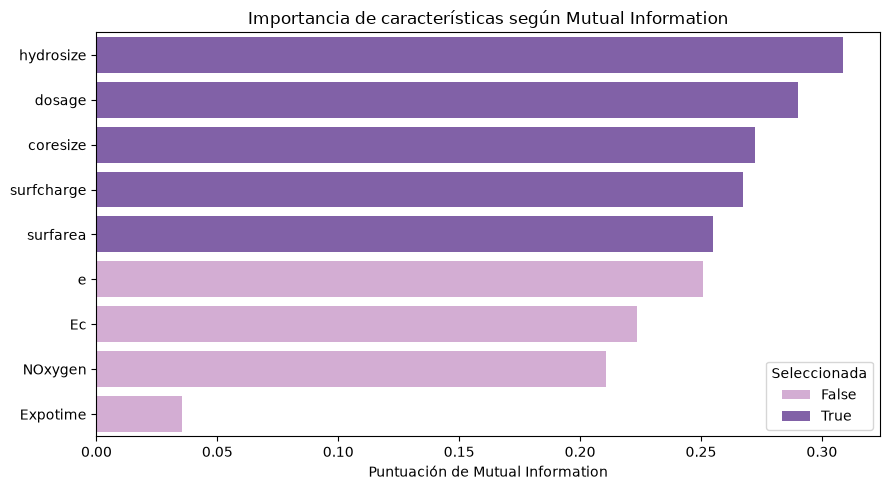

In [140]:
# Ajustar MI solo con entrenamiento
preprocesador_mi_prueba = clone(preprocesamiento_mi)

X_train_mi = preprocesador_mi_prueba.fit_transform(
    X_train,
    y.iloc[idx_train]
)

X_val_mi = preprocesador_mi_prueba.transform(X_val)

# Recuperar selector ajustado
selector_mi = (
    preprocesador_mi_prueba
    .named_transformers_["num"]
    .named_steps["selector"]
)

# Tabla de puntuaciones
tabla_mi = pd.DataFrame({
    "Variable": variables_numericas,
    "Mutual Information": selector_mi.scores_,
    "Seleccionada": selector_mi.get_support()
}).sort_values(
    "Mutual Information",
    ascending=False
)

display(tabla_mi.round(4))

print("Dimensiones transformadas:", X_train_mi.shape)
print("Dimensiones de validación:", X_val_mi.shape)

# Visualización
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabla_mi,
    x="Mutual Information",
    y="Variable",
    hue="Seleccionada",
    palette={
        True: "#8055B3",
        False: "#D9A7D9"
    },
    dodge=False
)

plt.title("Importancia de características según Mutual Information")
plt.xlabel("Puntuación de Mutual Information")
plt.ylabel("")
plt.legend(title="Seleccionada")
plt.tight_layout()
plt.show()

Mutual Information identificó a `hydrosize`, `dosage`, `coresize`, `surfcharge` y `surfarea` como las cinco variables numéricas con mayor dependencia respecto a la clasificación de toxicidad. En contraste, `Expotime` presentó la puntuación más baja. La selección redujo la representación de 14 a 10 características, conservando las cinco variables binarias correspondientes al tipo de nanopartícula. Estos resultados sugieren que las propiedades relacionadas con el tamaño y la superficie, así como la dosis, podrían ser relevantes para la predicción, aunque su utilidad deberá confirmarse mediante la evaluación de los modelos.

### 5. Balanceo de clases

Debido a que la eliminación de duplicados modificó considerablemente la distribución de toxicidad, se evaluarán tres estrategias de balanceo: sin balanceo, sobremuestreo aleatorio (*RandomOverSampler*) y generación de observaciones sintéticas mediante SMOTENC.

El objetivo será determinar si el balanceo mejora la capacidad de los modelos para identificar nanopartículas tóxicas y comparar el efecto de ambas técnicas de sobremuestreo. Estas estrategias se aplicarán únicamente a los conjuntos de entrenamiento de cada partición, evitando introducir información artificial en los datos de validación.

#### 5.1. Definición de las estrategias de balanceo

Se compararán tres estrategias: sin balanceo, sobremuestreo aleatorio mediante RandomOverSampler y generación de observaciones sintéticas mediante SMOTENC.
- **Random Oversampling:** técnica de balanceo que consiste en incrementar el número de observaciones de la clase minoritaria mediante el muestreo aleatorio con reemplazo de registros existentes, sin generar nuevas combinaciones de características (He & Garcia, 2009).

- **SMOTE-NC (Synthetic Minority Over-sampling Technique for Nominal and Continuous features):** variante de SMOTE diseñada para conjuntos de datos con características numéricas y categóricas, que genera observaciones sintéticas de la clase minoritaria considerando las características de sus vecinos más cercanos (Chawla et al., 2002).

In [141]:
# Índice de la variable categórica NPs
indice_categorico = [
    columnas_predictoras.index("NPs")
]

# Definir estrategias de balanceo
estrategias_balanceo = {
    "sin_balanceo": None,

    "oversampling": RandomOverSampler(
        sampling_strategy="auto",
        random_state=42
    ),

    "SMOTENC": SMOTENC(
        categorical_features=indice_categorico,
        sampling_strategy="auto",
        random_state=42,
        k_neighbors=3
    )
}

# Verificar estrategias
print("Estrategias de balanceo definidas:")

for nombre in estrategias_balanceo:
    print("-", nombre)

print("\nÍndice categórico:", indice_categorico)


Estrategias de balanceo definidas:
- sin_balanceo
- oversampling
- SMOTENC

Índice categórico: [9]


#### 5.2. Verificación del balanceo de clases

Debido a que las estrategias original y sin contradicciones presentan una distribución equilibrada de clases, se conservarán sin aplicar técnicas de sobremuestreo. En cambio, para las estrategias sin duplicados y sin duplicados ni contradicciones, se compararán tres configuraciones: sin balanceo, RandomOverSampler y SMOTENC.

Se analizarán los cambios en la distribución de clases utilizando únicamente los datos de entrenamiento, con el propósito de verificar el funcionamiento de las técnicas antes de incorporarlas a los modelos de clasificación.

In [142]:
# Definir balanceos permitidos por estrategia
balanceos_por_estrategia = {
    "original": [
        "sin_balanceo"
    ],
    "sin_contradicciones": [
        "sin_balanceo"
    ],
    "sin_duplicados": [
        "sin_balanceo",
        "oversampling",
        "SMOTENC"
    ],
    "sin_duplicados_ni_contradicciones": [
        "sin_balanceo",
        "oversampling",
        "SMOTENC"
    ]
}

# Primer pliegue de entrenamiento
idx_train, idx_val = particiones_cv[0]
df_train = df.iloc[idx_train].copy()

resultados_balanceo = []

for estrategia_dup in estrategias:

    # Aplicar tratamiento de datos
    datos = tratar_duplicados(
        df_train,
        estrategia_dup
    )

    X_train_bal = datos[X.columns].copy()

    y_train_bal = datos["class"].map({
        "nonToxic": 0,
        "Toxic": 1
    }).astype(int)

    # Recuperar balanceos permitidos
    balanceos = balanceos_por_estrategia[estrategia_dup]

    # Imputar valores faltantes solo en entrenamiento
    imputador = SimpleImputer(strategy="median")

    X_train_bal[variables_numericas] = (
        imputador.fit_transform(
            X_train_bal[variables_numericas]
        )
    )

    X_train_bal["NPs"] = (
        X_train_bal["NPs"].fillna(
            X_train_bal["NPs"].mode().iloc[0]
        )
    )

    for nombre_balanceo in balanceos:

        sampler = estrategias_balanceo[nombre_balanceo]

        if sampler is None:
            y_res = y_train_bal.copy()

        else:
            sampler_actual = clone(sampler)

            _, y_res = sampler_actual.fit_resample(
                X_train_bal,
                y_train_bal
            )

        conteos = pd.Series(y_res).value_counts()

        resultados_balanceo.append({
            "Tratamiento duplicados": estrategia_dup,
            "Balanceo": nombre_balanceo,
            "Registros": len(y_res),
            "nonToxic": conteos.get(0, 0),
            "Toxic": conteos.get(1, 0),
            "Toxic (%)": round(
                conteos.get(1, 0) / len(y_res) * 100,
                2
            )
        })

# Tabla comparativa
resultados_balanceo = pd.DataFrame(
    resultados_balanceo
)

display(resultados_balanceo)

# Verificar número de configuraciones
assert len(resultados_balanceo) == 8

print(
    "\nConfiguraciones de tratamiento y balanceo:",
    len(resultados_balanceo)
)

,Tratamiento duplicados,Balanceo,Registros,nonToxic,Toxic,Toxic (%)
0,original,sin_balanceo,724,329,395,54.56
1,sin_contradicciones,sin_balanceo,660,318,342,51.82
2,sin_duplicados,sin_balanceo,319,244,75,23.51
3,sin_duplicados,oversampling,488,244,244,50.00
4,sin_duplicados,SMOTENC,488,244,244,50.00
5,sin_duplicados_ni_contradicciones,sin_balanceo,297,233,64,21.55
6,sin_duplicados_ni_contradicciones,oversampling,466,233,233,50.00
7,sin_duplicados_ni_contradicciones,SMOTENC,466,233,233,50.00



Configuraciones de tratamiento y balanceo: 8


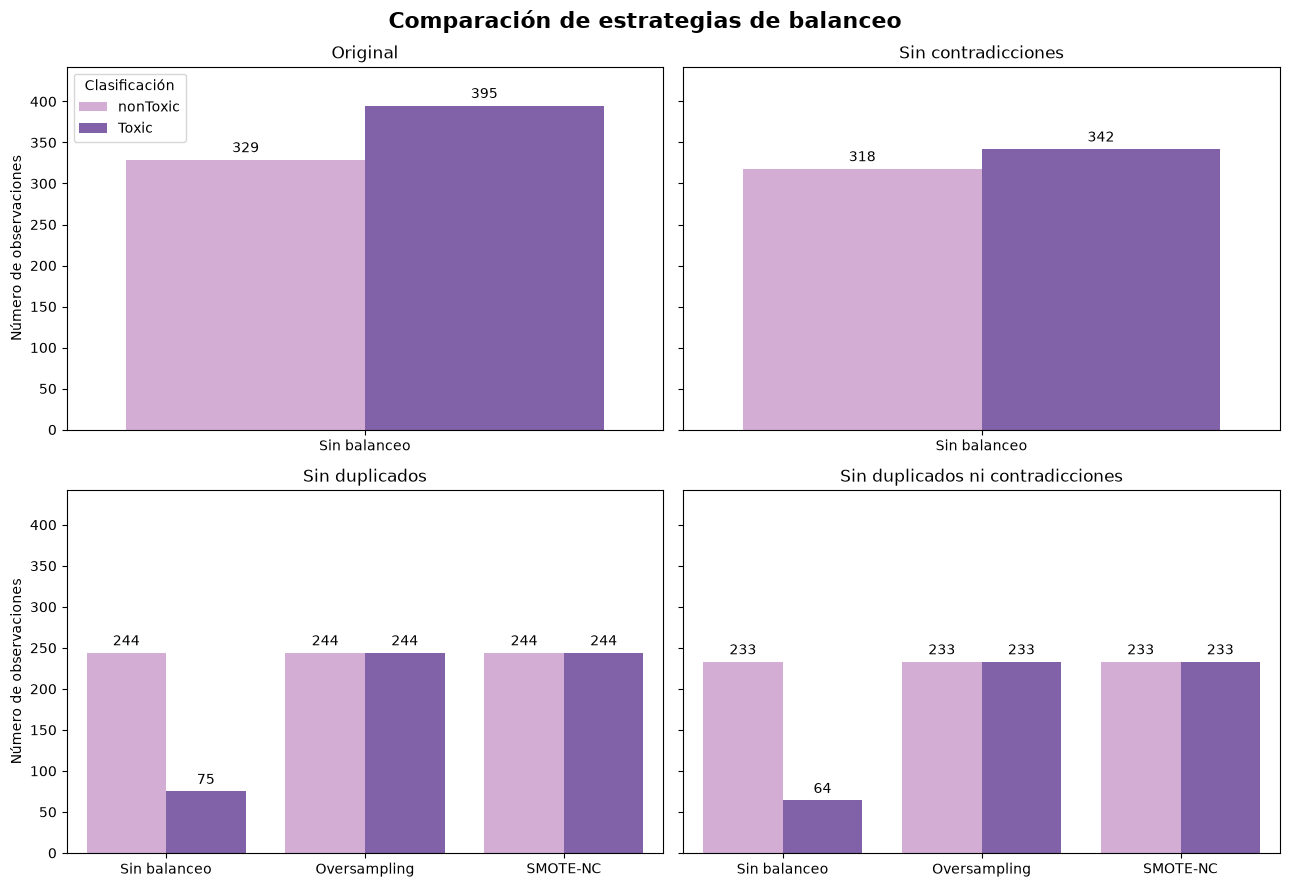

In [143]:
nombres = {
    "original": "Original",
    "sin_contradicciones": "Sin contradicciones",
    "sin_duplicados": "Sin duplicados",
    "sin_duplicados_ni_contradicciones":
        "Sin duplicados ni contradicciones"
}

nombres_balanceo = {
    "sin_balanceo": "Sin balanceo",
    "oversampling": "Oversampling",
    "SMOTENC": "SMOTE-NC"
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharey=True
)

axes = axes.flatten()

for ax, estrategia_dup in zip(axes, estrategias):

    datos_grafica = resultados_balanceo[
        resultados_balanceo["Tratamiento duplicados"]
        == estrategia_dup
    ].copy()

    datos_grafica["Balanceo"] = (
        datos_grafica["Balanceo"].map(nombres_balanceo)
    )

    datos_largos = datos_grafica.melt(
        id_vars="Balanceo",
        value_vars=["nonToxic", "Toxic"],
        var_name="Clase",
        value_name="Observaciones"
    )

    sns.barplot(
        data=datos_largos,
        x="Balanceo",
        y="Observaciones",
        hue="Clase",
        hue_order=["nonToxic", "Toxic"],
        palette={
            "nonToxic": "#D9A7D9",
            "Toxic": "#8055B3"
        },
        ax=ax
    )

    ax.set_title(nombres[estrategia_dup])
    ax.set_xlabel("")
    ax.set_ylabel("Número de observaciones")

    # Mostrar número de observaciones
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.0f",
            padding=3,
            fontsize=10
        )

    ax.margins(y=0.12)

    if ax != axes[0]:
        ax.get_legend().remove()

axes[0].legend(title="Clasificación")

plt.suptitle(
    "Comparación de estrategias de balanceo",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Los resultados del primer pliegue de entrenamiento confirmaron que las variantes original y sin contradicciones conservaron una distribución equilibrada de clases, por lo que no fue necesario aplicar técnicas de balanceo. En las variantes sin duplicados y sin duplicados ni contradicciones, RandomOverSampler y SMOTE-NC incrementaron la proporción de observaciones tóxicas del 23.51% y 21.55%, respectivamente, al 50%.

Aunque ambas técnicas lograron equilibrar las clases, será necesario evaluar su impacto sobre el desempeño predictivo para determinar cuál resulta más adecuada para cada modelo.

### 6. Modelos tradicionales de Machine Learning

Se evaluarán tres algoritmos de clasificación: regresión logística, árbol de decisión y Support Vector Machine (SVM). Estos modelos servirán como referencia para comparar posteriormente el desempeño de métodos de ensamble y redes neuronales.

Para cada algoritmo se utilizarán las tres representaciones de características y las ocho configuraciones de tratamiento de datos y balanceo definidas anteriormente, obteniendo un total de 24 configuraciones experimentales por modelo.

La evaluación se realizará mediante validación cruzada estratificada por grupos, utilizando F1 de la clase tóxica como métrica principal, además de precisión, sensibilidad y F1-macro.

#### 6.1. Regresión logística
La regresión logística es un modelo de clasificación que estima la probabilidad de pertenencia a una clase mediante la aplicación de una función logística a una combinación lineal de las características de entrada (Hastie et al., 2009).
Su implementación permitirá establecer un punto de referencia para evaluar si modelos capaces de representar relaciones no lineales ofrecen un mejor desempeño en la predicción de toxicidad.

Se entrenará un clasificador de regresión logística para predecir la toxicidad de las nanopartículas. Se compararán las representaciones sin reducción, PCA y Mutual Information, junto con las estrategias de tratamiento de duplicados y balanceo.

Se utilizará inicialmente una configuración de hiperparámetros estándar, con el propósito de establecer una referencia antes de realizar ajustes de optimización.

##### 6.1.1. Construcción de pipelines

Se construirán tres pipelines de regresión logística, correspondientes a las representaciones sin reducción de dimensionalidad, PCA y Mutual Information. Cada pipeline incorporará el preprocesamiento necesario y el clasificador, permitiendo ajustar las transformaciones exclusivamente con los datos de entrenamiento.

In [144]:
# Representaciones definidas en la sección 4
representaciones = {
    "Sin reducción": preprocesamiento_base,
    "PCA": preprocesamiento_pca,
    "Mutual Information": preprocesamiento_mi
}

# Crear pipelines de regresión logística
pipelines_lr = {}

for nombre, preprocesador in representaciones.items():

    pipelines_lr[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

print("Pipelines de regresión logística:")

for nombre in pipelines_lr:
    print("-", nombre)

Pipelines de regresión logística:
- Sin reducción
- PCA
- Mutual Information


##### 6.1.2. Evaluación inicial mediante validación cruzada

Se evaluarán las 24 configuraciones experimentales mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición se aplicará el tratamiento de duplicados y, cuando corresponda, el balanceo de clases únicamente sobre los datos de entrenamiento.

Se calcularán F1, precisión, sensibilidad y F1-macro para comparar el desempeño de las distintas configuraciones de regresión logística.

In [145]:
# Generar configuraciones experimentales
configuraciones = [
    (estrategia, balanceo)
    for estrategia in estrategias
    for balanceo in balanceos_por_estrategia[estrategia]
]

# Verificar configuraciones
assert len(configuraciones) == 8

print("Configuraciones de tratamiento y balanceo:")
display(pd.DataFrame(
    configuraciones,
    columns=["Tratamiento", "Balanceo"]
))

print(
    "Configuraciones experimentales por modelo:",
    len(configuraciones) * len(pipelines_lr)
)

resultados_lr = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Aplicar tratamiento de datos
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Aplicar balanceo cuando corresponda
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            # Imputar antes del sobremuestreo
            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            moda_np = X_train["NPs"].mode().iloc[0]

            X_train["NPs"] = X_train["NPs"].fillna(
                moda_np
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_lr.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_lr.append({
                "Modelo": "Regresión logística",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_lr = pd.DataFrame(resultados_lr)

# Verificar número de evaluaciones
evaluaciones_esperadas = (
    len(configuraciones)
    * len(pipelines_lr)
    * len(particiones_cv)
)

assert len(resultados_lr) == evaluaciones_esperadas

print("\nEvaluaciones completadas:", len(resultados_lr))

display(resultados_lr.head())

Configuraciones de tratamiento y balanceo:


,Tratamiento,Balanceo
0,original,sin_balanceo
1,sin_contradicciones,sin_balanceo
2,sin_duplicados,sin_balanceo
3,sin_duplicados,oversampling
4,sin_duplicados,SMOTENC
5,sin_duplicados_ni_contradicciones,sin_balanceo
6,sin_duplicados_ni_contradicciones,oversampling
7,sin_duplicados_ni_contradicciones,SMOTENC


Configuraciones experimentales por modelo: 24
Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Regresión logística,original,sin_balanceo,Sin reducción,1,0.602941,0.745455,0.506173,0.649785
1,Regresión logística,original,sin_balanceo,PCA,1,0.652482,0.766667,0.567901,0.684623
2,Regresión logística,original,sin_balanceo,Mutual Information,1,0.602941,0.745455,0.506173,0.649785
3,Regresión logística,original,sin_balanceo,Sin reducción,2,0.738255,0.846154,0.654762,0.739988
4,Regresión logística,original,sin_balanceo,PCA,2,0.709677,0.774648,0.654762,0.699666


##### 6.1.3. Comparación de resultados

Se comparará el desempeño promedio de las configuraciones de regresión logística, considerando principalmente el F1 de la clase tóxica. También se analizará la variabilidad entre pliegues y las métricas complementarias para identificar las configuraciones más prometedoras.

In [146]:
# Resumen de resultados por configuración
resumen_lr = (
    resultados_lr
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

# Mostrar resultados ordenados
display(resumen_lr.round(4))

print("\nMejor configuración inicial:")
display(resumen_lr.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936
8,sin_duplicados,SMOTENC,Sin reducción,0.7943,0.1090,0.8266,0.7890,0.7763
7,sin_duplicados,SMOTENC,PCA,0.7837,0.1085,0.8128,0.7768,0.7640
11,sin_duplicados,oversampling,Sin reducción,0.7831,0.0927,0.8254,0.7659,0.7704
1,original,sin_balanceo,PCA,0.7822,0.1033,0.7920,0.7958,0.7595
16,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.7810,0.1132,0.7978,0.7814,0.7616
6,sin_duplicados,SMOTENC,Mutual Information,0.7804,0.1181,0.8011,0.7935,0.7617
4,sin_contradicciones,sin_balanceo,PCA,0.7796,0.1025,0.7908,0.7909,0.7569
10,sin_duplicados,oversampling,PCA,0.7783,0.0964,0.8137,0.7659,0.7637
2,original,sin_balanceo,Sin reducción,0.7759,0.1194,0.8013,0.7788,0.7580



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.088,0.8418,0.7991,0.7936


La regresión logística alcanzó su mejor desempeño utilizando el conjunto sin duplicados ni contradicciones, balanceado mediante SMOTENC y sin reducción de características, con un F1 promedio de 0.8097 ± 0.0880. La eliminación exclusiva de contradicciones no produjo mejoras respecto al conjunto original, observándose ligeras disminuciones del F1 en las tres representaciones. Por otro lado, las técnicas de balanceo mejoraron considerablemente el desempeño de las variantes sin duplicados, principalmente al incrementar la sensibilidad. SMOTE-NC obtuvo los mejores resultados para estas variantes. En general, el tratamiento de datos y el balanceo tuvieron un mayor impacto sobre el desempeño de la regresión logística que la reducción de dimensionalidad.

#### 6.2. Árbol de decisión
Los árboles de decisión son modelos de aprendizaje supervisado que dividen recursivamente el espacio de características mediante reglas de decisión, buscando obtener subconjuntos de observaciones cada vez más homogéneos respecto a la variable objetivo. Estos modelos permiten representar relaciones no lineales e interacciones entre variables, aunque pueden ser susceptibles al sobreajuste (Breiman et al., 1984). Su evaluación permitirá analizar el desempeño de un modelo basado en reglas de decisión individuales y compararlo posteriormente con métodos de ensamble de árboles.

Se evaluará un clasificador basado en árboles de decisión para identificar relaciones no lineales entre las características de las nanopartículas y su toxicidad. Se compararán las tres representaciones de características junto con las estrategias de tratamiento de duplicados y balanceo.

El modelo se evaluará inicialmente sin optimización de hiperparámetros, utilizando las mismas particiones y métricas que en la regresión logística. Esto permitirá comparar ambos enfoques bajo condiciones equivalentes.

##### 6.2.1. Construcción de pipelines

Se construirán tres pipelines para el árbol de decisión, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente un clasificador con parámetros predeterminados para establecer su desempeño de referencia.

In [147]:
# Crear pipelines del árbol de decisión
pipelines_dt = {}

for nombre, preprocesador in representaciones.items():

    pipelines_dt[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", DecisionTreeClassifier(
            random_state=42
        ))
    ])

print("Pipelines del árbol de decisión:")

for nombre in pipelines_dt:
    print("-", nombre)

Pipelines del árbol de decisión:
- Sin reducción
- PCA
- Mutual Information


##### 6.2.2. Evaluación mediante validación cruzada

Se evaluarán las 24 configuraciones del árbol de decisión mediante los cinco pliegues de validación cruzada estratificada por grupos. En cada partición se aplicarán las estrategias de tratamiento de duplicados y balanceo correspondientes, y se calcularán las métricas F1, precisión, sensibilidad y F1-macro.

Los resultados permitirán identificar las configuraciones más prometedoras y compararlas posteriormente con la regresión logística.

In [148]:
resultados_dt = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar representaciones
        for representacion, pipeline in pipelines_dt.items():

            modelo = clone(pipeline)
            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_dt.append({
                "Modelo": "Árbol de decisión",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred, zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred, zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

resultados_dt = pd.DataFrame(resultados_dt)

print("\nEvaluaciones completadas:", len(resultados_dt))

display(resultados_dt.head())

Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Árbol de decisión,original,sin_balanceo,Sin reducción,1,0.941935,0.986486,0.901235,0.942666
1,Árbol de decisión,original,sin_balanceo,PCA,1,0.528000,0.750000,0.407407,0.607915
2,Árbol de decisión,original,sin_balanceo,Mutual Information,1,0.915254,0.843750,1.000000,0.902883
3,Árbol de decisión,original,sin_balanceo,Sin reducción,2,0.727273,1.000000,0.571429,0.756494
4,Árbol de decisión,original,sin_balanceo,PCA,2,0.607143,0.607143,0.607143,0.553571


##### 6.2.3. Comparación de resultados

Se calcularán el promedio y la desviación estándar del F1 obtenido en los cinco pliegues para cada configuración. También se analizarán la precisión, la sensibilidad y el F1-macro, con el propósito de identificar el efecto de las estrategias de representación, balanceo y tratamiento de duplicados.

In [149]:
# Resumen de resultados por configuración
resumen_dt = (
    resultados_dt
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_dt.round(4))

print("\nMejor configuración inicial:")
display(resumen_dt.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
11,sin_duplicados,oversampling,Sin reducción,0.8855,0.0942,0.9074,0.8713,0.8826
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8848,0.0944,0.9239,0.8733,0.8831
23,sin_duplicados_ni_contradicciones,sin_balanceo,Sin reducción,0.8776,0.0705,0.9399,0.8391,0.8776
6,sin_duplicados,SMOTENC,Mutual Information,0.8737,0.0852,0.8703,0.8875,0.8600
2,original,sin_balanceo,Sin reducción,0.8725,0.0871,0.9252,0.8500,0.8684
20,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8635,0.0979,0.9153,0.8406,0.8638
5,sin_contradicciones,sin_balanceo,Sin reducción,0.8586,0.0987,0.8859,0.8527,0.8507
21,sin_duplicados_ni_contradicciones,sin_balanceo,Mutual Information,0.8540,0.0691,0.8706,0.8479,0.8446
7,sin_duplicados,SMOTENC,PCA,0.8516,0.0929,0.8668,0.8549,0.8437



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789


El árbol de decisión alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante SMOTENC y sin reducción de características, con un F1 promedio de 0.8856 ± 0.0662. Este resultado superó al obtenido por la regresión logística. Además, RandomOverSampler presentó un desempeño prácticamente equivalente al de SMOTENC,  aunque con una mayor variabilidad entre pliegues. 

La eliminación exclusiva de contradicciones produjo resultados diferentes según la representación utilizada, destacando una disminución de 12.82 puntos porcentuales en el F1 al utilizar Mutual Information. En general, las configuraciones sin reducción de características obtuvieron los mejores resultados, mientras que PCA presentó un desempeño inferior. Estos resultados sugirieron que conservar las características originales fue más favorable para el árbol de decisión.

#### 6.3. Support Vector Machine (SVM)

Las máquinas de vectores de soporte (SVM) son modelos de aprendizaje supervisado que buscan encontrar una frontera de decisión que maximice el margen de separación entre clases. Mediante el uso de funciones kernel, pueden representar fronteras de decisión no lineales sin transformar explícitamente las observaciones a espacios de mayor dimensionalidad (Cortes & Vapnik, 1995). 
Su implementación permitirá evaluar la capacidad de un modelo basado en márgenes para identificar relaciones complejas entre las características de las nanopartículas y su toxicidad.Se evaluará SVM con kernel RBF para identificar posibles relaciones no lineales entre las características de las nanopartículas y su toxicidad. Se compararán las tres representaciones de características y las ocho configuraciones de tratamiento de duplicados, etiquetas contradictorias y balanceo.

##### 6.3.1. Construcción de pipelines

Se construirán tres pipelines para SVM, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará un kernel RBF con parámetros iniciales predeterminados, con el propósito de establecer una referencia antes de realizar la optimización de hiperparámetros.

In [150]:
# Crear pipelines de SVM
pipelines_svm = {}

for nombre, preprocesador in representaciones.items():

    pipelines_svm[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        ))
    ])

print("Pipelines de SVM:")

for nombre in pipelines_svm:
    print("-", nombre)


Pipelines de SVM:
- Sin reducción
- PCA
- Mutual Information


##### 6.3.2. Evaluación mediante validación cruzada

Se evaluarán las 24 configuraciones de SVM mediante cinco pliegues de validación cruzada estratificada por grupos. El tratamiento de duplicados y el balanceo se aplicarán únicamente a los conjuntos de entrenamiento de cada partición, manteniendo intactos los datos de validación.

Se calcularán F1, precisión, sensibilidad y F1-macro para comparar las configuraciones e identificar las más prometedoras.

In [151]:
resultados_svm = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo solo en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_svm.items():

            modelo = clone(pipeline)
            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_svm.append({
                "Modelo": "SVM",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_svm = pd.DataFrame(resultados_svm)

print("\nEvaluaciones completadas:", len(resultados_svm))

display(resultados_svm.head())

Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,SVM,original,sin_balanceo,Sin reducción,1,0.920455,0.852632,1.000000,0.909503
1,SVM,original,sin_balanceo,PCA,1,0.863905,0.829545,0.901235,0.852642
2,SVM,original,sin_balanceo,Mutual Information,1,0.962963,0.962963,0.962963,0.961745
3,SVM,original,sin_balanceo,Sin reducción,2,0.754967,0.850746,0.678571,0.753322
4,SVM,original,sin_balanceo,PCA,2,0.760000,0.863636,0.678571,0.760000


##### 6.3.3. Comparación de resultados

Se resumirán los resultados de SVM mediante el promedio y la desviación estándar del F1 obtenido en los cinco pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las distintas estrategias de tratamiento, balanceo y representación de características.

In [152]:
# Resumen de resultados por configuración
resumen_svm = (
    resultados_svm
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_svm.round(4))

print("\nMejor configuración inicial:")
display(resumen_svm.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
11,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
10,sin_duplicados,oversampling,PCA,0.9045,0.1069,0.9233,0.8990,0.9033
16,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.9043,0.0784,0.9090,0.9165,0.8957
20,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8986,0.1051,0.9120,0.8978,0.8962
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8972,0.0765,0.9021,0.9091,0.8876
19,sin_duplicados_ni_contradicciones,oversampling,PCA,0.8937,0.1038,0.9128,0.8856,0.8912
7,sin_duplicados,SMOTENC,PCA,0.8747,0.1137,0.8854,0.8848,0.8632
5,sin_contradicciones,sin_balanceo,Sin reducción,0.8745,0.0951,0.8771,0.8887,0.8659
8,sin_duplicados,SMOTENC,Sin reducción,0.8729,0.1121,0.8816,0.8848,0.8615
2,original,sin_balanceo,Sin reducción,0.8713,0.0766,0.8566,0.9030,0.8527



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
11,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048


SVM alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante RandomOverSampler y sin reducción de características, con un F1 promedio de 0.9056 ± 0.1095. La eliminación exclusiva de contradicciones produjo cambios menores respecto al conjunto original, con ligeras mejoras en las representaciones sin reducción y PCA.

Las técnicas de balanceo mejoraron considerablemente el desempeño de las variantes sin duplicados. Destacó también la configuración sin duplicados ni contradicciones con SMOTE-NC y PCA, que obtuvo un F1 de 0.9043 con menor variabilidad y mayor sensibilida. En general, SVM presentó un desempeño competitivo tanto con las características originales como con PCA, mientras que Mutual Information obtuvo resultados inferiores.

#### 6.4. Comparación de los modelos tradicionales

Se compararán los resultados de regresión logística, árbol de decisión y SVM utilizando las métricas obtenidas durante la validación cruzada. Se identificarán las mejores configuraciones iniciales de cada modelo y se analizarán las diferencias de desempeño, considerando tanto el F1 promedio como su variabilidad entre pliegues.

Esta comparación servirá como referencia para evaluar posteriormente si los métodos de ensamble y las redes neuronales ofrecen mejoras predictivas.

In [153]:
# Recuperar mejor configuración de cada modelo
mejores_tradicionales = pd.concat([
    resumen_lr.head(1).assign(
        Modelo="Regresión logística"
    ),
    resumen_dt.head(1).assign(
        Modelo="Árbol de decisión"
    ),
    resumen_svm.head(1).assign(
        Modelo="SVM"
    )
], ignore_index=True)

# Ordenar columnas
columnas = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación",
    "F1_promedio",
    "F1_std",
    "Precision",
    "Sensibilidad",
    "F1_macro"
]

mejores_tradicionales = (
    mejores_tradicionales[columnas]
    .sort_values("F1_promedio", ascending=False)
)

display(mejores_tradicionales.round(4))

,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
0,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936


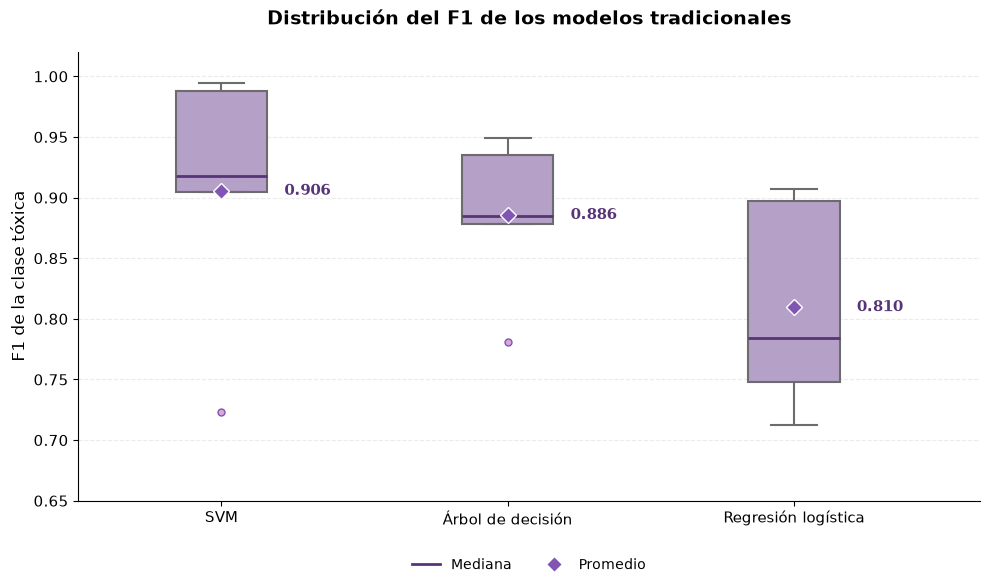

In [154]:
# Recuperar resultados individuales
resultados_tradicionales = pd.concat([
    resultados_lr.assign(Modelo="Regresión logística"),
    resultados_dt.assign(Modelo="Árbol de decisión"),
    resultados_svm.assign(Modelo="SVM")
], ignore_index=True)

# Seleccionar las mejores configuraciones
columnas_config = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación"
]

datos_boxplot = resultados_tradicionales.merge(
    mejores_tradicionales[columnas_config],
    on=columnas_config,
    how="inner"
)

orden = mejores_tradicionales["Modelo"].tolist()

# Crear gráfica
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=datos_boxplot,
    x="Modelo",
    y="F1",
    order=orden,
    color="#B69ACD",
    width=0.32,
    linewidth=1.5,
    showmeans=True,
    showfliers=True,
    medianprops={
        "color": "#563477",
        "linewidth": 2
    },
    meanprops={
        "marker": "D",
        "markerfacecolor": "#8055B3",
        "markeredgecolor": "white",
        "markersize": 8
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "#D9A7D9",
        "markeredgecolor": "#8055B3",
        "markersize": 5
    },
    ax=ax
)

# Mostrar F1 promedio a un lado de cada caja
for i, modelo in enumerate(orden):

    promedio = datos_boxplot.loc[
        datos_boxplot["Modelo"] == modelo,
        "F1"
    ].mean()

    ax.text(
        i + 0.22,
        promedio,
        f"{promedio:.3f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

# Personalizar gráfica
ax.set_title(
    "Distribución del F1 de los modelos tradicionales",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("F1 de la clase tóxica", fontsize=12)
ax.set_xlabel("")
ax.set_ylim(0.65, 1.02)
ax.set_xlim(-0.5, len(orden) - 0.35)

ax.tick_params(axis="both", labelsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine()

# Leyenda simplificada
from matplotlib.lines import Line2D

leyenda = [
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

SVM obtuvo el mayor F1 promedio (0.9056), seguido del árbol de decisión (0.8856) y la regresión logística (0.8097). Pero, aunque presentó el mejor desempeño, también mostró una mayor variabilidad entre pliegues que el árbol de decisión, con un valor atípico cercano a 0.72. Por su parte, el árbol de decisión presentó la menor desviación estándar, mostrando una mayor estabilidad. La regresión logística obtuvo el menor F1 promedio y presentó una mayor dispersión en el rango intercuartílico, lo que sugirió una mayor dependencia de la partición de los datos.

En conjunto, SVM destacó por su capacidad predictiva y el árbol de decisión por su estabilidad. Sin embargo, debido al número reducido de pliegues, estas diferencias se interpretaron de manera descriptiva, sin establecer una superioridad estadísticamente significativa.

### 7. Random Forest

Random Forest es un método de ensamble que combina múltiples árboles de decisión entrenados sobre muestras bootstrap del conjunto de datos, incorporando además una selección aleatoria de características candidatas en cada división. La combinación de sus predicciones permite reducir la varianza y disminuir el riesgo de sobreajuste respecto a un árbol de decisión individual (Breiman, 2001). Su implementación permitirá evaluar las ventajas de una estrategia de ensamble basada en bagging para la predicción de toxicidad.

Se compararán las tres representaciones de características y las ocho configuraciones de tratamiento de duplicados, etiquetas contradictorias y balanceo, utilizando las mismas particiones de validación cruzada que en los modelos tradicionales.

#### 7.1. Construcción de pipelines

Se construirán tres pipelines de Random Forest, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente un ensamble de 200 árboles con parámetros estándar, con el propósito de establecer una referencia antes de realizar la optimización de hiperparámetros.

In [155]:
# Crear pipelines de Random Forest
pipelines_rf = {}

for nombre, preprocesador in representaciones.items():

    pipelines_rf[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

print("Pipelines de Random Forest:")

for nombre in pipelines_rf:
    print("-", nombre)

Pipelines de Random Forest:
- Sin reducción
- PCA
- Mutual Information


#### 7.2. Evaluación mediante validación cruzada

Se evaluarán las 24 configuraciones de Random Forest mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán exclusivamente sobre los datos de entrenamiento.

Se calcularán F1, precisión, sensibilidad y F1-macro para identificar las configuraciones más prometedoras y comparar su desempeño con los modelos tradicionales.

In [156]:
resultados_rf = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_rf.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_rf.append({
                "Modelo": "Random Forest",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_rf = pd.DataFrame(resultados_rf)

print("\nEvaluaciones completadas:", len(resultados_rf))

display(resultados_rf.head())

Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Random Forest,original,sin_balanceo,Sin reducción,1,0.879518,0.858824,0.901235,0.872191
1,Random Forest,original,sin_balanceo,PCA,1,0.616541,0.788462,0.506173,0.667387
2,Random Forest,original,sin_balanceo,Mutual Information,1,0.981818,0.964286,1.000000,0.980842
3,Random Forest,original,sin_balanceo,Sin reducción,2,0.791667,0.950000,0.678571,0.799679
4,Random Forest,original,sin_balanceo,PCA,2,0.728571,0.910714,0.607143,0.745536


#### 7.3. Comparación de resultados

Se comparará el desempeño de las configuraciones de Random Forest mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

In [157]:
# Resumen de resultados por configuración
resumen_rf = (
    resultados_rf
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_rf.round(4))

print("\nMejor configuración inicial:")
display(resumen_rf.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845
2,original,sin_balanceo,Sin reducción,0.8855,0.0755,0.8867,0.9022,0.8722
6,sin_duplicados,SMOTENC,Mutual Information,0.8809,0.0896,0.8739,0.9048,0.8660
3,sin_contradicciones,sin_balanceo,Mutual Information,0.8788,0.1002,0.8715,0.8955,0.8625
8,sin_duplicados,SMOTENC,Sin reducción,0.8761,0.0712,0.8959,0.8790,0.8652
7,sin_duplicados,SMOTENC,PCA,0.8748,0.0764,0.8750,0.8826,0.8654
18,sin_duplicados_ni_contradicciones,oversampling,Mutual Information,0.8747,0.0829,0.8539,0.9096,0.8566
11,sin_duplicados,oversampling,Sin reducción,0.8724,0.0774,0.8850,0.8720,0.8616
9,sin_duplicados,oversampling,Mutual Information,0.8705,0.0965,0.8640,0.8882,0.8536
15,sin_duplicados_ni_contradicciones,SMOTENC,Mutual Information,0.8688,0.0808,0.8666,0.8876,0.8528



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,original,sin_balanceo,Mutual Information,0.896,0.093,0.8836,0.9169,0.8845


Random Forest alcanzó su mejor desempeño utilizando el conjunto original, sin balanceo y con selección de características mediante Mutual Information, obteniendo un F1 promedio de 0.8960 ± 0.0930. La eliminación exclusiva de contradicciones mejoró el desempeño al utilizar PCA, pero produjo ligeras disminuciones en las otras representaciones. Asimismo, las estrategias de eliminación de duplicados y balanceo no lograron superar el desempeño de la mejor configuración con los datos originales. Destacó Mutual Information como la representación con mayor F1 en cada uno de los cuatro tratamientos, lo que sugirió que la selección de características fue favorable para este modelo.

### 8. XGBoost

XGBoost (Extreme Gradient Boosting) es un método de ensamble basado en gradient boosting, en el que los árboles de decisión se construyen de manera secuencial para mejorar las predicciones del conjunto de árboles anteriores mediante la optimización de una función de pérdida. Además, incorpora mecanismos de regularización que permiten controlar la complejidad del modelo y reducir el riesgo de sobreajuste (Chen & Guestrin, 2016). Su evaluación permitirá comparar el desempeño de una estrategia de boosting frente a una estrategia de bagging, representada por Random Forest.

Se compararán las tres representaciones de características y las ocho configuraciones de tratamiento de duplicados, etiquetas contradictorias y balanceo, utilizando las mismas particiones de validación cruzada que en los modelos anteriores.

#### 8.1. Construcción de pipelines

Se construirán tres pipelines de XGBoost, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente una configuración fija de hiperparámetros, sin realizar todavía una búsqueda de optimización.

El preprocesamiento se ajustará exclusivamente sobre los datos de entrenamiento de cada pliegue, manteniendo las mismas condiciones de evaluación que en los modelos anteriores.

In [158]:
# Crear pipelines de XGBoost
pipelines_xgb = {}

for nombre, preprocesador in representaciones.items():

    pipelines_xgb[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

print("Pipelines de XGBoost:")

for nombre in pipelines_xgb:
    print("-", nombre)

Pipelines de XGBoost:
- Sin reducción
- PCA
- Mutual Information


#### 8.2. Evaluación mediante validación cruzada

Se evaluarán las 24 configuraciones de XGBoost mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán únicamente sobre el conjunto de entrenamiento, manteniendo intactos los datos de validación.

Se calcularán F1, precisión, sensibilidad y F1-macro para identificar las configuraciones más prometedoras y compararlas con los modelos evaluados anteriormente.

In [159]:
resultados_xgb = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_xgb.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_xgb.append({
                "Modelo": "XGBoost",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_xgb = pd.DataFrame(resultados_xgb)

print("\nEvaluaciones completadas:", len(resultados_xgb))

display(resultados_xgb.head())

Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,XGBoost,original,sin_balanceo,Sin reducción,1,0.935897,0.973333,0.901235,0.936303
1,XGBoost,original,sin_balanceo,PCA,1,0.616541,0.788462,0.506173,0.667387
2,XGBoost,original,sin_balanceo,Mutual Information,1,0.975000,0.987342,0.962963,0.974513
3,XGBoost,original,sin_balanceo,Sin reducción,2,0.802817,0.982759,0.678571,0.812801
4,XGBoost,original,sin_balanceo,PCA,2,0.780822,0.919355,0.678571,0.786515


#### 8.3. Comparación de resultados

Se compararán las configuraciones de XGBoost mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

Los resultados se utilizarán para identificar las configuraciones más prometedoras antes de realizar la optimización de hiperparámetros.

In [160]:
# Resumen de resultados por configuración
resumen_xgb = (
    resultados_xgb
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_xgb.round(4))

print("\nMejor configuración inicial:")
display(resumen_xgb.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8992,0.0690,0.9254,0.8927,0.8899
5,sin_contradicciones,sin_balanceo,Sin reducción,0.8966,0.0608,0.9227,0.8878,0.8887
0,original,sin_balanceo,Mutual Information,0.8962,0.0834,0.9086,0.8924,0.8886
8,sin_duplicados,SMOTENC,Sin reducción,0.8962,0.0690,0.9310,0.8838,0.8874
11,sin_duplicados,oversampling,Sin reducción,0.8960,0.0698,0.9234,0.8838,0.8902
14,sin_duplicados,sin_balanceo,Sin reducción,0.8905,0.0724,0.9130,0.8838,0.8824
21,sin_duplicados_ni_contradicciones,sin_balanceo,Mutual Information,0.8876,0.0675,0.9238,0.8663,0.8823
15,sin_duplicados_ni_contradicciones,SMOTENC,Mutual Information,0.8838,0.0944,0.8965,0.8851,0.8698
7,sin_duplicados,SMOTENC,PCA,0.8786,0.0974,0.8902,0.8734,0.8705



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.92,0.9091,0.8977


XGBoost alcanzó su mejor desempeño utilizando el conjunto original, sin balanceo ni reducción de características, con un F1 promedio de 0.9056 ± 0.0691. Las estrategias de eliminación de duplicados y balanceo mediante SMOTENC produjeron resultados cercanos, aunque ligeramente inferiores. La eliminación exclusiva de contradicciones produjo una ligera mejora al utilizar PCA, pero disminuyó el desempeño de las otras representaciones, especialmente Mutual Information. Las mejores configuraciones de los cuatro tratamientos presentaron valores de F1 similares. Además, conservar todas las características resultó favorable en cada tratamiento.

En comparación con SVM, XGBoost alcanzó el mismo F1 promedio, pero presentó una menor variabilidad entre pliegues, mostrando una mayor estabilidad en esta evaluación.

### 9. Red neuronal multicapa (MLP)

Se evaluará una red neuronal multicapa (MLP) como representante de los métodos de aprendizaje profundo. Este modelo permite aprender relaciones no lineales entre las características fisicoquímicas de las nanopartículas y su toxicidad mediante capas de neuronas interconectadas. Se compararán las mismas tres representaciones de características y ocho configuraciones de tratamiento de duplicados, etiquetas contradictorias y balanceo utilizadas en los modelos anteriores.

Cabe señaral que aunque se incluirá MLP para comparar su desempeño con los modelos tradicionales, no se espera necesariamente que obtenga los mejores resultados. Esto se debe principalmente al tamaño reducido del conjunto de datos y a que los modelos de *deep learning* suelen requerir mayores cantidades de información para aprovechar su capacidad de aprendizaje. Además, en problemas con datos tabulares, los métodos tradicionales de *machine learning*, especialmente los basados en árboles y ensambles, suelen ofrecer resultados competitivos e incluso superiores a las redes neuronales (Grinsztajn et al., 2022). Por ello, MLP se utilizará principalmente como un modelo de comparación para evaluar si una mayor complejidad se traduce en un mejor desempeño predictivo.

#### 9.1. Construcción de pipelines

Se construirán tres pipelines de MLP, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente una arquitectura de dos capas ocultas, con 64 y 32 neuronas respectivamente, activación ReLU y optimizador Adam.

Se incorporará detención temprana para limitar el sobreajuste y reducir el tiempo de entrenamiento. La arquitectura se mantendrá fija durante esta evaluación inicial y podrá ajustarse posteriormente mediante optimización de hiperparámetros.

In [161]:
# Crear pipelines de MLP
pipelines_mlp = {}

for nombre, preprocesador in representaciones.items():

    pipelines_mlp[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=42
        ))
    ])

print("Pipelines de MLP:")

for nombre in pipelines_mlp:
    print("-", nombre)

Pipelines de MLP:
- Sin reducción
- PCA
- Mutual Information


#### 9.2. Evaluación mediante validación cruzada

Se evaluarán las 24 configuraciones de MLP mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán exclusivamente sobre los datos de entrenamiento. Se calcularán F1, precisión, sensibilidad y F1-macro para comparar el desempeño de la red neuronal con los modelos tradicionales y de ensamble.

In [162]:
resultados_mlp = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_mlp.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_mlp.append({
                "Modelo": "MLP",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_mlp = pd.DataFrame(resultados_mlp)

print("\nEvaluaciones completadas:", len(resultados_mlp))

display(resultados_mlp.head())

Evaluando: original | sin_balanceo
Evaluando: sin_contradicciones | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 120


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,MLP,original,sin_balanceo,Sin reducción,1,0.784314,0.833333,0.740741,0.789672
1,MLP,original,sin_balanceo,PCA,1,0.661871,0.793103,0.567901,0.696650
2,MLP,original,sin_balanceo,Mutual Information,1,0.672000,0.954545,0.518519,0.727534
3,MLP,original,sin_balanceo,Sin reducción,2,0.739130,0.944444,0.607143,0.758454
4,MLP,original,sin_balanceo,PCA,2,0.774648,0.948276,0.654762,0.786058


#### 9.3. Comparación de resultados

Se comparará el desempeño de las configuraciones de MLP mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

Los resultados permitirán investigar si la red neuronal ofrece mejoras respecto a los modelos tradicionales y de ensamble, considerando también la complejidad computacional de su entrenamiento.

In [163]:
# Resumen de resultados por configuración
resumen_mlp = (
    resultados_mlp
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_mlp.round(4))

print("\nMejor configuración inicial:")
display(resumen_mlp.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538
17,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8561,0.0942,0.8394,0.8888,0.8361
2,original,sin_balanceo,Sin reducción,0.8403,0.1020,0.8613,0.8472,0.8228
1,original,sin_balanceo,PCA,0.8366,0.1303,0.8658,0.8376,0.8282
5,sin_contradicciones,sin_balanceo,Sin reducción,0.8310,0.0868,0.8283,0.8554,0.8039
16,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.8290,0.1059,0.8522,0.8332,0.8109
4,sin_contradicciones,sin_balanceo,PCA,0.8159,0.1107,0.8516,0.8062,0.8090
19,sin_duplicados_ni_contradicciones,oversampling,PCA,0.8123,0.1074,0.8454,0.7959,0.8042
0,original,sin_balanceo,Mutual Information,0.8118,0.1181,0.8759,0.7861,0.8087
20,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8116,0.1549,0.8073,0.8392,0.7953



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538


MLP alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante SMOTENC y sin reducción de características, obteniendo un F1 promedio de 0.8625 ± 0.0894. La eliminación exclusiva de contradicciones disminuyó el desempeño en las tres representaciones. Por otro lado, las técnicas de balanceo, particularmente SMOTE-NC, mejoraron considerablemente el F1 y redujeron la variabilidad de las configuraciones sin duplicados.

A pesar de su mayor complejidad, MLP no superó el desempeño de SVM, Random Forest ni XGBoost, lo que mostró que una arquitectura neuronal no necesariamente ofrece mejores resultados para este conjunto de datos.

### 10. Comparación general de modelos

Se compararán los resultados iniciales de los seis algoritmos evaluados: regresión logística, árbol de decisión, SVM, Random Forest, XGBoost y MLP.

El análisis se centrará en el F1 promedio y su desviación estándar entre los cinco pliegues de validación cruzada, considerando también la precisión, sensibilidad y F1-macro. Además, se examinará cómo influyen las estrategias de tratamiento de duplicados, balanceo y representación de características en el desempeño de los modelos. Esta comparación permitirá identificar los algoritmos y configuraciones más prometedores para la posterior optimización de hiperparámetros.

#### 10.1. Comparación del desempeño predictivo

Se identificarán las configuraciones con mayor F1 promedio de cada modelo y se compararán sus métricas de evaluación. También se visualizará la variabilidad entre pliegues mediante barras de error, con el propósito de analizar tanto el desempeño predictivo como su estabilidad.

In [164]:
# Reunir los resúmenes de los seis modelos
resumenes = {
    "Regresión logística": resumen_lr,
    "Árbol de decisión": resumen_dt,
    "SVM": resumen_svm,
    "Random Forest": resumen_rf,
    "XGBoost": resumen_xgb,
    "MLP": resumen_mlp
}

# Obtener la mejor configuración de cada modelo
mejores_modelos = []

for nombre, resumen in resumenes.items():

    mejor = resumen.loc[
        resumen["F1_promedio"].idxmax()
    ].copy()

    mejor["Modelo"] = nombre
    mejores_modelos.append(mejor)

comparacion_modelos = pd.DataFrame(
    mejores_modelos
)

# Ordenar por F1 promedio
comparacion_modelos = (
    comparacion_modelos
    .sort_values(
        "F1_promedio",
        ascending=False
    )
    .reset_index(drop=True)
)

columnas = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación",
    "F1_promedio",
    "F1_std",
    "Precision",
    "Sensibilidad",
    "F1_macro"
]

display(
    comparacion_modelos[columnas].round(4)
)

,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,XGBoost,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
2,Random Forest,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845
3,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
4,MLP,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538
5,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936


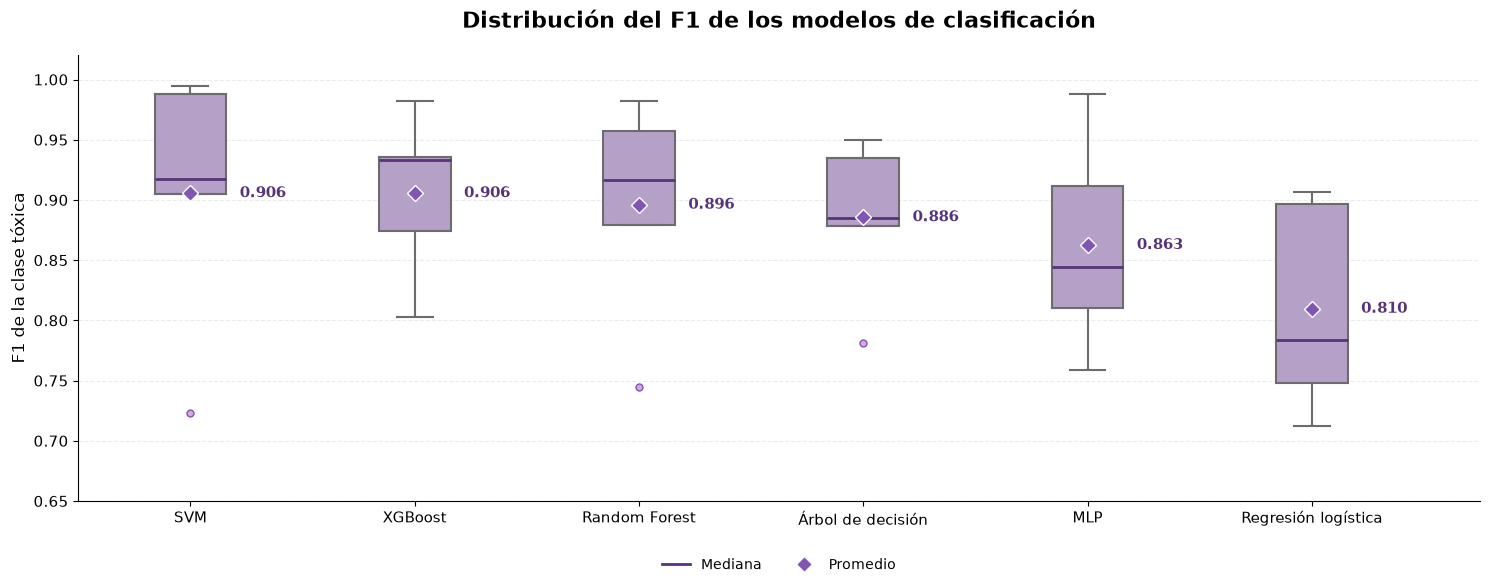

In [165]:
# Recuperar los resultados individuales
resultados_todos = pd.concat([
    resultados_lr.assign(Modelo="Regresión logística"),
    resultados_dt.assign(Modelo="Árbol de decisión"),
    resultados_svm.assign(Modelo="SVM"),
    resultados_rf.assign(Modelo="Random Forest"),
    resultados_xgb.assign(Modelo="XGBoost"),
    resultados_mlp.assign(Modelo="MLP")
], ignore_index=True)

# Identificar la mejor configuración de cada modelo
columnas_config = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación"
]

resumen_boxplot = (
    resultados_todos
    .groupby(columnas_config, as_index=False)
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std")
    )
    .sort_values(
        ["F1_promedio", "F1_std"],
        ascending=[False, True]
    )
    .drop_duplicates(subset="Modelo")
)

# Recuperar los cinco pliegues de cada mejor configuración
datos_boxplot = resultados_todos.merge(
    resumen_boxplot[columnas_config],
    on=columnas_config,
    how="inner"
)

orden = resumen_boxplot["Modelo"].tolist()

# Verificar resultados
assert len(orden) == 6
assert len(datos_boxplot) == 30
assert datos_boxplot.groupby("Modelo").size().eq(5).all()

# Crear gráfica
fig, ax = plt.subplots(figsize=(15, 6))

sns.boxplot(
    data=datos_boxplot,
    x="Modelo",
    y="F1",
    order=orden,
    color="#B69ACD",
    width=0.32,
    linewidth=1.5,
    showmeans=True,
    showfliers=True,
    medianprops={
        "color": "#563477",
        "linewidth": 2
    },
    meanprops={
        "marker": "D",
        "markerfacecolor": "#8055B3",
        "markeredgecolor": "white",
        "markersize": 8
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "#D9A7D9",
        "markeredgecolor": "#8055B3",
        "markersize": 5
    },
    ax=ax
)

# Mostrar F1 promedio junto a cada caja
for i, modelo in enumerate(orden):

    promedio = datos_boxplot.loc[
        datos_boxplot["Modelo"] == modelo,
        "F1"
    ].mean()

    ax.text(
        i + 0.22,
        promedio,
        f"{promedio:.3f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

# Personalizar gráfica
ax.set_title(
    "Distribución del F1 de los modelos de clasificación",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("F1 de la clase tóxica", fontsize=12)
ax.set_xlabel("")

# Ajustar el eje vertical sin ocultar observaciones
limite_inferior = min(
    0.65,
    datos_boxplot["F1"].min() - 0.03
)

ax.set_ylim(max(0, limite_inferior), 1.02)
ax.set_xlim(-0.5, len(orden) - 0.25)

ax.tick_params(axis="both", labelsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine()

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

SVM y XGBoost obtuvieron los mayores valores de F1 promedio (0.9056), seguidos de Random Forest (0.8960). Aunque SVM y XGBoost alcanzaron un desempeño promedio prácticamente idéntico, XGBoost presentó una menor variabilidad entre pliegues.

El árbol de decisión destacó por presentar la menor desviación estándar, aunque con un F1 promedio inferior al de los tres mejores modelos. Por su parte, MLP no logró superar el desempeño de los métodos de ensamble ni de SVM, a pesar de su mayor complejidad. La regresión logística obtuvo el menor F1 promedio.

Estos resultados permitieron seleccionar SVM, Random Forest y XGBoost para la posterior optimización de hiperparámetros. Sin embargo, las diferencias observadas fueron descriptivas y no permitieron establecer una superioridad estadísticamente significativa entre los modelos.

#### 10.2 Interpretación de resultados

##### 10.2.1. Comparación general de tratamientos

Se comparará el mejor F1 promedio obtenido por cada clasificador para las cuatro estrategias de tratamiento de datos, considerando las distintas configuraciones de balanceo y representación de características. Esto permitirá identificar qué tratamiento resultará más favorable para cada modelo.

,Original,Sin contradicciones,Sin duplicados,Sin duplicados ni contradicciones
Modelo,,,,
SVM,0.8713,0.8745,0.9056,0.9043
XGBoost,0.9056,0.8966,0.8962,0.8992
Random Forest,0.8960,0.8788,0.8809,0.8747
Árbol de decisión,0.8725,0.8586,0.8856,0.8848
MLP,0.8403,0.8310,0.8625,0.8561
Regresión logística,0.7822,0.7796,0.7943,0.8097


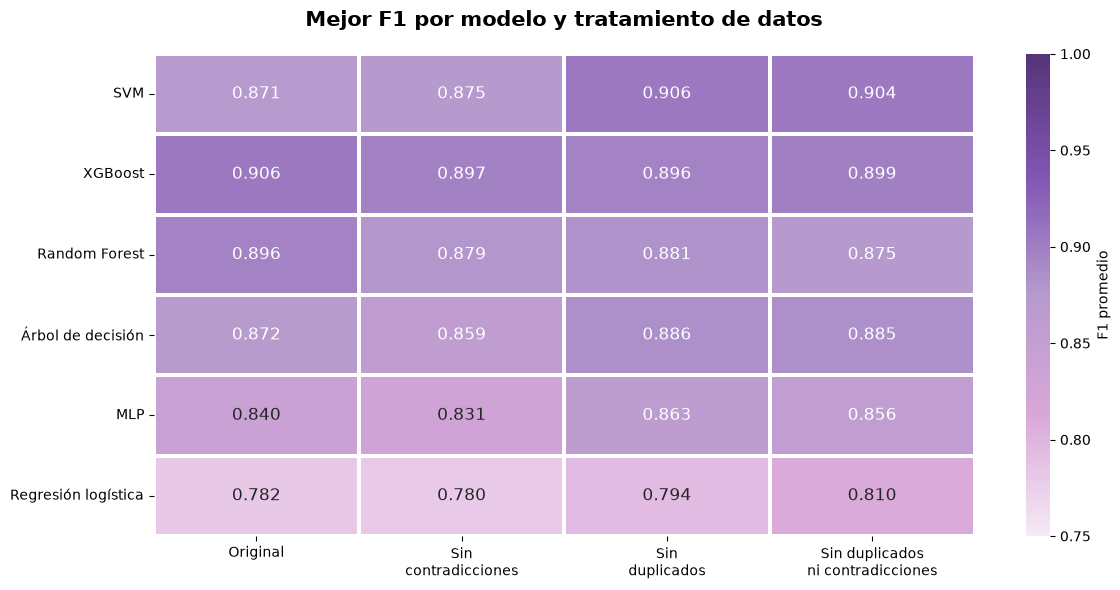

In [166]:
# Calcular métricas promedio por configuración
resumen_tratamientos = (
    resultados_todos
    .groupby([
        "Modelo",
        "Tratamiento",
        "Balanceo",
        "Representación"
    ], as_index=False)
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std")
    )
)

# Seleccionar la mejor configuración de cada tratamiento
mejores_tratamientos = (
    resumen_tratamientos
    .sort_values(
        ["F1_promedio", "F1_std"],
        ascending=[False, True]
    )
    .drop_duplicates(
        subset=["Modelo", "Tratamiento"]
    )
)

# Orden de los modelos
orden_modelos = [
    "SVM",
    "XGBoost",
    "Random Forest",
    "Árbol de decisión",
    "MLP",
    "Regresión logística"
]

# Orden de los tratamientos
orden_tratamientos = [
    "original",
    "sin_contradicciones",
    "sin_duplicados",
    "sin_duplicados_ni_contradicciones"
]

# Construir tabla comparativa
tabla_tratamientos = (
    mejores_tratamientos
    .pivot(
        index="Modelo",
        columns="Tratamiento",
        values="F1_promedio"
    )
    .reindex(
        index=orden_modelos,
        columns=orden_tratamientos
    )
)

# Renombrar columnas
tabla_tratamientos.columns = [
    "Original",
    "Sin contradicciones",
    "Sin duplicados",
    "Sin duplicados ni contradicciones"
]

display(tabla_tratamientos.round(4))

# Verificar resultados
assert tabla_tratamientos.shape == (6, 4)
assert not tabla_tratamientos.isna().any().any()

# Paleta personalizada del proyecto
paleta_morada = LinearSegmentedColormap.from_list(
    "morado_rosa",
    [
        "#F5EAF5",
        "#D9A7D9",
        "#B69ACD",
        "#8055B3",
        "#563477"
    ]
)

# Mapa de calor
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    tabla_tratamientos,
    annot=True,
    fmt=".3f",
    cmap=paleta_morada,
    linewidths=1.5,
    linecolor="white",
    vmin=0.75,
    vmax=1,
    annot_kws={
        "size": 12,
        "fontweight": "medium"
    },
    cbar_kws={"label": "F1 promedio"},
    ax=ax
)

ax.set_title(
    "Mejor F1 por modelo y tratamiento de datos",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_xticklabels([
    "Original",
    "Sin\ncontradicciones",
    "Sin\nduplicados",
    "Sin duplicados\nni contradicciones"
], rotation=0)

ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

Random Forest y XGBoost alcanzaron su mejor desempeño utilizando el conjunto de datos original, mientras que SVM, árbol de decisión y MLP obtuvieron mejores resultados con la eliminación de duplicados y la aplicación de técnicas de balanceo. Por su parte, la regresión logística presentó su mayor F1 al eliminar tanto duplicados como contradicciones y aplicar SMOTE-NC.

La eliminación exclusiva de contradicciones no fue la estrategia óptima para ninguno de los seis clasificadores, aunque produjo una ligera mejora en SVM respecto al conjunto original.

Estos resultados mostraron que el efecto del tratamiento de datos dependió del clasificador utilizado. Sin embargo, debido a que se compararon las mejores configuraciones de cada tratamiento, las diferencias no pudieron atribuirse exclusivamente a la eliminación de duplicados o contradicciones, pues también intervinieron el balanceo y la representación de características.

##### 10.2.2. Efecto individual de los tratamientos

Se analizará el efecto individual de la eliminación de duplicados y contradicciones mediante comparaciones entre las cuatro variantes del conjunto de datos, manteniendo constantes el clasificador, la representación de características y las particiones de validación, sin aplicar técnicas de balanceo.

Se calculará la diferencia del F1 entre tratamientos para identificar si la eliminación de estos registros favorece o perjudica el desempeño predictivo.

In [167]:
# Seleccionar configuraciones sin balanceo
datos_sin_balanceo = resultados_todos[
    resultados_todos["Balanceo"] == "sin_balanceo"
].copy()

# Comparar tratamientos dentro del mismo pliegue
comparacion_tratamientos = datos_sin_balanceo.pivot(
    index=["Modelo", "Representación", "Pliegue"],
    columns="Tratamiento",
    values="F1"
).reset_index()

# Verificar que todas las comparaciones estén completas
assert len(comparacion_tratamientos) == 6 * 3 * 5

assert not comparacion_tratamientos[
    estrategias
].isna().any().any()

# Efecto de eliminar contradicciones
comparacion_tratamientos["Eliminar contradicciones"] = (
    comparacion_tratamientos["sin_contradicciones"]
    - comparacion_tratamientos["original"]
)

# Efecto de eliminar duplicados
comparacion_tratamientos["Eliminar duplicados"] = (
    comparacion_tratamientos["sin_duplicados"]
    - comparacion_tratamientos["original"]
)

# Efecto de eliminar contradicciones sin duplicados
comparacion_tratamientos[
    "Eliminar contradicciones sin duplicados"
] = (
    comparacion_tratamientos[
        "sin_duplicados_ni_contradicciones"
    ]
    - comparacion_tratamientos["sin_duplicados"]
)

# Efecto de eliminar duplicados sin contradicciones
comparacion_tratamientos[
    "Eliminar duplicados sin contradicciones"
] = (
    comparacion_tratamientos[
        "sin_duplicados_ni_contradicciones"
    ]
    - comparacion_tratamientos["sin_contradicciones"]
)

columnas_efectos = [
    "Eliminar contradicciones",
    "Eliminar duplicados",
    "Eliminar contradicciones sin duplicados",
    "Eliminar duplicados sin contradicciones"
]

# Convertir diferencias a puntos porcentuales
comparacion_tratamientos[columnas_efectos] *= 100

# Promediar diferencias entre pliegues
resumen_efectos = (
    comparacion_tratamientos
    .groupby(["Modelo", "Representación"])[columnas_efectos]
    .mean()
)

display(resumen_efectos.round(2))

Tratamiento                             Eliminar contradicciones  \
Modelo              Representación                                 
MLP                 Mutual Information                     -2.10   
                    PCA                                    -2.06   
                    Sin reducción                          -0.93   
Random Forest       Mutual Information                     -1.72   
                    PCA                                     2.58   
                    Sin reducción                          -2.29   
Regresión logística Mutual Information                     -0.38   
                    PCA                                    -0.25   
                    Sin reducción                          -0.34   
SVM                 Mutual Information                     -0.47   
                    PCA                                     1.27   
                    Sin reducción                           0.32   
XGBoost             Mutual Information                     -7.48   
                    PCA                                     0.55   
                    Sin reducción                          -0.90   
Árbol de decisión   Mutual Information                    -12.81   
                    PCA                                     2.57   
                    Sin reducción                          -1.38   

Tratamiento                             Eliminar duplicados  \
Modelo              Representación                            
MLP                 Mutual Information               -27.39   
                    PCA                              -15.83   
                    Sin reducción                    -47.10   
Random Forest       Mutual Information                -5.60   
                    PCA                                1.22   
                    Sin reducción                     -1.70   
Regresión logística Mutual Information               -13.61   
                    PCA                              -14.06   
                    Sin reducción                     -8.58   
SVM                 Mutual Information               -12.49   
                    PCA                               -8.77   
                    Sin reducción                     -8.46   
XGBoost             Mutual Information                -3.90   
                    PCA                               -0.25   
                    Sin reducción                     -1.51   
Árbol de decisión   Mutual Information                -0.20   
                    PCA                                5.97   
                    Sin reducción                     -2.10   

Tratamiento                             Eliminar contradicciones sin duplicados  \
Modelo              Representación                                                
MLP                 Mutual Information                                   -13.82   
                    PCA                                                  -15.55   
                    Sin reducción                                         13.07   
Random Forest       Mutual Information                                     1.41   
                    PCA                                                    2.26   
                    Sin reducción                                         -0.72   
Regresión logística Mutual Information                                     0.89   
                    PCA                                                    1.02   
                    Sin reducción                                          0.65   
SVM                 Mutual Information                                     3.55   
                    PCA                                                   -0.48   
                    Sin reducción                                         -0.10   
XGBoost             Mutual Information                                     3.04   
                    PCA                                                   -1.15   
                    Sin reducción                 

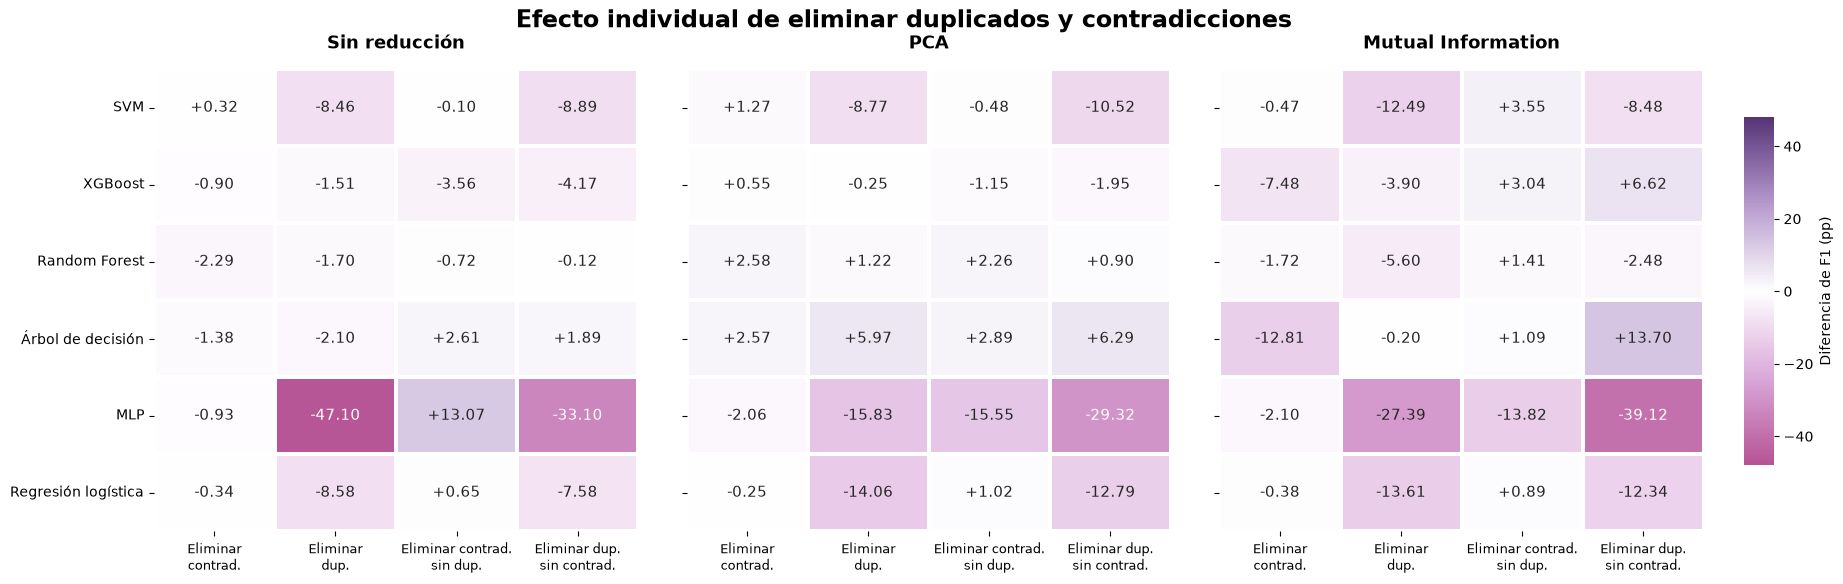

In [168]:
# Paleta divergente del proyecto
paleta_efectos = LinearSegmentedColormap.from_list(
    "rosa_blanco_morado",
    [
        "#B65394",
        "#D9A7D9",
        "#FFFFFF",
        "#B69ACD",
        "#563477"
    ]
)

orden_representaciones = [
    "Sin reducción",
    "PCA",
    "Mutual Information"
]

orden_modelos = [
    "SVM",
    "XGBoost",
    "Random Forest",
    "Árbol de decisión",
    "MLP",
    "Regresión logística"
]

# Escala simétrica y común para los tres mapas
limite = np.ceil(
    resumen_efectos.abs().to_numpy().max()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6),
    sharey=True
)

fig.subplots_adjust(right=0.90, wspace=0.10)

# Espacio para una única barra de color
cbar_ax = fig.add_axes([0.92, 0.22, 0.015, 0.58])

for i, representacion in enumerate(
    orden_representaciones
):

    tabla = resumen_efectos.xs(
        representacion,
        level="Representación"
    ).reindex(orden_modelos)

    sns.heatmap(
        tabla,
        annot=True,
        fmt="+.2f",
        cmap=paleta_efectos,
        center=0,
        vmin=-limite,
        vmax=limite,
        linewidths=1.5,
        linecolor="white",
        annot_kws={"size": 11},
        cbar=(i == 0),
        cbar_ax=cbar_ax if i == 0 else None,
        cbar_kws={
            "label": "Diferencia de F1 (pp)"
        },
        ax=axes[i]
    )

    axes[i].set_title(
        representacion,
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    axes[i].set_xticklabels([
        "Eliminar\ncontrad.",
        "Eliminar\ndup.",
        "Eliminar contrad.\nsin dup.",
        "Eliminar dup.\nsin contrad."
    ], rotation=0, fontsize=9)

    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="y", rotation=0)

fig.suptitle(
    "Efecto individual de eliminar duplicados y contradicciones",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

plt.show()

In [169]:
# Efecto promedio por modelo
efectos_por_modelo = (
    resumen_efectos
    .groupby(level="Modelo")
    .mean()
    .reindex(orden_modelos)
)

display(efectos_por_modelo.round(2))

# Efecto promedio considerando todos los modelos
efectos_generales = pd.DataFrame({
    "Cambio promedio (pp)": resumen_efectos.mean(),
    "Cambio mínimo (pp)": resumen_efectos.min(),
    "Cambio máximo (pp)": resumen_efectos.max(),
    "Mejoras (%)": (
        resumen_efectos.gt(0).mean() * 100
    )
})

display(efectos_generales.round(2))

Tratamiento,Eliminar contradicciones,Eliminar duplicados,Eliminar contradicciones sin duplicados,Eliminar duplicados sin contradicciones
Modelo,,,,
SVM,0.38,-9.91,0.99,-9.29
XGBoost,-2.61,-1.89,-0.56,0.17
Random Forest,-0.48,-2.02,0.98,-0.57
Árbol de decisión,-3.87,1.22,2.20,7.30
MLP,-1.70,-30.11,-5.43,-33.84
Regresión logística,-0.33,-12.08,0.85,-10.91


,Cambio promedio (pp),Cambio mínimo (pp),Cambio máximo (pp),Mejoras (%)
Tratamiento,,,,
Eliminar contradicciones,-1.44,-12.81,2.58,27.78
Eliminar duplicados,-9.13,-47.10,5.97,11.11
Eliminar contradicciones sin duplicados,-0.16,-15.55,13.07,61.11
Eliminar duplicados sin contradicciones,-7.86,-39.12,13.70,27.78


La eliminación de duplicados produjo el mayor impacto negativo sobre el desempeño predictivo, con una disminución promedio del F1 de 9.13 puntos porcentuales. MLP fue el modelo más afectado, seguido de la regresión logística y SVM, mientras que los métodos de ensamble presentaron una menor sensibilidad a este tratamiento.Por otro lado, la eliminación exclusiva de contradicciones produjo una disminución promedio de 1.44 puntos porcentuales. Cuando previamente se habían eliminado los duplicados, su efecto promedio fue prácticamente neutro.

Estos resultados sugirieron que la eliminación de duplicados tuvo un mayor impacto sobre el desempeño que la eliminación de contradicciones. Sin embargo, este efecto no pudo atribuirse exclusivamente a los registros eliminados, debido a que su eliminación también redujo el tamaño del conjunto de entrenamiento y generó un desbalance de clases. Por ello, se consideró necesario analizar el efecto de las técnicas de balanceo sobre estas variantes.

##### 10.2.3. Impacto de las técnicas de balanceo

Se evaluará el efecto de RandomOverSampler y SMOTE-NC sobre las variantes sin duplicados y sin duplicados ni contradicciones. Se calculará la diferencia del F1 respecto a las configuraciones sin balanceo, manteniendo constantes las demás condiciones experimentales. Esto permitirá determinar en qué medida las técnicas de balanceo compensarán la disminución del desempeño observada tras la eliminación de duplicados.

In [170]:
# Seleccionar tratamientos con desbalance de clases
tratamientos_balanceo = [
    "sin_duplicados",
    "sin_duplicados_ni_contradicciones"
]

datos_balanceo = resultados_todos[
    resultados_todos["Tratamiento"].isin(
        tratamientos_balanceo
    )
].copy()

# Comparar estrategias dentro del mismo pliegue
comparacion_balanceo = datos_balanceo.pivot(
    index=[
        "Modelo",
        "Tratamiento",
        "Representación",
        "Pliegue"
    ],
    columns="Balanceo",
    values="F1"
).reset_index()

# Verificar que las comparaciones estén completas
assert len(comparacion_balanceo) == 6 * 2 * 3 * 5

assert not comparacion_balanceo[
    ["sin_balanceo", "oversampling", "SMOTENC"]
].isna().any().any()

# Calcular diferencias en puntos porcentuales
comparacion_balanceo["RandomOverSampler"] = (
    comparacion_balanceo["oversampling"]
    - comparacion_balanceo["sin_balanceo"]
) * 100

comparacion_balanceo["SMOTE-NC"] = (
    comparacion_balanceo["SMOTENC"]
    - comparacion_balanceo["sin_balanceo"]
) * 100

comparacion_balanceo["SMOTE-NC vs. ROS"] = (
    comparacion_balanceo["SMOTENC"]
    - comparacion_balanceo["oversampling"]
) * 100

columnas_balanceo = [
    "RandomOverSampler",
    "SMOTE-NC",
    "SMOTE-NC vs. ROS"
]

# Promediar diferencias entre pliegues
resumen_balanceo = (
    comparacion_balanceo
    .groupby([
        "Modelo",
        "Tratamiento",
        "Representación"
    ])[columnas_balanceo]
    .mean()
)

display(resumen_balanceo.round(2))

Balanceo                                                                  RandomOverSampler  \
Modelo              Tratamiento                       Representación                          
MLP                 sin_duplicados                    Mutual Information              24.76   
                                                      PCA                             11.46   
                                                      Sin reducción                   42.57   
                    sin_duplicados_ni_contradicciones Mutual Information              28.83   
                                                      PCA                             28.95   
                                                      Sin reducción                   31.16   
Random Forest       sin_duplicados                    Mutual Information               3.05   
                                                      PCA                              0.27   
                                                      Sin reducción                    0.39   
                    sin_duplicados_ni_contradicciones Mutual Information               2.06   
                                                      PCA                              0.64   
                                                      Sin reducción                    0.41   
Regresión logística sin_duplicados                    Mutual Information               9.62   
                                                      PCA                             13.68   
                                                      Sin reducción                    9.30   
                    sin_duplicados_ni_contradicciones Mutual Information               7.38   
                                                      PCA                             12.27   
                                                      Sin reducción                    7.92   
SVM                 sin_duplicados                    Mutual Information              11.25   
                                                      PCA                             13.44   
                                                      Sin reducción                   11.89   
                    sin_duplicados_ni_contradicciones Mutual Information               7.33   
                                                      PCA                             12.83   
                                                      Sin reducción                   11.30   
XGBoost             sin_duplicados                    Mutual Information               0.82   
                                                      PCA                             -5.17   
                                                      Sin reducción                    0.55   
                    sin_duplicados_ni_contradicciones Mutual Information              -1.76   
                                                      PCA                              4.00   
                                                      Sin reducción                    1.99   
Árbol de decisión   sin_duplicados                    Mutual Information              -2.46   
                                                      PCA                             -3.81   
                                                      Sin reducción                    3.41   
                    sin_duplicados_ni_contradicciones Mutual Information             -13.24   
                                                      PCA                             -4.91   
                                                      Sin reducción                   -1.41   

Balanceo                                                                  SMOTE-NC  \
Modelo              Tratamiento                       Representación                 
MLP                 sin_duplicados                    Mutual Information     27.27   
                                                      PCA                    10.87   
                                             

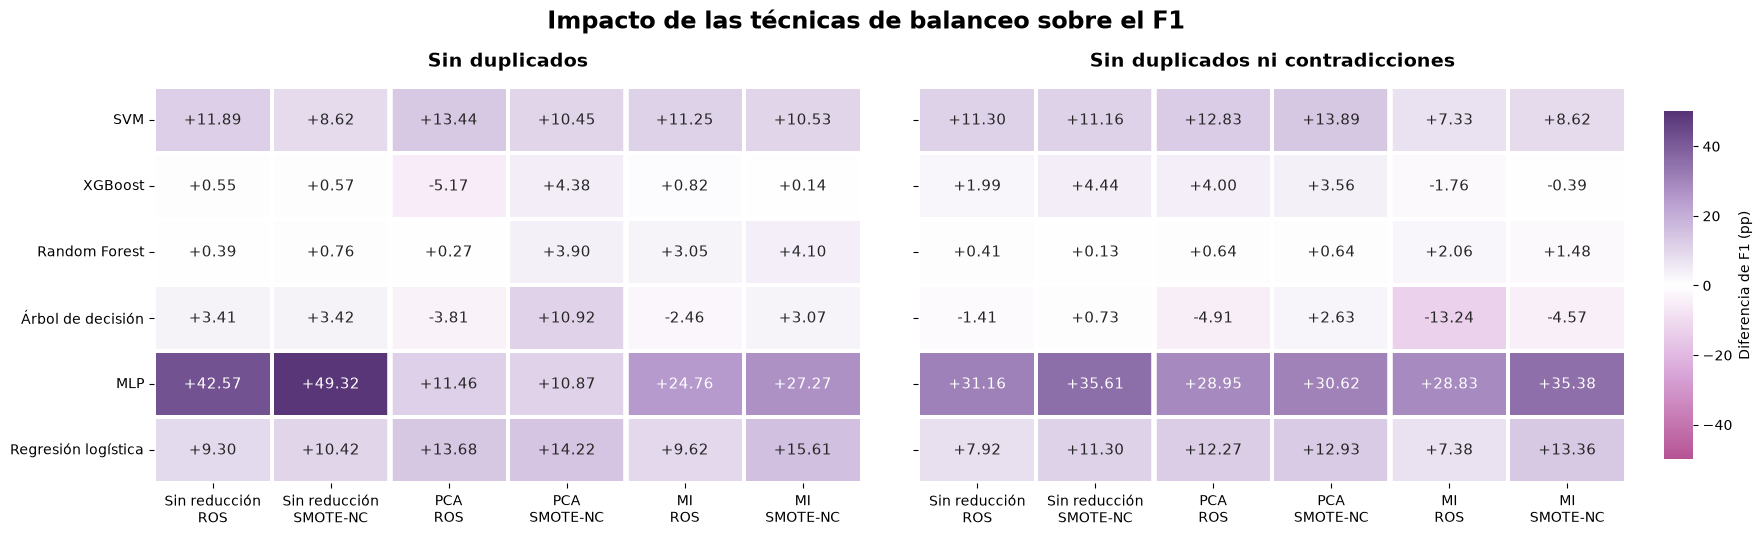

In [171]:
# Orden de las representaciones
orden_representaciones = [
    "Sin reducción",
    "PCA",
    "Mutual Information"
]

orden_modelos = [
    "SVM",
    "XGBoost",
    "Random Forest",
    "Árbol de decisión",
    "MLP",
    "Regresión logística"
]

tecnicas_balanceo = [
    "RandomOverSampler",
    "SMOTE-NC"
]

nombres_tratamientos = {
    "sin_duplicados": "Sin duplicados",
    "sin_duplicados_ni_contradicciones":
        "Sin duplicados ni contradicciones"
}

# Escala simétrica común
limite = max(
    1,
    np.ceil(
        resumen_balanceo[tecnicas_balanceo]
        .abs().to_numpy().max()
    )
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 6),
    sharey=True
)

fig.subplots_adjust(
    right=0.90,
    wspace=0.08,
    bottom=0.18,
    top=0.84
)

# Barra de color compartida
cbar_ax = fig.add_axes(
    [0.92, 0.22, 0.015, 0.58]
)

for i, tratamiento in enumerate(
    tratamientos_balanceo
):

    tabla = (
        resumen_balanceo
        .xs(tratamiento, level="Tratamiento")
        [tecnicas_balanceo]
        .unstack("Representación")
        .swaplevel(axis=1)
    )

    columnas_ordenadas = pd.MultiIndex.from_product([
        orden_representaciones,
        tecnicas_balanceo
    ])

    tabla = tabla.reindex(
        index=orden_modelos,
        columns=columnas_ordenadas
    )

    sns.heatmap(
        tabla,
        annot=True,
        fmt="+.2f",
        cmap=paleta_efectos,
        center=0,
        vmin=-limite,
        vmax=limite,
        linewidths=1.5,
        linecolor="white",
        annot_kws={"size": 11},
        cbar=(i == 0),
        cbar_ax=cbar_ax if i == 0 else None,
        cbar_kws={
            "label": "Diferencia de F1 (pp)"
        },
        ax=axes[i]
    )

    axes[i].set_title(
        nombres_tratamientos[tratamiento],
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    axes[i].set_xticklabels([
        "Sin reducción\nROS",
        "Sin reducción\nSMOTE-NC",
        "PCA\nROS",
        "PCA\nSMOTE-NC",
        "MI\nROS",
        "MI\nSMOTE-NC"
    ], rotation=0, fontsize=10)

    # Separar representaciones
    for posicion in [2, 4]:
        axes[i].axvline(
            posicion,
            color="white",
            linewidth=4
        )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="y", rotation=0)

fig.suptitle(
    "Impacto de las técnicas de balanceo sobre el F1",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

plt.show()

In [172]:
# Efecto promedio por modelo
balanceo_por_modelo = (
    resumen_balanceo
    .groupby(level="Modelo")
    .mean()
    .reindex(orden_modelos)
)

display(balanceo_por_modelo.round(2))

# Efecto promedio por tratamiento
balanceo_por_tratamiento = (
    resumen_balanceo
    .groupby(level="Tratamiento")
    .mean()
    .reindex(tratamientos_balanceo)
)

display(balanceo_por_tratamiento.round(2))

# Resumen general
balanceo_general = pd.DataFrame({
    "Cambio promedio (pp)": resumen_balanceo.mean(),
    "Cambio mínimo (pp)": resumen_balanceo.min(),
    "Cambio máximo (pp)": resumen_balanceo.max(),
    "Mejoras (%)": (
        resumen_balanceo.gt(0).mean() * 100
    )
})

display(balanceo_general.round(2))

Balanceo,RandomOverSampler,SMOTE-NC,SMOTE-NC vs. ROS
Modelo,,,
SVM,11.34,10.55,-0.79
XGBoost,0.07,2.12,2.05
Random Forest,1.14,1.83,0.69
Árbol de decisión,-3.74,2.70,6.44
MLP,27.96,31.51,3.56
Regresión logística,10.03,12.97,2.94


Balanceo,RandomOverSampler,SMOTE-NC,SMOTE-NC vs. ROS
Tratamiento,,,
sin_duplicados,8.06,10.48,2.42
sin_duplicados_ni_contradicciones,7.54,10.08,2.54


,Cambio promedio (pp),Cambio mínimo (pp),Cambio máximo (pp),Mejoras (%)
Balanceo,,,,
RandomOverSampler,7.80,-13.24,42.57,80.56
SMOTE-NC,10.28,-4.57,49.32,94.44
SMOTE-NC vs. ROS,2.48,-3.27,14.73,72.22


Las técnicas de balanceo mejoraron el desempeño de la mayoría de las configuraciones sin duplicados. MLP fue el modelo más beneficiado, con incrementos de hasta 49.32 puntos porcentuales en el F1, seguido de la regresión logística y SVM. Random Forest presentó mejoras moderadas, mientras que XGBoost y el árbol de decisión mostraron resultados variables según la representación de características utilizada. En general, SMOTE-NC fue más favorable que RandomOverSampler.

Estos resultados sugirieron que el desbalance de clases generado tras la eliminación de duplicados contribuyó a la disminución del desempeño predictivo. Sin embargo, no fue posible establecer que este fuera el único factor responsable, debido a la reducción simultánea del tamaño del conjunto de entrenamiento.

#### 10.3. Efecto de la representación de características*

##### 10.3.1. Comparación general de representaciones

Se comparará el mejor F1 promedio obtenido por cada clasificador para las tres representaciones de características, considerando las diferentes estrategias de tratamiento de datos y balanceo. Esto permitirá identificar si la selección o reducción de características resultará favorable para cada modelo.

In [173]:
# Calcular métricas promedio por configuración
resumen_representaciones = (
    resultados_todos
    .groupby([
        "Modelo",
        "Tratamiento",
        "Balanceo",
        "Representación"
    ], as_index=False)
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std")
    )
)

# Seleccionar la mejor configuración por representación
mejores_representaciones = (
    resumen_representaciones
    .sort_values(
        ["F1_promedio", "F1_std"],
        ascending=[False, True]
    )
    .drop_duplicates(
        subset=["Modelo", "Representación"]
    )
)

orden_modelos = [
    "SVM",
    "XGBoost",
    "Random Forest",
    "Árbol de decisión",
    "MLP",
    "Regresión logística"
]

orden_representaciones = [
    "Sin reducción",
    "PCA",
    "Mutual Information"
]

# Construir tabla comparativa
tabla_representaciones = (
    mejores_representaciones
    .pivot(
        index="Modelo",
        columns="Representación",
        values="F1_promedio"
    )
    .reindex(
        index=orden_modelos,
        columns=orden_representaciones
    )
)

# Verificar resultados
assert tabla_representaciones.shape == (6, 3)
assert not tabla_representaciones.isna().any().any()

display(tabla_representaciones.round(4))

Representación,Sin reducción,PCA,Mutual Information
Modelo,,,
SVM,0.9056,0.9045,0.8681
XGBoost,0.9056,0.8786,0.8962
Random Forest,0.8855,0.8748,0.8960
Árbol de decisión,0.8856,0.8516,0.8737
MLP,0.8625,0.8366,0.8118
Regresión logística,0.8097,0.7837,0.7804


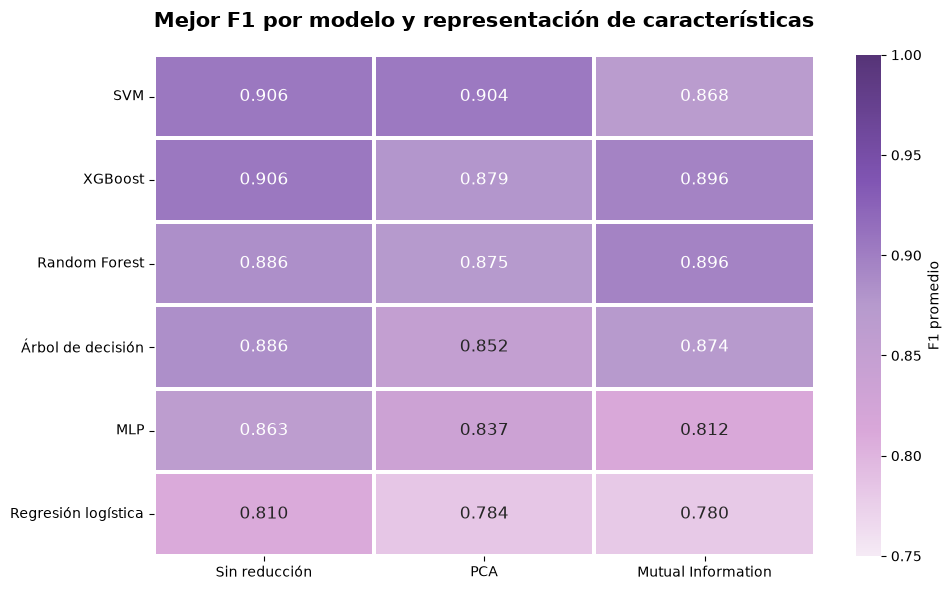

In [174]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    tabla_representaciones,
    annot=True,
    fmt=".3f",
    cmap=paleta_morada,
    linewidths=1.5,
    linecolor="white",
    vmin=0.75,
    vmax=1,
    annot_kws={"size": 12},
    cbar_kws={"label": "F1 promedio"},
    ax=ax
)

ax.set_title(
    "Mejor F1 por modelo y representación de características",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", rotation=0)

plt.tight_layout()
plt.show()

Cinco de los seis clasificadores alcanzaron su mejor desempeño sin aplicar técnicas de selección o reducción de características. Random Forest fue la única excepción, obteniendo su mayor F1 (0.8960) mediante Mutual Information. Aunque PCA no fue la representación óptima para ningún clasificador, SVM presentó un desempeño prácticamente equivalente al obtenido con todas las características, con una diferencia de únicamente 0.11 puntos porcentuales.

En general, conservar las características originales resultó más favorable. Sin embargo, estos resultados también mostraron que la utilidad de las técnicas de selección y reducción dependió del clasificador utilizado.

#### 10.4. Síntesis de resultados iniciales

Se resumirán los resultados de la evaluación inicial para identificar los modelos con mayor potencial predictivo. La selección considerará el F1 promedio, su variabilidad entre pliegues y la complejidad de los algoritmos.

Estos resultados servirán como referencia para la optimización de hiperparámetros. Las conclusiones definitivas sobre el desempeño y la capacidad de generalización se establecerán después de las evaluaciones adicionales.

In [175]:
# Consolidar resultados de las configuraciones experimentales
ranking_modelos = (
    resultados_todos
    .groupby([
        "Modelo",
        "Tratamiento",
        "Balanceo",
        "Representación"
    ], as_index=False)
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .sort_values(
        ["F1_promedio", "F1_std"],
        ascending=[False, True]
    )
    .drop_duplicates(subset="Modelo")
    .reset_index(drop=True)
)

# Agregar posición en el ranking
ranking_modelos.insert(
    0, "Ranking", range(1, len(ranking_modelos) + 1)
)

print("Ranking final de clasificadores:")
display(ranking_modelos.round(4))

# Seleccionar los tres mejores modelos
modelos_seleccionados = ranking_modelos.head(3).copy()

print("\nModelos seleccionados para optimización:")
display(modelos_seleccionados.round(4))

# Resumen de evaluaciones
print("\nConfiguraciones experimentales:",
      len(resultados_todos) // 5)

print("Evaluaciones realizadas:",
      len(resultados_todos))

Ranking final de clasificadores:


,Ranking,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,1,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,2,XGBoost,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
2,3,Random Forest,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845
3,4,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
4,5,MLP,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538
5,6,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936



Modelos seleccionados para optimización:


,Ranking,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,1,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,2,XGBoost,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
2,3,Random Forest,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845



Configuraciones experimentales: 144
Evaluaciones realizadas: 720


SVM, XGBoost y Random Forest presentaron los mayores valores de F1 promedio, por lo que fueron seleccionados para la optimización de hiperparámetros. SVM y XGBoost alcanzaron un F1 de 0.9056, aunque XGBoost presentó una menor variabilidad entre los pliegues de validación. Random Forest obtuvo un F1 de 0.8960 y fue el único clasificador que alcanzó su mejor desempeño mediante selección de características.

Por otro lado, MLP no superó el desempeño de los mejores modelos tradicionales y de ensamble, lo que mostró que una mayor complejidad del modelo no necesariamente se tradujo en un mejor desempeño predictivo para este conjunto de datos.

##### 10.4.1. Distribución del F1 de los modelos seleccionados

Se analizará la distribución del F1 de los tres clasificadores seleccionados mediante diagramas de caja, considerando los cinco pliegues de validación cruzada. Estos resultados servirán como referencia para evaluar posteriormente el efecto de la optimización de hiperparámetros.

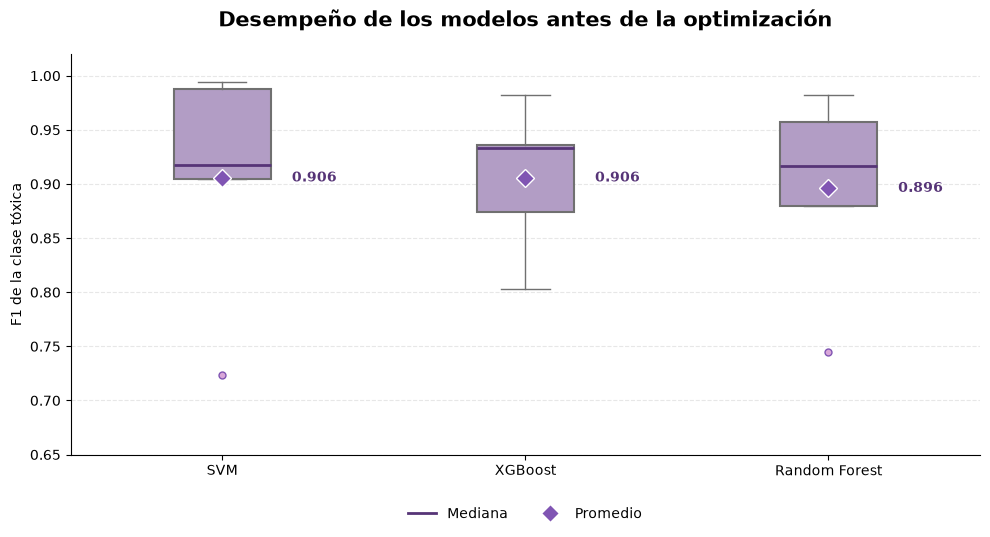

Modelo,SVM,XGBoost,Random Forest
Pliegue,,,
1,0.9176,0.9359,0.9818
2,0.7234,0.8028,0.7451
3,0.9880,0.9820,0.9576
4,0.9048,0.8738,0.8793
5,0.9943,0.9333,0.9162


In [176]:
# Recuperar las mejores configuraciones seleccionadas
columnas_config = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación"
]

resultados_preliminares = resultados_todos.merge(
    modelos_seleccionados[columnas_config],
    on=columnas_config,
    how="inner"
)

orden_finalistas = [
    "SVM",
    "XGBoost",
    "Random Forest"
]

# Verificar los cinco pliegues por modelo
assert len(resultados_preliminares) == 15

datos_boxplot = [
    resultados_preliminares.loc[
        resultados_preliminares["Modelo"] == modelo,
        "F1"
    ].to_numpy()
    for modelo in orden_finalistas
]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.boxplot(
    datos_boxplot,
    tick_labels=orden_finalistas,
    patch_artist=True,
    widths=0.32,
    showmeans=True,
    boxprops={
        "facecolor": "#B29DC5",
        "edgecolor": "#707070",
        "linewidth": 1.5
    },
    medianprops={
        "color": "#563477",
        "linewidth": 2
    },
    meanprops={
        "marker": "D",
        "markerfacecolor": "#8055B3",
        "markeredgecolor": "white",
        "markersize": 9
    },
    whiskerprops={"color": "#707070"},
    capprops={"color": "#707070"},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#D9A7D9",
        "markeredgecolor": "#8055B3",
        "markersize": 5
    }
)

# Etiquetas del F1 promedio
for i, valores in enumerate(datos_boxplot, start=1):
    promedio = np.mean(valores)

    ax.text(
        i + 0.23,
        promedio,
        f"{promedio:.3f}",
        color="#563477",
        fontweight="bold",
        va="center"
    )

leyenda = [
    Line2D([0], [0], color="#563477",
           linewidth=2, label="Mediana"),
    Line2D([0], [0], marker="D",
           color="none",
           markerfacecolor="#8055B3",
           markeredgecolor="white",
           markersize=9,
           label="Promedio")
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

ax.set_title(
    "Desempeño de los modelos antes de la optimización",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("F1 de la clase tóxica")
ax.set_ylim(0.65, 1.02)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

# Resultados individuales por pliegue
f1_preliminar_por_pliegue = (
    resultados_preliminares
    .pivot(
        index="Pliegue",
        columns="Modelo",
        values="F1"
    )
    .reindex(columns=orden_finalistas)
)

display(f1_preliminar_por_pliegue.round(4))

Estos resultados se utilizarán como referencia para determinar si la optimización de hiperparámetros permitirá mejorar tanto el desempeño predictivo como su estabilidad entre pliegues.

##### 10.4.2. Matrices de confusión y análisis de errores

Se construirán las matrices de confusión de los tres modelos seleccionados a partir de las predicciones obtenidas durante la validación cruzada. Se analizarán los falsos positivos y falsos negativos, así como la coincidencia de los errores entre clasificadores. Las predicciones se conservarán para comparar posteriormente los errores cometidos antes y después de la optimización de hiperparámetros.

In [177]:
# Recuperar los pipelines originales
pipelines_preliminares = {
    "SVM": pipelines_svm["Sin reducción"],
    "XGBoost": pipelines_xgb["Sin reducción"],
    "Random Forest": pipelines_rf["Mutual Information"]
}

# Configuraciones seleccionadas
configuraciones_preliminares = {
    "SVM": {
        "tratamiento": "sin_duplicados",
        "balanceo": "oversampling"
    },
    "XGBoost": {
        "tratamiento": "original",
        "balanceo": "sin_balanceo"
    },
    "Random Forest": {
        "tratamiento": "original",
        "balanceo": "sin_balanceo"
    }
}

predicciones_preliminares = []

for nombre, config in configuraciones_preliminares.items():

    print(f"Evaluando {nombre}...")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, start=1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()
        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Aplicar tratamiento únicamente al entrenamiento
        datos_train = tratar_duplicados(
            df_train,
            config["tratamiento"]
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Reproducir el balanceo de la evaluación inicial
        if config["balanceo"] != "sin_balanceo":

            imputador = SimpleImputer(strategy="median")

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[config["balanceo"]]
            )

            X_train, y_train = sampler.fit_resample(
                X_train, y_train
            )

        # Entrenar modelo preliminar
        modelo = clone(pipelines_preliminares[nombre])
        modelo.fit(X_train, y_train)

        # Predicciones sobre validación
        y_pred = modelo.predict(X_val)

        # Guardar predicciones individuales
        predicciones_preliminares.append(
            pd.DataFrame({
                "Modelo": nombre,
                "Observación": idx_val,
                "Pliegue": pliegue,
                "NPs": X_val["NPs"].to_numpy(),
                "Real": y_val.to_numpy(),
                "Predicción": y_pred
            })
        )

        print(
            f"  Pliegue {pliegue}/5 | "
            f"F1: {f1_score(y_val, y_pred, zero_division=0):.4f}"
        )

# Consolidar predicciones
predicciones_preliminares = pd.concat(
    predicciones_preliminares,
    ignore_index=True
)

# Identificar errores
predicciones_preliminares["Error"] = (
    predicciones_preliminares["Real"]
    != predicciones_preliminares["Predicción"]
)

# Verificar que cada observación se evaluó una vez por modelo
assert len(predicciones_preliminares) == 3 * len(X)

assert not predicciones_preliminares.duplicated(
    subset=["Modelo", "Observación"]
).any()

# Verificar que se reprodujeron los F1 originales
for (nombre, pliegue), datos in (
    predicciones_preliminares.groupby(["Modelo", "Pliegue"])
):
    f1_recalculado = f1_score(
        datos["Real"],
        datos["Predicción"],
        zero_division=0
    )

    f1_original = f1_preliminar_por_pliegue.loc[
        pliegue, nombre
    ]

    assert np.isclose(f1_recalculado, f1_original), (
        f"El F1 no coincide: {nombre}, pliegue {pliegue}"
    )

print("\nPredicciones guardadas:",
      len(predicciones_preliminares))

print("Verificación del F1 original completada.")

display(predicciones_preliminares.head())

Evaluando SVM...
  Pliegue 1/5 | F1: 0.9176
  Pliegue 2/5 | F1: 0.7234
  Pliegue 3/5 | F1: 0.9880
  Pliegue 4/5 | F1: 0.9048
  Pliegue 5/5 | F1: 0.9943
Evaluando XGBoost...
  Pliegue 1/5 | F1: 0.9359
  Pliegue 2/5 | F1: 0.8028
  Pliegue 3/5 | F1: 0.9820
  Pliegue 4/5 | F1: 0.8738
  Pliegue 5/5 | F1: 0.9333
Evaluando Random Forest...
  Pliegue 1/5 | F1: 0.9818
  Pliegue 2/5 | F1: 0.7451
  Pliegue 3/5 | F1: 0.9576
  Pliegue 4/5 | F1: 0.8793
  Pliegue 5/5 | F1: 0.9162

Predicciones guardadas: 2643
Verificación del F1 original completada.


,Modelo,Observación,Pliegue,NPs,Real,Predicción,Error
0,SVM,18,1,CuO,0,1,True
1,SVM,19,1,CuO,0,1,True
2,SVM,20,1,CuO,0,1,True
3,SVM,21,1,CuO,0,1,True
4,SVM,22,1,CuO,0,1,True


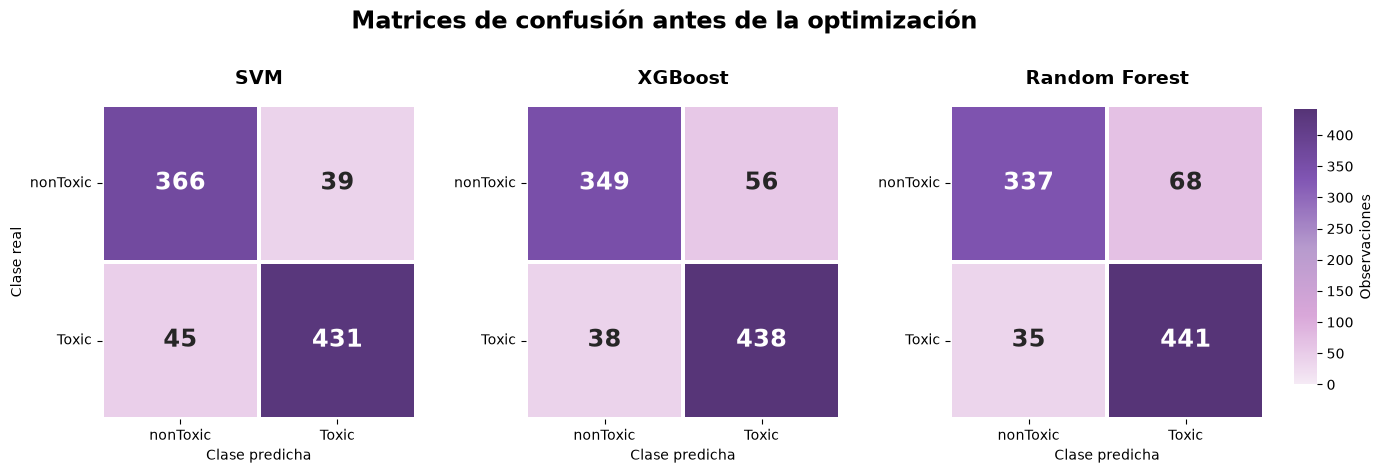

In [178]:
orden_finalistas = [
    "SVM",
    "XGBoost",
    "Random Forest"
]

matrices_preliminares = {}

# Calcular matrices de confusión
for nombre in orden_finalistas:

    datos = predicciones_preliminares[
        predicciones_preliminares["Modelo"] == nombre
    ]

    matrices_preliminares[nombre] = confusion_matrix(
        datos["Real"],
        datos["Predicción"],
        labels=[0, 1]
    )

# Escala común para las tres matrices
vmax = max(
    matriz.max()
    for matriz in matrices_preliminares.values()
)

# Visualización
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

fig.subplots_adjust(
    right=0.90,
    wspace=0.35,
    top=0.82
)

# Barra de color compartida
cbar_ax = fig.add_axes(
    [0.92, 0.22, 0.015, 0.55]
)

for i, nombre in enumerate(orden_finalistas):

    sns.heatmap(
        matrices_preliminares[nombre],
        annot=True,
        fmt="d",
        cmap=paleta_morada,
        vmin=0,
        vmax=vmax,
        square=True,
        linewidths=1.5,
        linecolor="white",
        xticklabels=["nonToxic", "Toxic"],
        yticklabels=["nonToxic", "Toxic"],
        annot_kws={
            "size": 17,
            "fontweight": "bold"
        },
        cbar=(i == 0),
        cbar_ax=cbar_ax if i == 0 else None,
        cbar_kws={"label": "Observaciones"},
        ax=axes[i]
    )

    axes[i].set_title(
        nombre,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    axes[i].set_xlabel("Clase predicha")
    axes[i].set_ylabel(
        "Clase real" if i == 0 else ""
    )

    axes[i].tick_params(axis="both", rotation=0)

fig.suptitle(
    "Matrices de confusión antes de la optimización",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

plt.show()

In [179]:
resumen_errores_preliminares = []

for nombre in orden_finalistas:

    vn, fp, fn, vp = (
        matrices_preliminares[nombre].ravel()
    )

    resumen_errores_preliminares.append({
        "Modelo": nombre,
        "Verdaderos negativos": vn,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
        "Verdaderos positivos": vp,
        "Errores totales": fp + fn,
        "Precisión": vp / (vp + fp),
        "Sensibilidad": vp / (vp + fn),
        "Especificidad": vn / (vn + fp),
        "F1 global": 2 * vp / (2 * vp + fp + fn)
    })

resumen_errores_preliminares = pd.DataFrame(
    resumen_errores_preliminares
)

display(resumen_errores_preliminares.round(4))

,Modelo,Verdaderos negativos,Falsos positivos,Falsos negativos,Verdaderos positivos,Errores totales,Precisión,Sensibilidad,Especificidad,F1 global
0,SVM,366,39,45,431,84,0.9170,0.9055,0.9037,0.9112
1,XGBoost,349,56,38,438,94,0.8866,0.9202,0.8617,0.9031
2,Random Forest,337,68,35,441,103,0.8664,0.9265,0.8321,0.8954


SVM presentó la menor cantidad de errores totales (84), así como la mayor precisión y especificidad. Sin embargo, Random Forest obtuvo la mayor sensibilidad (92.65%), identificando correctamente más observaciones tóxicas y reduciendo los falsos negativos a 35. XGBoost presentó un comportamiento intermedio entre ambos clasificadores.

Estos resultados mostraron que, a pesar de obtener valores similares de F1, los modelos presentaron diferentes patrones de error. En el contexto de la predicción de toxicidad, la reducción de falsos negativos resultó particularmente relevante debido al riesgo de clasificar una nanopartícula tóxica como no tóxica.

##### 10.4.3. Coincidencia de errores entre clasificadores

Se analizará la coincidencia de errores entre SVM, XGBoost y Random Forest, identificando las observaciones clasificadas incorrectamente por uno, dos o los tres modelos. Se utilizará el índice de Jaccard para cuantificar la similitud entre los conjuntos de errores de cada clasificador. Estos resultados servirán como referencia para evaluar los cambios en los patrones de error después de la optimización de hiperparámetros.

In [180]:
# Construir tabla de predicciones por observación
errores_preliminares = (
    predicciones_preliminares
    .pivot(
        index=["Observación", "Pliegue", "NPs", "Real"],
        columns="Modelo",
        values="Error"
    )
    .reset_index()
)

# Modelos seleccionados
orden_finalistas = [
    "SVM",
    "XGBoost",
    "Random Forest"
]

# Verificar que todas las observaciones estén completas
assert len(errores_preliminares) == len(X)

assert not errores_preliminares[
    orden_finalistas
].isna().any().any()

# Número de modelos que clasificaron mal cada observación
errores_preliminares["Número de modelos incorrectos"] = (
    errores_preliminares[orden_finalistas]
    .sum(axis=1)
    .astype(int)
)

# Resumen de coincidencias
resumen_coincidencias = (
    errores_preliminares["Número de modelos incorrectos"]
    .value_counts()
    .reindex(range(4), fill_value=0)
    .sort_index()
    .rename_axis("Modelos incorrectos")
    .reset_index(name="Observaciones")
)

resumen_coincidencias["Porcentaje (%)"] = (
    resumen_coincidencias["Observaciones"]
    / len(errores_preliminares) * 100
)

display(resumen_coincidencias.round(2))

,Modelos incorrectos,Observaciones,Porcentaje (%)
0,0,726,82.41
1,1,77,8.74
2,2,30,3.41
3,3,48,5.45


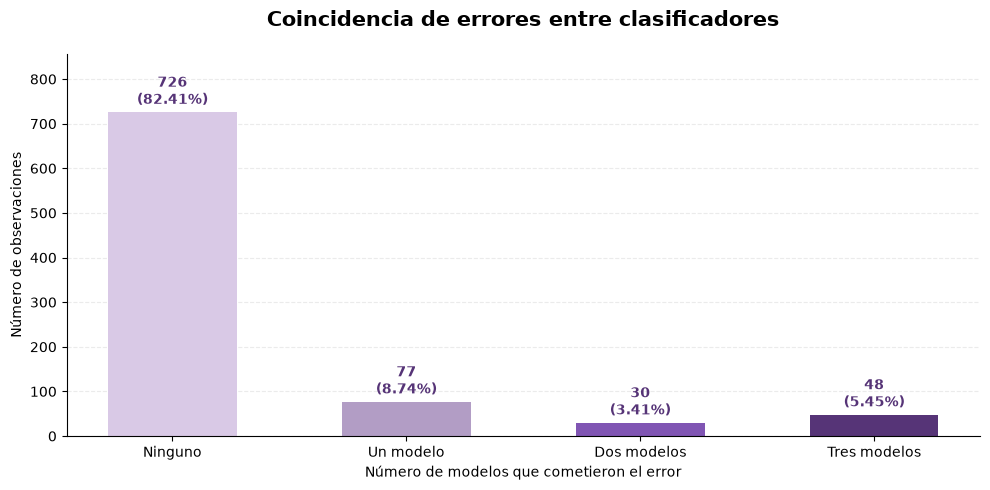

In [181]:
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    ["Ninguno", "Un modelo", "Dos modelos", "Tres modelos"],
    resumen_coincidencias["Observaciones"],
    color=[
        "#D9C9E6",
        "#B29DC5",
        "#8055B3",
        "#563477"
    ],
    width=0.55
)

for barra, porcentaje in zip(
    barras,
    resumen_coincidencias["Porcentaje (%)"]
):
    altura = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 8,
        f"{int(altura)}\n({porcentaje:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        color="#563477"
    )

ax.set_title(
    "Coincidencia de errores entre clasificadores",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Número de modelos que cometieron el error")
ax.set_ylabel("Número de observaciones")

ax.set_ylim(
    0,
    resumen_coincidencias["Observaciones"].max() * 1.18
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [182]:
# Inicializar matrices
matriz_jaccard = pd.DataFrame(
    index=orden_finalistas,
    columns=orden_finalistas,
    dtype=float
)

matriz_errores_comunes = pd.DataFrame(
    index=orden_finalistas,
    columns=orden_finalistas,
    dtype=int
)

# Comparar cada par de modelos
for modelo_a in orden_finalistas:
    for modelo_b in orden_finalistas:

        error_a = errores_preliminares[modelo_a].astype(bool)
        error_b = errores_preliminares[modelo_b].astype(bool)

        matriz_jaccard.loc[modelo_a, modelo_b] = (
            jaccard_score(
                error_a,
                error_b,
                zero_division=0
            )
        )

        matriz_errores_comunes.loc[modelo_a, modelo_b] = (
            (error_a & error_b).sum()
        )

matriz_errores_comunes = matriz_errores_comunes.astype(int)

print("Índice de Jaccard:")
display(matriz_jaccard.round(4))

print("Número de errores compartidos:")
display(matriz_errores_comunes)

Índice de Jaccard:


,SVM,XGBoost,Random Forest
SVM,1.0000,0.3906,0.3750
XGBoost,0.3906,1.0000,0.5887
Random Forest,0.3750,0.5887,1.0000


Número de errores compartidos:


,SVM,XGBoost,Random Forest
SVM,84,50,51
XGBoost,50,94,73
Random Forest,51,73,103


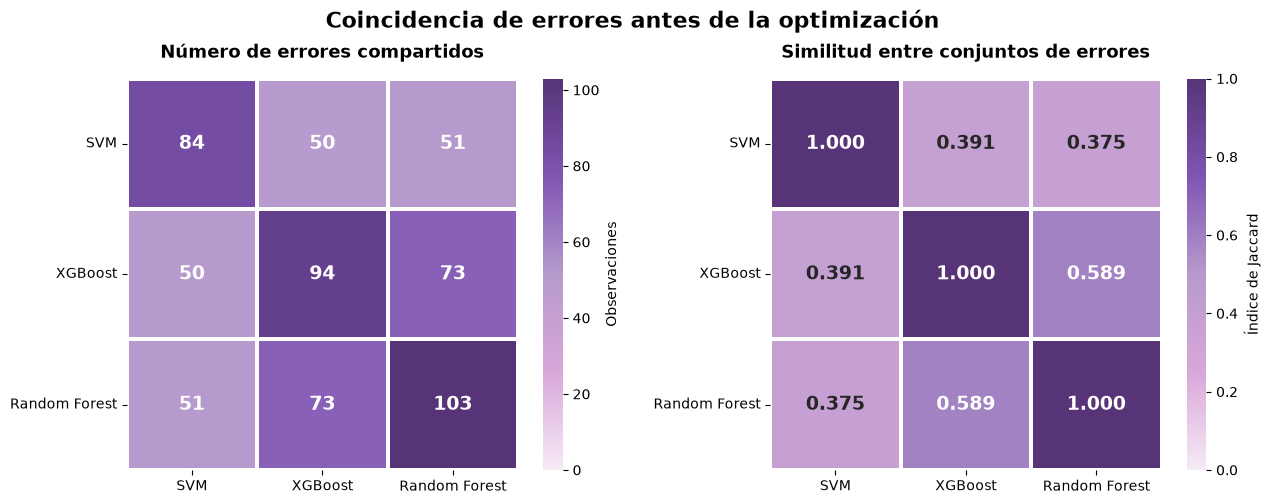

In [183]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Número de errores compartidos
sns.heatmap(
    matriz_errores_comunes,
    annot=True,
    fmt="d",
    cmap=paleta_morada,
    vmin=0,
    square=True,
    linewidths=1.5,
    linecolor="white",
    annot_kws={"size": 14, "fontweight": "bold"},
    cbar_kws={"label": "Observaciones"},
    ax=axes[0]
)

axes[0].set_title(
    "Número de errores compartidos",
    fontsize=13,
    fontweight="bold",
    pad=15
)

# Índice de Jaccard
sns.heatmap(
    matriz_jaccard,
    annot=True,
    fmt=".3f",
    cmap=paleta_morada,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=1.5,
    linecolor="white",
    annot_kws={"size": 14, "fontweight": "bold"},
    cbar_kws={"label": "Índice de Jaccard"},
    ax=axes[1]
)

axes[1].set_title(
    "Similitud entre conjuntos de errores",
    fontsize=13,
    fontweight="bold",
    pad=15
)

for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", rotation=0)

fig.suptitle(
    "Coincidencia de errores antes de la optimización",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [184]:
# Identificar errores compartidos por los tres modelos
errores_tres_modelos = errores_preliminares[
    errores_preliminares["Número de modelos incorrectos"] == 3
].copy()

# Identificar el tipo de error
errores_tres_modelos["Tipo de error"] = np.where(
    errores_tres_modelos["Real"] == 1,
    "Falso negativo",
    "Falso positivo"
)

# Resumen por tipo de error
print("Errores compartidos por los tres modelos:")
print(len(errores_tres_modelos))

display(
    errores_tres_modelos["Tipo de error"]
    .value_counts()
    .to_frame("Observaciones")
)

# Resumen por tipo de nanopartícula
errores_comunes_por_np = pd.crosstab(
    errores_tres_modelos["NPs"],
    errores_tres_modelos["Tipo de error"]
).reindex(
    columns=["Falso positivo", "Falso negativo"],
    fill_value=0
)

errores_comunes_por_np["Total"] = (
    errores_comunes_por_np.sum(axis=1)
)

display(errores_comunes_por_np)

# Errores exclusivos de cada modelo
errores_exclusivos = {}

for modelo in orden_finalistas:

    errores_exclusivos[modelo] = (
        errores_preliminares[modelo]
        & (
            errores_preliminares[
                "Número de modelos incorrectos"
            ] == 1
        )
    ).sum()

print("Errores exclusivos por modelo:")

display(
    pd.Series(errores_exclusivos)
    .to_frame("Observaciones")
)

Errores compartidos por los tres modelos:
48


,Observaciones
Tipo de error,
Falso negativo,27
Falso positivo,21


Tipo de error,Falso positivo,Falso negativo,Total
NPs,,,
CuO,1,0,1
ZnO,20,27,47


Errores exclusivos por modelo:


,Observaciones
SVM,31
XGBoost,19
Random Forest,27


XGBoost y Random Forest presentaron la mayor coincidencia de errores, con 73 observaciones compartidas y un índice de Jaccard de 0.589, lo que podría estar relacionado con su naturaleza de modelos basados en árboles. Por su parte, SVM presentó patrones de error menos similares a los de ambos ensambles.

El 82.41% de las observaciones fue clasificado correctamente por los tres modelos, mientras que el 5.45 % (48 observaciones) fue clasificado incorrectamente por todos. Estas últimas representaron casos de especial interés para evaluar si la optimización de hiperparámetros permitió corregir errores persistentes.

### 11. Optimización de hiperparámetros

Después de la evaluación inicial, se optimizarán los hiperparámetros de SVM, Random Forest y XGBoost, seleccionados por su desempeño predictivo.

Se utilizará `RandomizedSearchCV` para explorar distintas combinaciones de hiperparámetros mediante validación cruzada estratificada por grupos, utilizando el F1 de la clase tóxica como métrica principal.

La búsqueda se realizará sobre las configuraciones de preprocesamiento más prometedoras, manteniendo el tratamiento de duplicados, el balanceo y la representación de características dentro del procedimiento de validación. Posteriormente, se compararán los resultados obtenidos antes y después de la optimización.

#### 11.1. Optimización de SVM

Se optimizarán los hiperparámetros del clasificador SVM, que obtuvo uno de los mejores desempeños durante la evaluación inicial. Se utilizará la configuración sin duplicados, con oversampling y sin reducción de características.

La optimización se realizará en dos etapas: primero, una búsqueda aleatoria para identificar combinaciones prometedoras y, posteriormente, una búsqueda más específica alrededor de los mejores valores encontrados.

Se conservará la validación cruzada estratificada por grupos, aplicando la eliminación de duplicados y el balanceo exclusivamente al entrenamiento de cada pliegue para evitar fugas de información.

In [185]:
class ClasificadorSinDuplicados(
    ClassifierMixin, BaseEstimator
):
    def __init__(self, pipeline=None):
        self.pipeline = pipeline

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        y = pd.Series(
            np.asarray(y),
            index=X.index
        )

        # Eliminar duplicados exactos, considerando
        # características y etiqueta.
        datos = X.copy()
        datos["_target_"] = y.to_numpy()

        datos = datos.drop_duplicates()

        X_train = datos.drop(columns="_target_")
        y_train = datos["_target_"]

        self.pipeline_ = clone(self.pipeline)
        self.pipeline_.fit(X_train, y_train)

        self.classes_ = self.pipeline_.classes_
        return self

    def predict(self, X):
        return self.pipeline_.predict(X)

    def predict_proba(self, X):
        return self.pipeline_.predict_proba(X)

    def decision_function(self, X):
        return self.pipeline_.decision_function(X)


# Pipeline: representación, balanceo y SVM
pipeline_svm = ImbPipeline([
    (
        "preprocesamiento",
        clone(representaciones["Sin reducción"])
    ),
    (
        "balanceo",
        RandomOverSampler(random_state=42)
    ),
    (
        "modelo",
        SVC(random_state=42)
    )
])

estimador_svm = ClasificadorSinDuplicados(
    pipeline=pipeline_svm
)

# Validación cruzada por grupos
cv_svm = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métrica principal
f1_toxic = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

print("Preparación de SVM completada.")


Preparación de SVM completada.


##### 11.1.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV`, evaluando 20 combinaciones de hiperparámetros con cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes valores de regularización (`C`), coeficiente gamma (`gamma`) y tipos de kernel (lineal y RBF). El F1 de la clase tóxica se utilizará como métrica principal para seleccionar la mejor configuración.

In [186]:
# Espacio de búsqueda
parametros_svm = [
    {
        "pipeline__modelo__kernel": ["rbf"],
        "pipeline__modelo__C": [
            0.1, 1, 10, 100, 1000
        ],
        "pipeline__modelo__gamma": [
            "scale", 0.001, 0.01, 0.1, 1
        ]
    },
    {
        "pipeline__modelo__kernel": ["linear"],
        "pipeline__modelo__C": [
            0.01, 0.1, 1, 10, 100
        ]
    }
]

# Conservar los mismos pliegues para ambas búsquedas
pliegues_svm = list(
    cv_svm.split(X, y, groups)
)

# Búsqueda aleatoria
busqueda_svm = RandomizedSearchCV(
    estimator=estimador_svm,
    param_distributions=parametros_svm,
    n_iter=20,
    scoring=f1_toxic,
    cv=pliegues_svm,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_svm.fit(X, y)

print("\nMejores hiperparámetros:")
print(busqueda_svm.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_svm.best_score_, 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
{'pipeline__modelo__kernel': 'rbf', 'pipeline__modelo__gamma': 'scale', 'pipeline__modelo__C': 1}

Mejor F1 promedio: 0.8983


In [187]:
# Resultados de la búsqueda inicial
resultados_busqueda_svm = pd.DataFrame(
    busqueda_svm.cv_results_
)

columnas = [
    "param_pipeline__modelo__kernel",
    "param_pipeline__modelo__C",
    "param_pipeline__modelo__gamma",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_svm = (
    resultados_busqueda_svm[columnas]
    .sort_values("rank_test_score")
    .head(10)
)

display(tabla_opt_svm.round(4))


,param_pipeline__modelo__kernel,param_pipeline__modelo__C,param_pipeline__modelo__gamma,mean_test_score,std_test_score,rank_test_score
12,rbf,1.0,scale,0.8983,0.0940,1
4,rbf,1.0,0.1,0.8937,0.0918,2
15,rbf,1000.0,0.01,0.8682,0.0937,3
13,rbf,10.0,0.1,0.8640,0.0978,4
3,rbf,100.0,0.01,0.8590,0.0987,5
1,rbf,100.0,scale,0.8435,0.0724,6
9,rbf,0.1,scale,0.8421,0.0799,7
14,rbf,10.0,0.001,0.8401,0.0803,8
19,rbf,0.1,0.1,0.8400,0.0769,9
8,rbf,10.0,0.01,0.8360,0.0724,10


La búsqueda inicial identificó como mejor configuración un kernel RBF con C = 1 y gamma = scale, alcanzando un F1 promedio de 0.8983 ± 0.0940. Estos valores corresponden a los hiperparámetros predeterminados de SVM, por lo que no se encontró una mejora respecto a la configuración base dentro de las combinaciones evaluadas.

Debido a que varias configuraciones con kernel RBF obtuvieron resultados cercanos, se realizará una búsqueda más específica para explorar valores intermedios de los hiperparámetros.

In [188]:
# Espacio de búsqueda refinado
parametros_svm_refinado = {
    "pipeline__modelo__kernel": ["rbf"],
    "pipeline__modelo__C": [
        0.5, 0.75, 1, 1.5, 2, 3, 5, 7.5, 10
    ],
    "pipeline__modelo__gamma": [
        "scale", 0.03, 0.05, 0.075,
        0.1, 0.15, 0.2
    ]
}

# Búsqueda exhaustiva de 63 combinaciones
busqueda_svm_refinada = GridSearchCV(
    estimator=estimador_svm,
    param_grid=parametros_svm_refinado,
    scoring=f1_toxic,
    cv=pliegues_svm,
    refit=True,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_svm_refinada.fit(X, y)

print("Mejores hiperparámetros:")
print(busqueda_svm_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_svm_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_svm_refinada.cv_results_[
            "std_test_score"
        ][busqueda_svm_refinada.best_index_],
        4
    )
)


Fitting 5 folds for each of 63 candidates, totalling 315 fits
Mejores hiperparámetros:
{'pipeline__modelo__C': 1, 'pipeline__modelo__gamma': 0.15, 'pipeline__modelo__kernel': 'rbf'}

Mejor F1 promedio: 0.9091
Desviación estándar: 0.0775


El refinamiento identificó como mejor configuración un kernel RBF con C = 1 y gamma = 0.15, alcanzando un F1 promedio de 0.9091 ± 0.0775. En comparación con la búsqueda inicial se observó una mejora de 0.0108 puntos y una menor variabilidad entre pliegues. Esto sugiere que un ajuste más específico de gamma puede favorecer el desempeño del clasificador.

Sin embargo, esta mejora corresponde a los resultados de validación utilizados durante la selección de hiperparámetros, por lo que no constituye todavía evidencia de una mejora en datos independientes.

##### 11.1.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y el refinamiento de hiperparámetros de SVM, considerando el F1 promedio y su desviación estándar entre pliegues. Esta comparación permitirá identificar los cambios en el desempeño y seleccionar la configuración final del clasificador para las evaluaciones posteriores.

In [189]:
# Recuperar los mejores resultados de cada búsqueda
busquedas = {
    "Búsqueda inicial": busqueda_svm,
    "Búsqueda refinada": busqueda_svm_refinada
}

comparacion_opt_svm = []

for nombre, busqueda in busquedas.items():

    mejor_idx = busqueda.best_index_

    comparacion_opt_svm.append({
        "Búsqueda": nombre,
        "Kernel": busqueda.best_params_[
            "pipeline__modelo__kernel"
        ],
        "C": busqueda.best_params_[
            "pipeline__modelo__C"
        ],
        "Gamma": busqueda.best_params_.get(
            "pipeline__modelo__gamma", "-"
        ),
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][mejor_idx]
    })

comparacion_opt_svm = pd.DataFrame(
    comparacion_opt_svm
)

display(comparacion_opt_svm.round(4))

,Búsqueda,Kernel,C,Gamma,F1_promedio,F1_std
0,Búsqueda inicial,rbf,1,scale,0.8983,0.0940
1,Búsqueda refinada,rbf,1,0.15,0.9091,0.0775


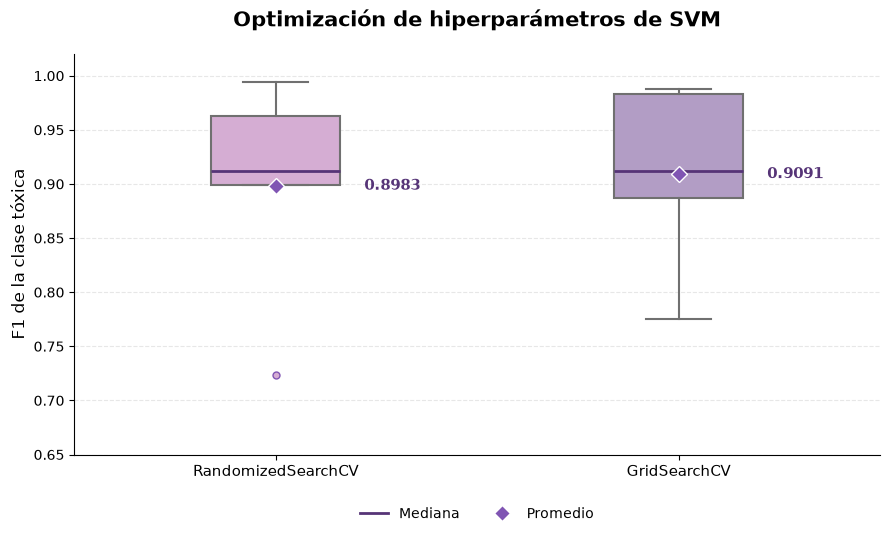

In [190]:
# Recuperar el F1 de cada pliegue de la mejor configuración
def obtener_f1_pliegues(busqueda):

    return np.array([
        busqueda.cv_results_[
            f"split{i}_test_score"
        ][busqueda.best_index_]
        for i in range(busqueda.n_splits_)
    ])


# Resultados de cada estrategia de optimización
datos_boxplot_svm = {
    "RandomizedSearchCV": obtener_f1_pliegues(busqueda_svm),
    "GridSearchCV": obtener_f1_pliegues(busqueda_svm_refinada)
}

# Configuración de la gráfica
fig, ax = plt.subplots(figsize=(9, 5.5))

colores = ["#D5ADD3", "#B29DC5"]

posiciones = np.arange(1, len(datos_boxplot_svm) + 1)

for posicion, (nombre, valores), color in zip(
    posiciones,
    datos_boxplot_svm.items(),
    colores
):

    ax.boxplot(
        valores,
        positions=[posicion],
        widths=0.32,
        patch_artist=True,
        showmeans=True,
        boxprops={
            "facecolor": color,
            "edgecolor": "#707070",
            "linewidth": 1.5
        },
        medianprops={
            "color": "#563477",
            "linewidth": 2
        },
        meanprops={
            "marker": "D",
            "markerfacecolor": "#8055B3",
            "markeredgecolor": "white",
            "markersize": 8
        },
        whiskerprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        capprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        flierprops={
            "marker": "o",
            "markerfacecolor": "#D5ADD3",
            "markeredgecolor": "#8055B3",
            "markersize": 5
        }
    )

    # Etiqueta del F1 promedio
    ax.text(
        posicion + 0.22,
        valores.mean(),
        f"{valores.mean():.4f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

# Configuración de ejes
ax.set_xticks(posiciones)
ax.set_xticklabels(datos_boxplot_svm.keys(), fontsize=11)

ax.set_ylabel("F1 de la clase tóxica", fontsize=12)

ax.set_title(
    "Optimización de hiperparámetros de SVM",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlim(0.5, len(datos_boxplot_svm) + 0.5)
ax.set_ylim(0.65, 1.02)
ax.set_yticks(np.arange(0.65, 1.01, 0.05))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

La búsqueda refinada mediante GridSearchCV incrementó el F1 promedio de la clase tóxica de 0.8983 a 0.9091 y redujo la desviación estándar de 0.0940 a 0.0775. Aunque ambas estrategias presentaron medianas similares, la búsqueda refinada mejoró el desempeño mínimo entre los pliegues.

Respecto a la configuración preliminar de SVM (0.9056), la optimización produjo una mejora de 0.35 puntos porcentuales y una menor variabilidad entre pliegues.

#### 11.2. Optimización de Random Forest

Se optimizarán los hiperparámetros del clasificador Random Forest, que obtuvo un F1 promedio de 0.8960 ± 0.0930 durante la evaluación inicial. Se utilizará la configuración que presentó el mejor desempeño: datos originales, sin balanceo y con selección de características mediante Mutual Information.

Se explorarán hiperparámetros relacionados con la cantidad de árboles, su profundidad y las condiciones de división de los nodos. Se mantendrá la validación cruzada estratificada por grupos, aplicando la selección de características exclusivamente sobre los datos de entrenamiento de cada pliegue. La optimización buscará mejorar el F1 de la clase tóxica sin incrementar innecesariamente la complejidad del modelo.

In [191]:
# Pipeline de Random Forest
pipeline_rf = Pipeline([
    (
        "preprocesamiento",
        clone(representaciones["Mutual Information"])
    ),
    (
        "modelo",
        RandomForestClassifier(
            random_state=42,
            n_jobs=1
        )
    )
])

# Reutilizar los mismos pliegues de SVM
pliegues_rf = pliegues_svm

# Métrica principal
f1_rf = f1_toxic

print("Preparación de Random Forest completada.")
print("Configuración: datos originales, sin balanceo, MI")
print("Número de pliegues:", len(pliegues_rf))

Preparación de Random Forest completada.
Configuración: datos originales, sin balanceo, MI
Número de pliegues: 5


##### 11.2.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV` para optimizar los hiperparámetros de Random Forest. Se evaluarán 30 combinaciones utilizando cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes cantidades de árboles (`n_estimators`), profundidades máximas (`max_depth`), cantidades mínimas de muestras para dividir nodos (`min_samples_split`) y formar hojas (`min_samples_leaf`), así como el número de características consideradas en cada división (`max_features`). La selección de características mediante Mutual Information se realizará dentro de cada pliegue de entrenamiento, utilizando el F1 de la clase tóxica como métrica principal.

In [192]:
# Espacio de búsqueda
parametros_rf = {
    "modelo__n_estimators": [100, 200, 300, 400],
    "modelo__max_depth": [None, 5, 10, 15, 20, 30],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", None]
}

# Búsqueda inicial
busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=30,
    scoring=f1_rf,
    cv=pliegues_rf,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_rf.fit(X, y)

# Resultados principales
mejor_idx = busqueda_rf.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_rf.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_rf.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_rf.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__n_estimators': 100, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 1, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 10}

Mejor F1 promedio: 0.9005
Desviación estándar: 0.0828


In [193]:
resultados_busqueda_rf = pd.DataFrame(
    busqueda_rf.cv_results_
)

columnas_rf = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__min_samples_split",
    "param_modelo__min_samples_leaf",
    "param_modelo__max_features",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_rf = (
    resultados_busqueda_rf[columnas_rf]
    .sort_values("rank_test_score")
    .head(10)
)

display(tabla_opt_rf.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_score,std_test_score,rank_test_score
1,100,10,5,1,sqrt,0.9005,0.0828,1
2,200,30,5,2,log2,0.8917,0.0845,2
5,100,20,5,2,sqrt,0.8917,0.0845,2
16,300,15,2,1,log2,0.8917,0.0845,2
20,100,15,5,2,sqrt,0.8917,0.0845,2
22,200,15,5,2,sqrt,0.8917,0.0845,2
19,300,None,10,1,sqrt,0.8917,0.0845,2
17,300,30,10,2,log2,0.8904,0.0831,8
25,300,15,10,2,sqrt,0.8904,0.0831,8
23,300,None,5,2,log2,0.8862,0.0808,10


La búsqueda inicial identificó como mejor configuración un Random Forest de 100 árboles, profundidad máxima de 10, mínimo de 5 muestras para dividir un nodo y una muestra por hoja, utilizando la raíz cuadrada del número de características en cada división.

Esta configuración obtuvo un F1 promedio de 0.9005 ± 0.0828, ligeramente superior al resultado inicial de 0.8960. También se observó que varias combinaciones con mayor cantidad de árboles y profundidad obtuvieron resultados similares o inferiores, lo que sugiere que incrementar la complejidad del modelo no necesariamente mejora su capacidad predictiva.

##### 11.2.2. Refinamiento de hiperparámetros

A partir de los resultados de la búsqueda inicial, se realizará una exploración más detallada de los hiperparámetros de Random Forest. Se evaluarán 72 combinaciones, considerando valores cercanos a la mejor configuración encontrada. Se mantendrá `max_features="sqrt"` y se explorarán diferentes cantidades de árboles, profundidades máximas y condiciones de división de los nodos.

La evaluación utilizará los mismos cinco pliegues de validación cruzada estratificada por grupos y el F1 de la clase tóxica como métrica principal.

In [194]:
# Espacio de búsqueda refinado
parametros_rf_refinado = {
    "modelo__n_estimators": [75, 100, 150],
    "modelo__max_depth": [8, 10, 12, 15],
    "modelo__min_samples_split": [3, 5, 7],
    "modelo__min_samples_leaf": [1, 2],
    "modelo__max_features": ["sqrt"]
}

# Búsqueda exhaustiva
busqueda_rf_refinada = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf_refinado,
    scoring=f1_rf,
    cv=pliegues_rf,
    refit=True,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_rf_refinada.fit(X, y)

# Resultados principales
mejor_idx = busqueda_rf_refinada.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_rf_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_rf_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_rf_refinada.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Mejores hiperparámetros:
{'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 100}

Mejor F1 promedio: 0.9046
Desviación estándar: 0.084


In [195]:
# Resultados del refinamiento
resultados_refinamiento_rf = pd.DataFrame(
    busqueda_rf_refinada.cv_results_
)

columnas_rf = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__min_samples_split",
    "param_modelo__min_samples_leaf",
    "param_modelo__max_features",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_refinamiento_rf = (
    resultados_refinamiento_rf[columnas_rf]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_refinamiento_rf.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_score,std_test_score,rank_test_score
40,100,12,5,1,sqrt,0.9046,0.0840,1
55,100,15,3,1,sqrt,0.9046,0.0840,1
58,100,15,5,1,sqrt,0.9046,0.0840,1
21,75,10,5,1,sqrt,0.9042,0.0856,4
39,75,12,5,1,sqrt,0.9025,0.0833,5
54,75,15,3,1,sqrt,0.9025,0.0833,5
57,75,15,5,1,sqrt,0.9025,0.0833,5
18,75,10,3,1,sqrt,0.9005,0.0828,8
22,100,10,5,1,sqrt,0.9005,0.0828,8
24,75,10,7,1,sqrt,0.9005,0.0828,8


El refinamiento de hiperparámetros permitió aumentar el F1 promedio de 0.9005 a 0.9046. Tres configuraciones alcanzaron el mismo desempeño, todas con 100 árboles, una muestra mínima por hoja y `max_features="sqrt"`. Se seleccionó la configuración con profundidad máxima de 12 y un mínimo de 5 muestras para dividir un nodo, ya que obtuvo el mejor resultado sin requerir árboles más profundos.

Aunque se observó una mejora respecto a la búsqueda inicial, esta fue pequeña y la desviación estándar aumentó ligeramente. Por ello, no se considera necesario continuar refinando el modelo. Además, los resultados corresponden a los pliegues utilizados durante la optimización y deberán verificarse mediante una evaluación independiente.

##### 11.2.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y del refinamiento de hiperparámetros de Random Forest, considerando el F1 promedio y su desviación estándar entre los cinco pliegues de validación.

Esta comparación permitirá evaluar los cambios en el desempeño y seleccionar la configuración final del modelo para los análisis posteriores.

In [196]:
busquedas_rf = {
    "Búsqueda inicial": busqueda_rf,
    "Búsqueda refinada": busqueda_rf_refinada
}

comparacion_opt_rf = []

for nombre, busqueda in busquedas_rf.items():
    idx = busqueda.best_index_
    params = busqueda.best_params_

    comparacion_opt_rf.append({
        "Búsqueda": nombre,
        "Árboles": params["modelo__n_estimators"],
        "Profundidad": params["modelo__max_depth"],
        "Mín. división": params["modelo__min_samples_split"],
        "Mín. hoja": params["modelo__min_samples_leaf"],
        "Max. características": params["modelo__max_features"],
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][idx]
    })

comparacion_opt_rf = pd.DataFrame(comparacion_opt_rf)

display(comparacion_opt_rf.round(4))

,Búsqueda,Árboles,Profundidad,Mín. división,Mín. hoja,Max. características,F1_promedio,F1_std
0,Búsqueda inicial,100,10,5,1,sqrt,0.9005,0.0828
1,Búsqueda refinada,100,12,5,1,sqrt,0.9046,0.0840


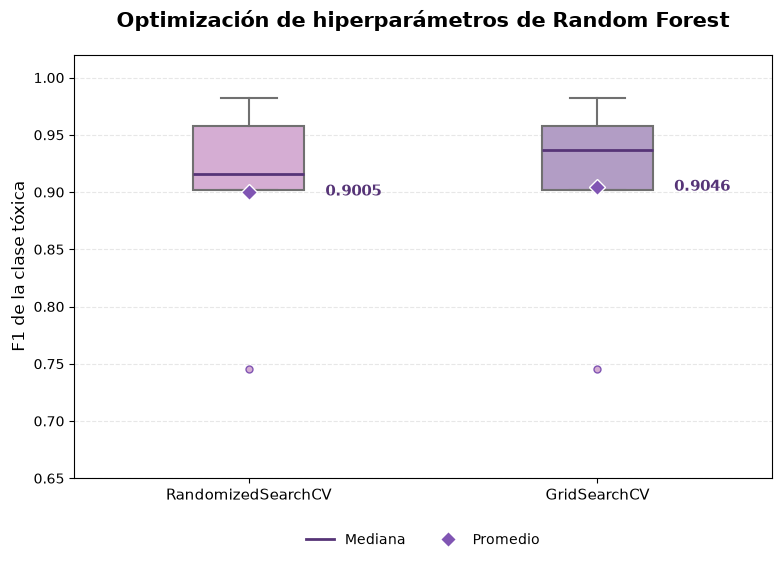

In [197]:
# Recuperar resultados de cada estrategia de optimización
datos_boxplot_rf = {
    "RandomizedSearchCV": obtener_f1_pliegues(busqueda_rf),
    "GridSearchCV": obtener_f1_pliegues(busqueda_rf_refinada)
}

# Configuración de la gráfica
fig, ax = plt.subplots(figsize=(9, 5.5))

colores = ["#D5ADD3", "#B29DC5"]

posiciones = np.arange(1, len(datos_boxplot_rf) + 1)

for posicion, (nombre, valores), color in zip(
    posiciones,
    datos_boxplot_rf.items(),
    colores
):

    ax.boxplot(
        valores,
        positions=[posicion],
        widths=0.32,
        patch_artist=True,
        showmeans=True,
        boxprops={
            "facecolor": color,
            "edgecolor": "#707070",
            "linewidth": 1.5
        },
        medianprops={
            "color": "#563477",
            "linewidth": 2
        },
        meanprops={
            "marker": "D",
            "markerfacecolor": "#8055B3",
            "markeredgecolor": "white",
            "markersize": 8
        },
        whiskerprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        capprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        flierprops={
            "marker": "o",
            "markerfacecolor": "#D5ADD3",
            "markeredgecolor": "#8055B3",
            "markersize": 5
        }
    )

    # Etiqueta del F1 promedio
    ax.text(
        posicion + 0.22,
        valores.mean(),
        f"{valores.mean():.4f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

# Configuración de ejes
ax.set_xticks(posiciones)
ax.set_xticklabels(datos_boxplot_rf.keys(), fontsize=11)

ax.set_ylabel("F1 de la clase tóxica", fontsize=12)

ax.set_title(
    "Optimización de hiperparámetros de Random Forest",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlim(0.5, len(datos_boxplot_rf) + 0.5)
ax.set_ylim(0.65, 1.02)
ax.set_yticks(np.arange(0.65, 1.01, 0.05))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)



La búsqueda refinada mediante GridSearchCV incrementó el F1 promedio de la clase tóxica de 0.9005 a 0.9046, con un ligero aumento en la desviación estándar de 0.0828 a 0.0840. Ambas estrategias presentaron distribuciones similares, aunque la búsqueda refinada obtuvo una mediana superior y mantuvo el mismo desempeño mínimo.

Respecto a la configuración preliminar de Random Forest (0.8960), la optimización produjo una mejora de 0.86 puntos porcentuales y una menor variabilidad entre los pliegues.

#### 11.3. Optimización de XGBoost

Se optimizarán los hiperparámetros del clasificador XGBoost, que obtuvo un F1 promedio de 0.9056 ± 0.0691 durante la evaluación inicial. Se utilizará la configuración que presentó el mejor desempeño: datos originales, sin balanceo y sin reducción de características.

La optimización se enfocará en ajustar la cantidad de árboles, la profundidad máxima, la tasa de aprendizaje y los parámetros de regularización y muestreo. Se mantendrá la validación cruzada estratificada por grupos, utilizando el F1 de la clase tóxica como métrica principal.

In [198]:
# Pipeline de XGBoost
pipeline_xgb = Pipeline([
    (
        "preprocesamiento",
        clone(representaciones["Sin reducción"])
    ),
    (
        "modelo",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
            tree_method="hist"
        )
    )
])

# Reutilizar los mismos pliegues
pliegues_xgb = pliegues_svm

# Métrica principal
f1_xgb = f1_toxic

print("Preparación de XGBoost completada.")
print("Configuración: datos originales, sin balanceo, sin reducción")
print("Número de pliegues:", len(pliegues_xgb))

Preparación de XGBoost completada.
Configuración: datos originales, sin balanceo, sin reducción
Número de pliegues: 5


##### 11.3.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV`, evaluando 30 combinaciones de hiperparámetros de XGBoost con cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes cantidades de árboles, profundidades máximas, tasas de aprendizaje y parámetros de muestreo y regularización. Se utilizará el F1 de la clase tóxica como métrica principal.

In [199]:
# Espacio de búsqueda de hiperparámetros
parametros_xgb = {
    "modelo__n_estimators": [100, 200, 300, 400],
    "modelo__max_depth": [2, 3, 4, 5, 6],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "modelo__subsample": [0.7, 0.85, 1.0],
    "modelo__colsample_bytree": [0.7, 0.85, 1.0],
    "modelo__min_child_weight": [1, 3, 5],
    "modelo__reg_lambda": [0.1, 1, 5, 10]
}

# Búsqueda aleatoria
busqueda_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb,
    n_iter=30,
    scoring=f1_xgb,
    cv=pliegues_xgb,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_xgb.fit(X, y)

# Resultados principales
mejor_idx = busqueda_xgb.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_xgb.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_xgb.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_xgb.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    ) 
)   

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__subsample': 0.85, 'modelo__reg_lambda': 0.1, 'modelo__n_estimators': 300, 'modelo__min_child_weight': 3, 'modelo__max_depth': 5, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.85}

Mejor F1 promedio: 0.9011
Desviación estándar: 0.0767


In [200]:
resultados_busqueda_xgb = pd.DataFrame(
    busqueda_xgb.cv_results_
)

columnas_xgb = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__learning_rate",
    "param_modelo__subsample",
    "param_modelo__colsample_bytree",
    "param_modelo__min_child_weight",
    "param_modelo__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_xgb = (
    resultados_busqueda_xgb[columnas_xgb]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_opt_xgb.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__learning_rate,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__min_child_weight,param_modelo__reg_lambda,mean_test_score,std_test_score,rank_test_score
5,300,5,0.10,0.85,0.85,3,0.1,0.9011,0.0767,1
18,300,5,0.03,1.00,0.70,1,5.0,0.9009,0.0661,2
26,300,6,0.05,0.85,0.70,1,5.0,0.9004,0.0616,3
21,200,6,0.10,0.70,0.85,3,0.1,0.9001,0.0738,4
17,400,6,0.10,0.70,0.85,3,0.1,0.8991,0.0779,5
20,300,5,0.20,0.85,0.70,3,0.1,0.8991,0.0779,5
24,200,4,0.10,1.00,0.70,5,0.1,0.8989,0.0749,7
14,300,3,0.10,0.70,0.70,5,10.0,0.8978,0.0702,8
29,200,6,0.10,1.00,1.00,3,0.1,0.8968,0.0770,9
22,300,2,0.05,1.00,1.00,1,0.1,0.8960,0.0658,10


La búsqueda inicial de hiperparámetros identificó como mejor configuración un XGBoost de 300 árboles, profundidad máxima de 5 y tasa de aprendizaje de 0.1, obteniendo un F1 promedio de 0.9011 ± 0.0767.

Se observó que varias combinaciones con diferentes profundidades, tasas de aprendizaje y parámetros de regularización alcanzaron resultados similares. La búsqueda no superó el F1 de 0.9056 obtenido durante la evaluación inicial, aunque la comparación requiere considerar las condiciones de validación utilizadas.

Debido a la similitud entre las mejores configuraciones, se realizará un refinamiento dirigido para determinar si pequeños ajustes permiten mejorar el desempeño.

##### 11.3.2. Refinamiento de hiperparámetros

A partir de los resultados de la búsqueda inicial, se realizará una segunda búsqueda aleatoria enfocada en los rangos de hiperparámetros que presentaron los mejores desempeños.

Se evaluarán 30 combinaciones adicionales mediante `RandomizedSearchCV`, utilizando los mismos cinco pliegues de validación cruzada estratificada por grupos y el F1 de la clase tóxica como métrica principal.

El objetivo será determinar si un ajuste más específico de la cantidad de árboles, profundidad, tasa de aprendizaje y parámetros de regularización permite mejorar el desempeño de XGBoost.

In [201]:
# Espacio de búsqueda refinado
parametros_xgb_refinado = {
    "modelo__n_estimators": [200, 300, 400],
    "modelo__max_depth": [4, 5, 6],
    "modelo__learning_rate": [0.03, 0.05, 0.1],
    "modelo__subsample": [0.8, 0.85, 1.0],
    "modelo__colsample_bytree": [0.7, 0.85, 1.0],
    "modelo__min_child_weight": [1, 3],
    "modelo__reg_lambda": [0.1, 1, 5]
}

# Búsqueda refinada
busqueda_xgb_refinada = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb_refinado,
    n_iter=30,
    scoring=f1_xgb,
    cv=pliegues_xgb,
    refit=True,
    random_state=21,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_xgb_refinada.fit(X, y)

# Resultados principales
mejor_idx = busqueda_xgb_refinada.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_xgb_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_xgb_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_xgb_refinada.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__subsample': 1.0, 'modelo__reg_lambda': 0.1, 'modelo__n_estimators': 200, 'modelo__min_child_weight': 1, 'modelo__max_depth': 6, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.85}

Mejor F1 promedio: 0.9074
Desviación estándar: 0.0687


In [202]:
# Resultados del refinamiento
resultados_refinamiento_xgb = pd.DataFrame(
    busqueda_xgb_refinada.cv_results_
)

columnas_xgb = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__learning_rate",
    "param_modelo__subsample",
    "param_modelo__colsample_bytree",
    "param_modelo__min_child_weight",
    "param_modelo__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_refinamiento_xgb = (
    resultados_refinamiento_xgb[columnas_xgb]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_refinamiento_xgb.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__learning_rate,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__min_child_weight,param_modelo__reg_lambda,mean_test_score,std_test_score,rank_test_score
9,200,6,0.10,1.00,0.85,1,0.1,0.9074,0.0687,1
13,400,6,0.03,1.00,0.85,1,1.0,0.9056,0.0618,2
29,300,6,0.05,0.80,1.00,3,0.1,0.9045,0.0714,3
1,300,6,0.03,1.00,0.85,1,0.1,0.9043,0.0668,4
11,300,4,0.03,1.00,0.85,1,5.0,0.9022,0.0680,5
27,200,4,0.10,0.85,0.85,3,1.0,0.9012,0.0721,6
23,200,6,0.10,0.80,0.70,1,5.0,0.9004,0.0649,7
7,300,5,0.05,1.00,0.85,3,0.1,0.9000,0.0714,8
4,300,4,0.03,0.85,1.00,1,0.1,0.8994,0.0622,9
2,300,5,0.03,1.00,1.00,3,1.0,0.8990,0.0762,10


El refinamiento de hiperparámetros permitió aumentar a 0.9074, mientras que la desviación estándar disminuyó a 0.0687.

La mejor configuración utilizó 200 árboles, profundidad máxima de 6, tasa de aprendizaje de 0.1, `subsample=1.0`, `colsample_bytree=0.85`, `min_child_weight=1` y `reg_lambda=0.1`.

Aunque el refinamiento mejoró ligeramente el desempeño, la diferencia fue pequeña. Además, se observó que configuraciones con distintas cantidades de árboles y parámetros de regularización alcanzaron resultados similares, por lo que no se considera necesario continuar la optimización.

Estos resultados corresponden a la validación utilizada para seleccionar hiperparámetros y no constituyen una evaluación independiente de la capacidad de generalización.

##### 11.3.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y del refinamiento de hiperparámetros de XGBoost, considerando el F1 promedio y su desviación estándar entre los cinco pliegues de validación. Esta comparación permitirá evaluar los cambios en el desempeño y seleccionar la configuración final del modelo para los análisis posteriores.

In [203]:
busquedas_xgb = {
    "Búsqueda inicial": busqueda_xgb,
    "Búsqueda refinada": busqueda_xgb_refinada
}

comparacion_opt_xgb = []

for nombre, busqueda in busquedas_xgb.items():
    idx = busqueda.best_index_
    params = busqueda.best_params_

    comparacion_opt_xgb.append({
        "Búsqueda": nombre,
        "Árboles": params["modelo__n_estimators"],
        "Profundidad": params["modelo__max_depth"],
        "Learning rate": params["modelo__learning_rate"],
        "Subsample": params["modelo__subsample"],
        "Colsample": params["modelo__colsample_bytree"],
        "Min. child weight": params["modelo__min_child_weight"],
        "Reg. lambda": params["modelo__reg_lambda"],
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][idx]
    })

comparacion_opt_xgb = pd.DataFrame(
    comparacion_opt_xgb
)

display(comparacion_opt_xgb.round(4))

,Búsqueda,Árboles,Profundidad,Learning rate,Subsample,Colsample,Min. child weight,Reg. lambda,F1_promedio,F1_std
0,Búsqueda inicial,300,5,0.1,0.85,0.85,3,0.1,0.9011,0.0767
1,Búsqueda refinada,200,6,0.1,1.00,0.85,1,0.1,0.9074,0.0687


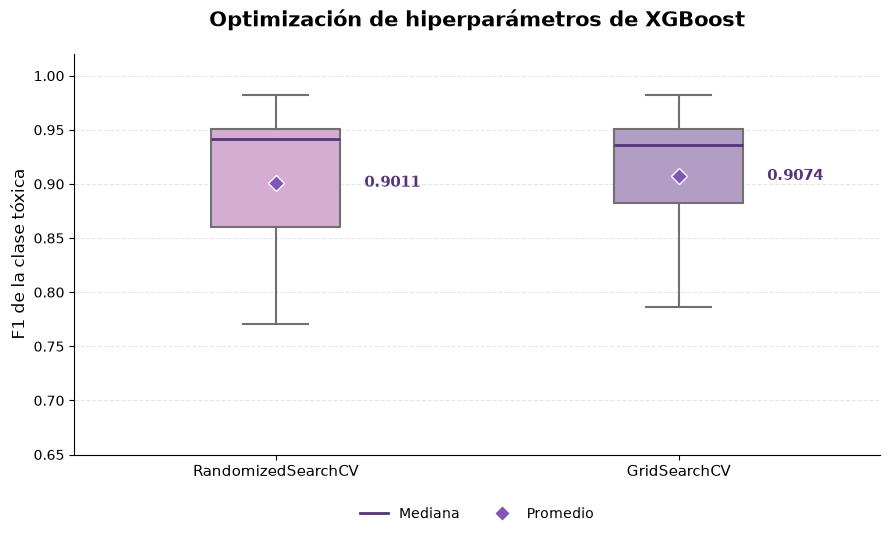

In [204]:
# Recuperar resultados de cada estrategia de optimización
datos_boxplot_xgb = {
    "RandomizedSearchCV": obtener_f1_pliegues(busqueda_xgb),
    "GridSearchCV": obtener_f1_pliegues(busqueda_xgb_refinada)
}

# Configuración de la gráfica
fig, ax = plt.subplots(figsize=(9, 5.5))

colores = ["#D5ADD3", "#B29DC5"]

posiciones = np.arange(1, len(datos_boxplot_xgb) + 1)

for posicion, (nombre, valores), color in zip(
    posiciones,
    datos_boxplot_xgb.items(),
    colores
):

    ax.boxplot(
        valores,
        positions=[posicion],
        widths=0.32,
        patch_artist=True,
        showmeans=True,
        boxprops={
            "facecolor": color,
            "edgecolor": "#707070",
            "linewidth": 1.5
        },
        medianprops={
            "color": "#563477",
            "linewidth": 2
        },
        meanprops={
            "marker": "D",
            "markerfacecolor": "#8055B3",
            "markeredgecolor": "white",
            "markersize": 8
        },
        whiskerprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        capprops={
            "color": "#707070",
            "linewidth": 1.5
        },
        flierprops={
            "marker": "o",
            "markerfacecolor": "#D5ADD3",
            "markeredgecolor": "#8055B3",
            "markersize": 5
        }
    )

    # Etiqueta del F1 promedio
    ax.text(
        posicion + 0.22,
        valores.mean(),
        f"{valores.mean():.4f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

# Configuración de ejes
ax.set_xticks(posiciones)
ax.set_xticklabels(datos_boxplot_xgb.keys(), fontsize=11)

ax.set_ylabel("F1 de la clase tóxica", fontsize=12)

ax.set_title(
    "Optimización de hiperparámetros de XGBoost",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlim(0.5, len(datos_boxplot_xgb) + 0.5)
ax.set_ylim(0.65, 1.02)
ax.set_yticks(np.arange(0.65, 1.01, 0.05))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

El refinamiento de hiperparámetros permitió mejorar el F1 promedio de XGBoost de 0.9011 a 0.9074, mientras que la desviación estándar disminuyó de 0.0767 a 0.0687.

La configuración refinada utilizó 200 árboles y profundidad máxima de 6, frente a los 300 árboles y profundidad de 5 seleccionados inicialmente. Esto muestra que una mayor cantidad de árboles no necesariamente produce mejores resultados.

Se seleccionó la configuración refinada como candidata final de XGBoost. Sin embargo, dado que las diferencias fueron pequeñas y los mismos pliegues se utilizaron para seleccionar los hiperparámetros, será necesario realizar una evaluación independiente antes de establecer conclusiones sobre su capacidad de generalización.

#### 11.4. Comparación del desempeño antes y después de la optimización

Se comparará el desempeño de los tres modelos seleccionados antes y después de la optimización de hiperparámetros, utilizando el F1 de la clase tóxica como métrica principal.

Mediante boxplots y una comparación de los resultados por pliegue, se analizará si la optimización permitió incrementar el desempeño promedio, reducir la variabilidad y mejorar los resultados en las particiones de validación más difíciles.

In [205]:
# Resultados preliminares de los tres modelos
resultados_preliminares = pd.concat(
    [
        resultados_svm,
        resultados_rf,
        resultados_xgb
    ],
    ignore_index=True
)

# Mejores configuraciones preliminares
configuraciones_preliminares = {
    "SVM": (
        "sin_duplicados",
        "oversampling",
        "Sin reducción"
    ),
    "XGBoost": (
        "original",
        "sin_balanceo",
        "Sin reducción"
    ),
    "Random Forest": (
        "original",
        "sin_balanceo",
        "Mutual Information"
    )
}

# Mejores búsquedas de hiperparámetros
busquedas_optimizadas = {
    "SVM": busqueda_svm_refinada,
    "XGBoost": busqueda_xgb_refinada,
    "Random Forest": busqueda_rf_refinada
}

registros_comparacion = []

for modelo, configuracion in configuraciones_preliminares.items():

    tratamiento, balanceo, representacion = configuracion

    # Resultados antes de la optimización
    datos_antes = resultados_preliminares.loc[
        (resultados_preliminares["Modelo"] == modelo) &
        (resultados_preliminares["Tratamiento"] == tratamiento) &
        (resultados_preliminares["Balanceo"] == balanceo) &
        (resultados_preliminares["Representación"] == representacion)
    ].sort_values("Pliegue")

    # Resultados después de la optimización
    valores_despues = obtener_f1_pliegues(
        busquedas_optimizadas[modelo]
    )

    # Verificar número de pliegues
    assert len(datos_antes) == len(valores_despues) == 5, (
        f"Número de pliegues incorrecto para {modelo}"
    )

    # Almacenar resultados preliminares
    for pliegue, f1 in zip(
        datos_antes["Pliegue"],
        datos_antes["F1"]
    ):
        registros_comparacion.append({
            "Modelo": modelo,
            "Etapa": "Antes",
            "Pliegue": pliegue,
            "F1": f1
        })

    # Almacenar resultados optimizados
    for pliegue, f1 in enumerate(
        valores_despues, start=1
    ):
        registros_comparacion.append({
            "Modelo": modelo,
            "Etapa": "Después",
            "Pliegue": pliegue,
            "F1": f1
        })

# DataFrame con resultados individuales
comparacion_opt_pliegues = pd.DataFrame(
    registros_comparacion
)

# Resumen estadístico
resumen_comparacion_opt = (
    comparacion_opt_pliegues
    .groupby(["Modelo", "Etapa"])["F1"]
    .agg(
        F1_promedio="mean",
        F1_std=lambda x: x.std(ddof=0),
        Mediana="median",
        Minimo="min",
        Maximo="max"
    )
)

print("Resumen estadístico antes y después de la optimización:")
display(resumen_comparacion_opt.round(4))

# Comparación de métricas
comparacion_mejoras_opt = (
    resumen_comparacion_opt.unstack("Etapa")
)

tabla_mejoras_opt = pd.DataFrame({
    "F1_antes":
        comparacion_mejoras_opt["F1_promedio"]["Antes"],

    "F1_despues":
        comparacion_mejoras_opt["F1_promedio"]["Después"],

    "Std_antes":
        comparacion_mejoras_opt["F1_std"]["Antes"],

    "Std_despues":
        comparacion_mejoras_opt["F1_std"]["Después"]
})

# Cambios en puntos porcentuales
tabla_mejoras_opt["Cambio_F1_pp"] = (
    tabla_mejoras_opt["F1_despues"] -
    tabla_mejoras_opt["F1_antes"]
) * 100

tabla_mejoras_opt["Cambio_std_pp"] = (
    tabla_mejoras_opt["Std_despues"] -
    tabla_mejoras_opt["Std_antes"]
) * 100

# Ordenar por desempeño optimizado
tabla_mejoras_opt = tabla_mejoras_opt.sort_values(
    "F1_despues",
    ascending=False
)

print("\nComparación del efecto de la optimización:")
display(tabla_mejoras_opt.round(4))

Resumen estadístico antes y después de la optimización:


F1_promedio  F1_std  Mediana  Minimo  Maximo
Modelo        Etapa                                                
Random Forest Antes         0.8960  0.0832   0.9162  0.7451  0.9818
              Después       0.9046  0.0840   0.9371  0.7451  0.9818
SVM           Antes         0.9056  0.0980   0.9176  0.7234  0.9943
              Después       0.9091  0.0775   0.9123  0.7755  0.9880
XGBoost       Antes         0.9056  0.0618   0.9333  0.8028  0.9820
              Después       0.9074  0.0687   0.9359  0.7862  0.9820


Comparación del efecto de la optimización:


,F1_antes,F1_despues,Std_antes,Std_despues,Cambio_F1_pp,Cambio_std_pp
Modelo,,,,,,
SVM,0.9056,0.9091,0.0980,0.0775,0.3482,-2.0448
XGBoost,0.9056,0.9074,0.0618,0.0687,0.1804,0.6895
Random Forest,0.8960,0.9046,0.0832,0.0840,0.8654,0.0792


La optimización de hiperparámetros incrementó el F1 promedio de la clase tóxica en los tres modelos. Random Forest presentó la mayor mejora (+0.87 pp), seguido de SVM (+0.35 pp) y XGBoost (+0.18 pp). SVM alcanzó el mayor F1 promedio (0.9091) y fue el único modelo que redujo su variabilidad entre pliegues, mientras que XGBoost conservó la menor desviación estándar (0.0687).

Aunque la optimización produjo mejoras, estas fueron pequeñas, lo que sugiere que las configuraciones preliminares ya ofrecían un desempeño competitivo. Estos resultados deberán contrastarse mediante la validación cruzada anidada, debido al posible sesgo asociado con la selección de hiperparámetros.

##### 11.4.2. Distribución del F1 antes y después de la optimización

Se visualizará la distribución del F1 de la clase tóxica mediante boxplots para comparar el desempeño de los modelos antes y después de la optimización. Se analizarán los cambios en el promedio, la mediana, la dispersión y los valores extremos entre los cinco pliegues de validación.

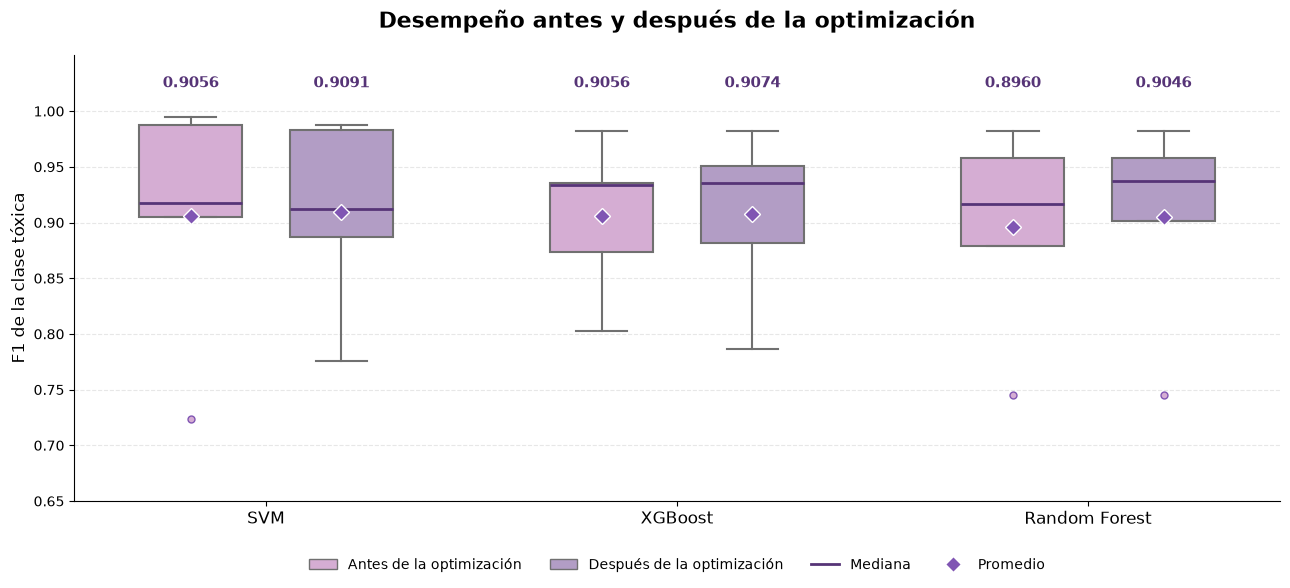

In [206]:
# Orden de los modelos
modelos = ["SVM", "XGBoost", "Random Forest"]

etapas = ["Antes", "Después"]

colores = {
    "Antes": "#D5ADD3",
    "Después": "#B29DC5"
}

# Configuración de la gráfica
fig, ax = plt.subplots(figsize=(13, 6))

posiciones = np.arange(len(modelos)) * 3

desplazamientos = {
    "Antes": -0.55,
    "Después": 0.55
}

for posicion, modelo in zip(posiciones, modelos):

    for etapa in etapas:

        valores = comparacion_opt_pliegues.loc[
            (comparacion_opt_pliegues["Modelo"] == modelo) &
            (comparacion_opt_pliegues["Etapa"] == etapa),
            "F1"
        ].to_numpy()

        x = posicion + desplazamientos[etapa]

        ax.boxplot(
            valores,
            positions=[x],
            widths=0.75,
            patch_artist=True,
            showmeans=True,
            boxprops={
                "facecolor": colores[etapa],
                "edgecolor": "#707070",
                "linewidth": 1.5
            },
            medianprops={
                "color": "#563477",
                "linewidth": 2
            },
            meanprops={
                "marker": "D",
                "markerfacecolor": "#8055B3",
                "markeredgecolor": "white",
                "markersize": 8
            },
            whiskerprops={
                "color": "#707070",
                "linewidth": 1.5
            },
            capprops={
                "color": "#707070",
                "linewidth": 1.5
            },
            flierprops={
                "marker": "o",
                "markerfacecolor": "#D5ADD3",
                "markeredgecolor": "#8055B3",
                "markersize": 5
            }
        )

        # Etiqueta del F1 promedio
        ax.text(
            x,
            1.025,
            f"{valores.mean():.4f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="#563477"
        )

# Configuración de ejes
ax.set_xticks(posiciones)
ax.set_xticklabels(modelos, fontsize=12)

ax.set_ylabel(
    "F1 de la clase tóxica",
    fontsize=12
)

ax.set_title(
    "Desempeño antes y después de la optimización",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlim(-1.4, posiciones[-1] + 1.4)
ax.set_ylim(0.65, 1.05)
ax.set_yticks(np.arange(0.65, 1.01, 0.05))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Patch(
        facecolor=colores["Antes"],
        edgecolor="#707070",
        label="Antes de la optimización"
    ),
    Patch(
        facecolor=colores["Después"],
        edgecolor="#707070",
        label="Después de la optimización"
    ),
    Line2D(
        [0], [0],
        color="#563477",
        linewidth=2,
        label="Mediana"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#8055B3",
        markeredgecolor="white",
        markersize=8,
        label="Promedio"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False,
    fontsize=10
)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

La distribución del F1 mostró que la optimización tuvo efectos distintos en cada modelo. SVM mejoró su desempeño mínimo y redujo su variabilidad entre pliegues, mientras que Random Forest presentó el mayor incremento en el promedio y una mejora en la mediana. Por su parte, XGBoost mostró cambios pequeños y conservó la menor desviación estándar.

En general, la optimización produjo mejoras moderadas, pero no eliminó las dificultades de clasificación en determinados pliegues. Además, estos resultados corresponden a los pliegues utilizados durante la selección de hiperparámetros, por lo que no garantizan una mejora en la capacidad de generalización.

##### 11.4.3. Matrices de confusión después de la optimización

Se construirán las matrices de confusión de los tres modelos optimizados a partir de las predicciones obtenidas en los cinco pliegues de validación. Se analizarán los falsos positivos y falsos negativos, así como los cambios respecto a las configuraciones preliminares, para determinar si la optimización favoreció la identificación de nanopartículas tóxicas.

In [207]:
# Mejores estimadores obtenidos mediante GridSearchCV
modelos_optimizados = {
    "SVM": busqueda_svm_refinada.best_estimator_,
    "XGBoost": busqueda_xgb_refinada.best_estimator_,
    "Random Forest": busqueda_rf_refinada.best_estimator_
}

predicciones_optimizadas = {}
matrices_optimizadas = {}
resultados_confusion_opt = []

# Conservar las mismas particiones de validación
pliegues_opt = list(cv_svm.split(X, y, groups))

for modelo, estimador in modelos_optimizados.items():

    print(f"Evaluando {modelo} optimizado...")

    # Predicciones fuera del conjunto de entrenamiento
    y_pred = cross_val_predict(
        clone(estimador),
        X,
        y,
        cv=pliegues_opt,
        method="predict",
        n_jobs=1
    )

    predicciones_optimizadas[modelo] = y_pred

    # Matriz de confusión
    matriz = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    matrices_optimizadas[modelo] = matriz

    tn, fp, fn, tp = matriz.ravel()

    resultados_confusion_opt.append({
        "Modelo": modelo,
        "Verdaderos negativos": tn,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
        "Verdaderos positivos": tp,
        "Errores totales": fp + fn,
        "Precisión": tp / (tp + fp) if tp + fp else 0,
        "Sensibilidad": tp / (tp + fn) if tp + fn else 0,
        "Especificidad": tn / (tn + fp) if tn + fp else 0,
        "F1 global": (
            2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else 0
        )
    })

# Resumen de resultados
tabla_confusion_opt = pd.DataFrame(
    resultados_confusion_opt
)

display(tabla_confusion_opt.round(4))

Evaluando SVM optimizado...
Evaluando XGBoost optimizado...
Evaluando Random Forest optimizado...


,Modelo,Verdaderos negativos,Falsos positivos,Falsos negativos,Verdaderos positivos,Errores totales,Precisión,Sensibilidad,Especificidad,F1 global
0,SVM,357,48,39,437,87,0.9010,0.9181,0.8815,0.9095
1,XGBoost,349,56,35,441,91,0.8873,0.9265,0.8617,0.9065
2,Random Forest,349,56,35,441,91,0.8873,0.9265,0.8617,0.9065


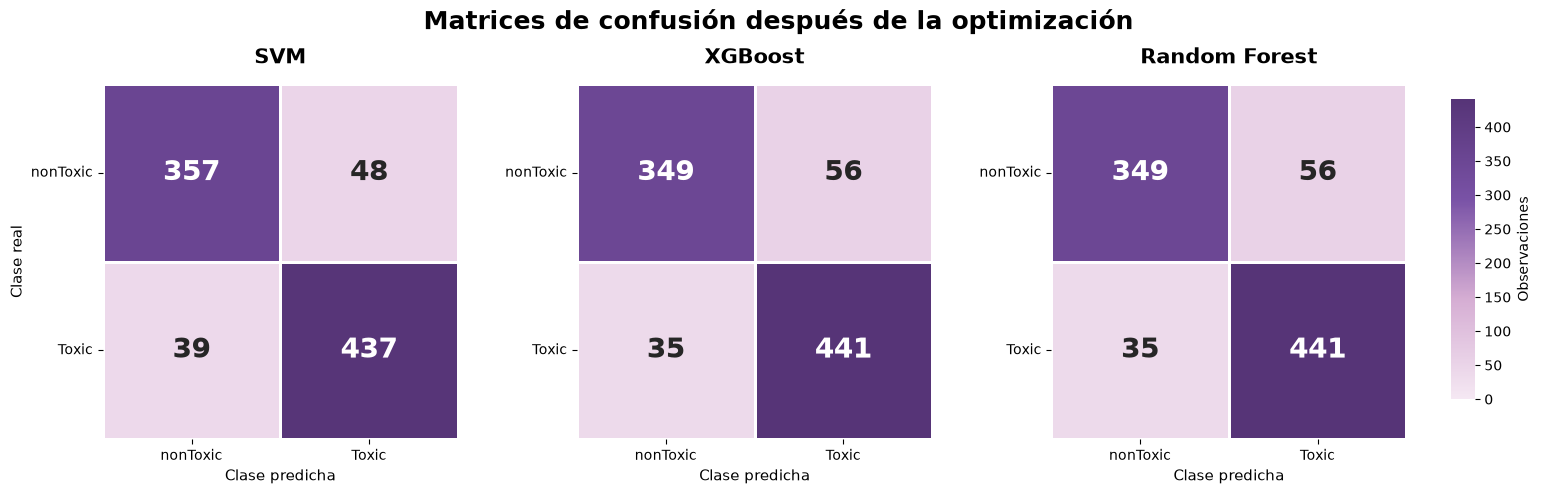

In [208]:
# Paleta rosa-morado
cmap_confusion = LinearSegmentedColormap.from_list(
    "rosa_morado",
    ["#F5E8F3", "#D5ADD3", "#7952A6", "#563477"]
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

# Escala común para las tres matrices
vmax = max(
    441,
    max(matriz.max()
        for matriz in matrices_optimizadas.values())
)

# Eje para la barra de color compartida
cbar_ax = fig.add_axes(
    [0.92, 0.20, 0.015, 0.60]
)

for i, (modelo, matriz) in enumerate(
    matrices_optimizadas.items()
):

    ax = axes[i]

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap=cmap_confusion,
        vmin=0,
        vmax=vmax,
        square=True,
        linewidths=2,
        linecolor="white",
        xticklabels=["nonToxic", "Toxic"],
        yticklabels=["nonToxic", "Toxic"],
        annot_kws={
            "fontsize": 20,
            "fontweight": "bold"
        },
        cbar=(i == 2),
        cbar_ax=cbar_ax if i == 2 else None,
        cbar_kws={"label": "Observaciones"},
        ax=ax
    )

    ax.set_title(
        modelo,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Clase predicha",
        fontsize=11
    )

    ax.set_ylabel(
        "Clase real" if i == 0 else "",
        fontsize=11
    )

    ax.tick_params(axis="both", rotation=0)

fig.suptitle(
    "Matrices de confusión después de la optimización",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.07,
    right=0.90,
    bottom=0.12,
    top=0.83,
    wspace=0.25
)

plt.show()

La optimización modificó el comportamiento de clasificación de los tres modelos. SVM redujo los falsos negativos de 45 a 39, aunque incrementó los falsos positivos. XGBoost mejoró su sensibilidad sin afectar su especificidad, mientras que Random Forest presentó la mayor reducción de errores totales, al disminuir sus falsos positivos de 68 a 56.

Desde la perspectiva de la predicción de toxicidad, resultó favorable que ninguno de los modelos incrementara sus falsos negativos, debido a las posibles implicaciones de clasificar una nanopartícula tóxica como no tóxica.

Finalmente, XGBoost y Random Forest obtuvieron matrices de confusión idénticas después de la optimización. Sin embargo, esto no implica necesariamente que ambos modelos hayan cometido errores sobre las mismas observaciones.

##### 11.4.4. Coincidencia de errores después de la optimización

Se analizará la coincidencia de errores entre los modelos optimizados mediante el número de observaciones clasificadas incorrectamente en común y el índice de Jaccard. Asimismo, se identificará cuántas observaciones fueron clasificadas incorrectamente por uno, dos o los tres modelos, con el propósito de determinar si la optimización modificó los patrones de error identificados previamente.

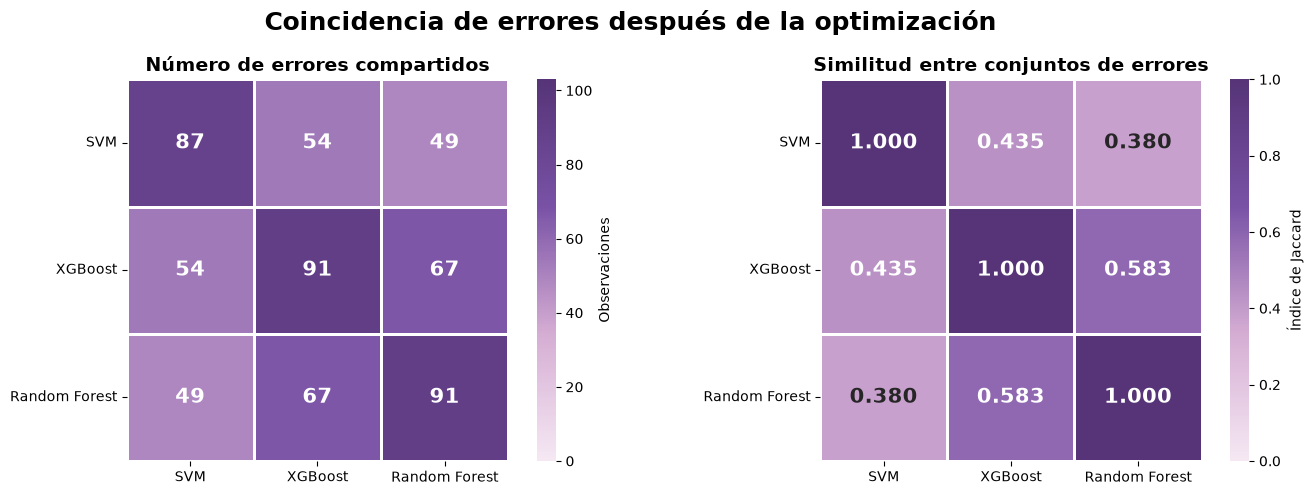

In [209]:
# Orden de los modelos
modelos = ["SVM", "XGBoost", "Random Forest"]

# Identificar observaciones clasificadas incorrectamente
errores_opt = {
    modelo: set(
        np.flatnonzero(
            np.asarray(predicciones_optimizadas[modelo])
            != np.asarray(y)
        )
    )
    for modelo in modelos
}

# Matrices de coincidencia
matriz_errores_opt = pd.DataFrame(
    0, index=modelos, columns=modelos
)

matriz_jaccard_opt = pd.DataFrame(
    0.0, index=modelos, columns=modelos
)

for modelo_a in modelos:
    for modelo_b in modelos:

        A = errores_opt[modelo_a]
        B = errores_opt[modelo_b]

        interseccion = len(A & B)
        union = len(A | B)

        matriz_errores_opt.loc[
            modelo_a, modelo_b
        ] = interseccion

        matriz_jaccard_opt.loc[
            modelo_a, modelo_b
        ] = interseccion / union if union else 1.0

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    matriz_errores_opt,
    annot=True,
    fmt="d",
    cmap=cmap_confusion,
    vmin=0,
    vmax=103,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"fontsize": 15, "fontweight": "bold"},
    cbar_kws={"label": "Observaciones"},
    ax=axes[0]
)

axes[0].set_title(
    "Número de errores compartidos",
    fontsize=14,
    fontweight="bold"
)

sns.heatmap(
    matriz_jaccard_opt,
    annot=True,
    fmt=".3f",
    cmap=cmap_confusion,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"fontsize": 15, "fontweight": "bold"},
    cbar_kws={"label": "Índice de Jaccard"},
    ax=axes[1]
)

axes[1].set_title(
    "Similitud entre conjuntos de errores",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.tick_params(axis="both", rotation=0)

fig.suptitle(
    "Coincidencia de errores después de la optimización",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

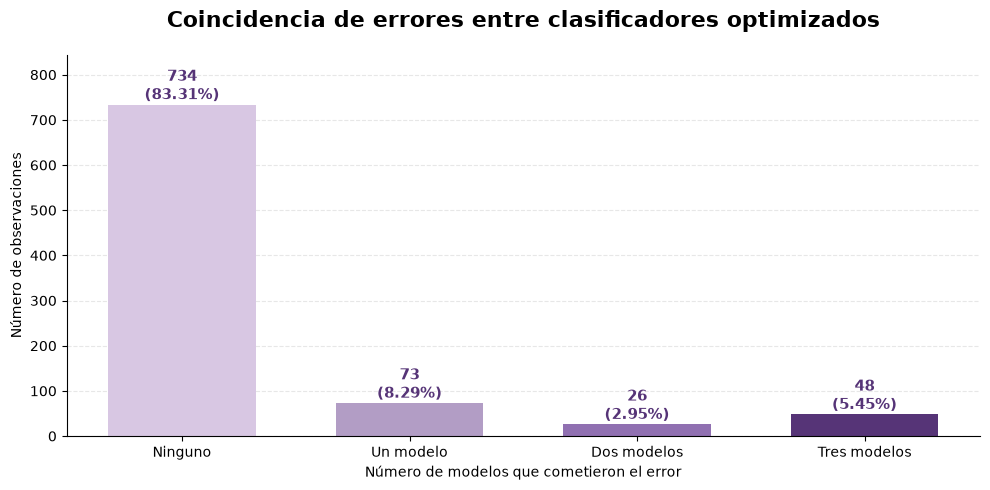

In [210]:
# Identificar errores por observación y modelo
errores_por_observacion_opt = pd.DataFrame({
    modelo: (
        np.asarray(predicciones_optimizadas[modelo])
        != np.asarray(y)
    ).astype(int)
    for modelo in modelos
})

# Número de modelos que fallaron en cada observación
numero_errores_opt = errores_por_observacion_opt.sum(axis=1)

conteo_errores_opt = (
    numero_errores_opt.value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
)

porcentajes_opt = conteo_errores_opt / len(y) * 100

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))

colores = [
    "#D8C7E3",
    "#B29DC5",
    "#9070B1",
    "#563477"
]

barras = ax.bar(
    ["Ninguno", "Un modelo", "Dos modelos", "Tres modelos"],
    conteo_errores_opt.values,
    color=colores,
    width=0.65
)

for barra, cantidad, porcentaje in zip(
    barras,
    conteo_errores_opt.values,
    porcentajes_opt.values
):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 12,
        f"{cantidad}\n({porcentaje:.2f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#563477"
    )

ax.set_title(
    "Coincidencia de errores entre clasificadores optimizados",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Número de modelos que cometieron el error")
ax.set_ylabel("Número de observaciones")

ax.set_ylim(0, conteo_errores_opt.max() * 1.15)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [211]:
# Resultados obtenidos antes de la optimización
conteo_errores_antes = np.array([726, 77, 30, 48])

comparacion_coincidencia = pd.DataFrame({
    "Modelos que cometieron el error": [
        "Ninguno",
        "Un modelo",
        "Dos modelos",
        "Tres modelos"
    ],
    "Antes": conteo_errores_antes,
    "Después": conteo_errores_opt.values
})

comparacion_coincidencia["Cambio"] = (
    comparacion_coincidencia["Después"]
    - comparacion_coincidencia["Antes"]
)

comparacion_coincidencia["Antes (%)"] = (
    comparacion_coincidencia["Antes"] / len(y) * 100
)

comparacion_coincidencia["Después (%)"] = (
    comparacion_coincidencia["Después"] / len(y) * 100
)

display(comparacion_coincidencia.round(2))

# Comparación del índice de Jaccard
pares_modelos = [
    ("SVM", "XGBoost"),
    ("SVM", "Random Forest"),
    ("XGBoost", "Random Forest")
]

jaccard_antes = [
    50 / (84 + 94 - 50),
    51 / (84 + 103 - 51),
    73 / (94 + 103 - 73)
]

comparacion_jaccard = pd.DataFrame({
    "Modelos": [
        f"{a} - {b}" for a, b in pares_modelos
    ],
    "Jaccard antes": jaccard_antes,
    "Jaccard después": [
        matriz_jaccard_opt.loc[a, b]
        for a, b in pares_modelos
    ]
})

comparacion_jaccard["Cambio"] = (
    comparacion_jaccard["Jaccard después"]
    - comparacion_jaccard["Jaccard antes"]
)

display(comparacion_jaccard.round(4))

,Modelos que cometieron el error,Antes,Después,Cambio,Antes (%),Después (%)
0,Ninguno,726,734,8,82.41,83.31
1,Un modelo,77,73,-4,8.74,8.29
2,Dos modelos,30,26,-4,3.41,2.95
3,Tres modelos,48,48,0,5.45,5.45


,Modelos,Jaccard antes,Jaccard después,Cambio
0,SVM - XGBoost,0.3906,0.4355,0.0449
1,SVM - Random Forest,0.3750,0.3798,0.0048
2,XGBoost - Random Forest,0.5887,0.5826,-0.0061


La optimización incrementó del 82.41% al 83.31% la proporción de observaciones clasificadas correctamente por los tres modelos. Sin embargo, el número de observaciones clasificadas incorrectamente por todos permaneció en 48.

XGBoost y Random Forest conservaron la mayor similitud entre sus patrones de error (Jaccard = 0.583), aunque sus matrices de confusión idénticas no implicaron que cometieran exactamente los mismos errores. Por su parte, SVM mantuvo un comportamiento más diferenciado.

En general, la optimización produjo mejoras marginales sin modificar sustancialmente los patrones de error entre clasificadores, lo que sugiere que el ajuste de hiperparámetros no fue suficiente para resolver todas las dificultades de clasificación. Esta coincidencia de errores entre los tres clasificadores, a pesar de sus diferentes mecanismos de aprendizaje, sugiere que parte de las dificultades de clasificación podría estar relacionada con limitaciones inherentes al conjunto de datos y no exclusivamente con los modelos. En particular, la presencia de etiquetas contradictorias, registros duplicados y posibles variables experimentales no consideradas podría limitar la capacidad predictiva. Sin embargo, es necesario analizar las observaciones mal clasificadas en común para respaldar esta hipótesis.

#### 11.5. Análisis de las observaciones incorrectamente clasificadas en común

Debido a la coincidencia de errores entre los tres clasificadores, se analizarán las observaciones incorrectamente clasificadas en común antes y después de la optimización. Se evaluará la persistencia de estos errores y su posible relación con la presencia de registros duplicados, etiquetas contradictorias, el tipo de nanopartícula y la clase de toxicidad. El objetivo será identificar si las dificultades de clasificación podrían estar asociadas con limitaciones del conjunto de datos y no exclusivamente con los modelos.

In [212]:
modelos = ["SVM", "XGBoost", "Random Forest"]

# Errores compartidos antes de la optimización
comunes_antes = set(
    errores_preliminares.loc[
        errores_preliminares["Número de modelos incorrectos"] == 3,
        "Observación"
    ]
)

# Errores compartidos después de la optimización
comunes_despues = set.intersection(
    *(errores_opt[modelo] for modelo in modelos)
)

# Comparación de conjuntos
errores_persistentes = comunes_antes & comunes_despues
errores_corregidos = comunes_antes - comunes_despues
errores_nuevos = comunes_despues - comunes_antes

# Índice de Jaccard
jaccard_persistencia = (
    len(errores_persistentes)
    / len(comunes_antes | comunes_despues)
)

# Porcentaje de persistencia
porcentaje_persistencia = (
    100 * len(errores_persistentes) / len(comunes_antes)
)

# Resumen de resultados
resumen_persistencia = pd.DataFrame({
    "Categoría": [
        "Errores compartidos antes",
        "Errores compartidos después",
        "Errores persistentes",
        "Errores compartidos corregidos",
        "Nuevos errores compartidos"
    ],
    "Observaciones": [
        len(comunes_antes),
        len(comunes_despues),
        len(errores_persistentes),
        len(errores_corregidos),
        len(errores_nuevos)
    ]
})

display(resumen_persistencia)

print(f"Índice de Jaccard: {jaccard_persistencia:.4f}")
print(f"Persistencia de errores: {porcentaje_persistencia:.2f}%")

,Categoría,Observaciones
0,Errores compartidos antes,48
1,Errores compartidos después,48
2,Errores persistentes,46
3,Errores compartidos corregidos,2
4,Nuevos errores compartidos,2


Índice de Jaccard: 0.9200
Persistencia de errores: 95.83%


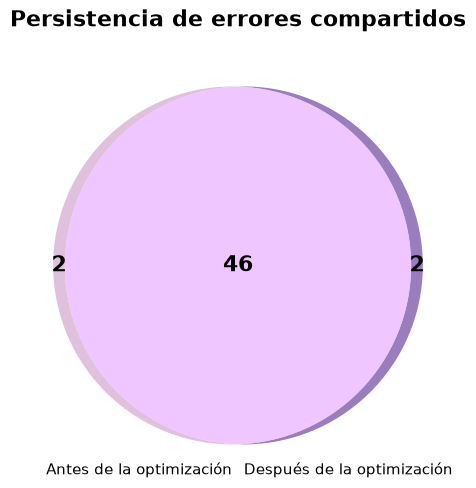

In [213]:
fig, ax = plt.subplots(figsize=(8, 5))

venn = venn2(
    subsets=(
        len(errores_corregidos),
        len(errores_nuevos),
        len(errores_persistentes)
    ),
    set_labels=(
        "Antes de la optimización",
        "Después de la optimización"
    ),
    set_colors=("#D5ADD3", "#7952A6"),
    alpha=0.75,
    ax=ax
)

for etiqueta in venn.subset_labels:
    if etiqueta is not None:
        etiqueta.set_fontsize(16)
        etiqueta.set_fontweight("bold")

for etiqueta in venn.set_labels:
    if etiqueta is not None:
        etiqueta.set_fontsize(11)

ax.set_title(
    "Persistencia de errores compartidos",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

La optimización de hiperparámetros apenas modificó el conjunto de observaciones clasificadas incorrectamente por los tres modelos. De los 48 errores compartidos inicialmente, 46 persistieron después de la optimización, lo que representó una persistencia del 95.83% y un índice de Jaccard de 0.92.

La elevada coincidencia de errores entre modelos con distintos mecanismos de aprendizaje sugiere que las dificultades de clasificación podrían estar relacionadas con las características del conjunto de datos, como la presencia de etiquetas contradictorias, el solapamiento entre clases o la ausencia de variables predictoras relevantes, y no exclusivamente con la configuración de los modelos. Sin embargo, estos resultados no permiten confirmar directamente dichas causas.

Por esto,  analizarán las observaciones clasificadas incorrectamente por los tres modelos antes y después de la optimización. Se identificarán sus características fisicoquímicas, tipo de nanopartícula, clase real, pliegue de validación y pertenencia a grupos de registros duplicados o con etiquetas contradictorias. El objetivo será identificar patrones que permitan explorar si los errores persistentes están asociados con las características o limitaciones del conjunto de datos.

In [214]:
# Recuperar el conjunto original de observaciones
datos_analisis = X.copy().reset_index(drop=True)
datos_analisis["Clase"] = np.asarray(y)

# Identificar registros duplicados (predictores y etiqueta)
datos_analisis["Duplicado"] = datos_analisis.duplicated(
    subset=columnas_predictoras + ["Clase"],
    keep=False
)

# Identificar combinaciones con etiquetas contradictorias
datos_analisis["Contradicción"] = (
    datos_analisis
    .groupby(columnas_predictoras, dropna=False)["Clase"]
    .transform("nunique")
    .gt(1)
)

# Recuperar los pliegues de validación
pliegues_observaciones = (
    predicciones_preliminares[
        ["Observación", "Pliegue"]
    ]
    .drop_duplicates()
    .set_index("Observación")["Pliegue"]
)

datos_analisis["Pliegue"] = (
    datos_analisis.index.map(pliegues_observaciones)
)

# Identificar los errores persistentes
datos_analisis["Error persistente"] = (
    datos_analisis.index.isin(errores_persistentes)
)

# Extraer las observaciones de interés
datos_errores_persistentes = datos_analisis.loc[
    datos_analisis["Error persistente"]
].copy()

# Identificar el tipo de error
datos_errores_persistentes["Tipo de error"] = np.where(
    datos_errores_persistentes["Clase"] == 1,
    "Falso negativo",
    "Falso positivo"
)

print(
    "Observaciones con errores persistentes:",
    len(datos_errores_persistentes)
)

display(datos_errores_persistentes)

Observaciones con errores persistentes: 46


,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,NPs,Clase,Duplicado,Contradicción,Pliegue,Error persistente,Tipo de error
32,46.3,239.0,42.8,24.10,-5.17,12,10.0,1.90,1,CuO,0,False,False,1,True,Falso positivo
274,115.0,500.0,-9.0,14.50,-3.89,24,30.0,1.65,1,ZnO,0,False,True,5,True,Falso positivo
290,60.0,329.0,-9.3,7.34,-3.89,24,20.0,1.65,1,ZnO,0,False,False,3,True,Falso positivo
309,100.0,273.4,-11.7,20.00,-3.89,48,25.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo
310,100.0,273.4,-11.7,20.00,-3.89,48,30.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo
311,100.0,273.4,-11.7,20.00,-3.89,48,35.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo
312,100.0,273.4,-11.7,20.00,-3.89,48,40.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo
313,100.0,273.4,-11.7,20.00,-3.89,48,80.0,1.65,1,ZnO,0,False,False,4,True,Falso positivo
318,100.0,273.4,-11.7,20.00,-3.89,24,25.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo
319,100.0,273.4,-11.7,20.00,-3.89,24,30.0,1.65,1,ZnO,0,False,True,4,True,Falso positivo


In [215]:
resumen_persistentes = pd.DataFrame({
    "Característica": [
        "Registros duplicados",
        "Registros con contradicciones",
        "Falsos positivos",
        "Falsos negativos"
    ],
    "Observaciones": [
        datos_errores_persistentes["Duplicado"].sum(),
        datos_errores_persistentes["Contradicción"].sum(),
        (datos_errores_persistentes["Tipo de error"]
         == "Falso positivo").sum(),
        (datos_errores_persistentes["Tipo de error"]
         == "Falso negativo").sum()
    ]
})

resumen_persistentes["Porcentaje (%)"] = (
    resumen_persistentes["Observaciones"]
    / len(datos_errores_persistentes) * 100
).round(2)

display(resumen_persistentes)

,Característica,Observaciones,Porcentaje (%)
0,Registros duplicados,29,63.04
1,Registros con contradicciones,11,23.91
2,Falsos positivos,19,41.30
3,Falsos negativos,27,58.70


In [216]:
resumen_np_persistentes = (
    datos_analisis.groupby("NPs")
    .agg(
        Observaciones=("Error persistente", "size"),
        Errores_persistentes=("Error persistente", "sum")
    )
)

resumen_np_persistentes["Tasa de error persistente (%)"] = (
    resumen_np_persistentes["Errores_persistentes"]
    / resumen_np_persistentes["Observaciones"] * 100
).round(2)

display(resumen_np_persistentes)

,Observaciones,Errores_persistentes,Tasa de error persistente (%)
NPs,,,
Al2O3,18,0,0.00
CuO,51,1,1.96
Fe2O3,18,0,0.00
TiO2,200,0,0.00
ZnO,594,45,7.58


In [217]:
resumen_pliegues_persistentes = (
    datos_analisis.groupby("Pliegue")
    .agg(
        Observaciones=("Error persistente", "size"),
        Errores_persistentes=("Error persistente", "sum")
    )
)

resumen_pliegues_persistentes["Tasa de error persistente (%)"] = (
    resumen_pliegues_persistentes["Errores_persistentes"]
    / resumen_pliegues_persistentes["Observaciones"] * 100
).round(2)

display(resumen_pliegues_persistentes)

,Observaciones,Errores_persistentes,Tasa de error persistente (%)
Pliegue,,,
1,157,1,0.64
2,150,28,18.67
3,152,2,1.32
4,268,14,5.22
5,154,1,0.65


Los errores persistentes se concentraron principalmente en las nanopartículas de ZnO (97.83%) y en los pliegues 2 y 4 (91.30%). Asimismo, el 58.70% correspondió a falsos negativos, un resultado relevante debido al riesgo de clasificar nanopartículas tóxicas como no tóxicas.

Mientras que los registros duplicados no estuvieron sobrerrepresentados entre los errores persistentes, la proporción de registros con etiquetas contradictorias fue considerablemente mayor que en el dataset original (23.91% frente a 7.26%).

Estos resultados sugirieron que la persistencia de los errores podría estar asociada con inconsistencias en las etiquetas y con las características particulares de determinados grupos experimentales, más que exclusivamente con la configuración de los modelos. Sin embargo, no fue posible establecer una relación causal.

Debido a la concentración de errores persistentes y etiquetas contradictorias en las nanopartículas de ZnO, se analizará específicamente este material. Se comparará la tasa de errores persistentes entre las observaciones con y sin contradicciones, con el propósito de reducir el efecto de confusión asociado al tipo de nanopartícula e identificar una posible relación entre las inconsistencias en las etiquetas y las dificultades de clasificación.

In [218]:
# Seleccionar las observaciones de ZnO
datos_zno = datos_analisis.loc[
    datos_analisis["NPs"] == "ZnO"
].copy()

# Comparar registros con y sin contradicciones
resumen_zno = (
    datos_zno.groupby("Contradicción")
    .agg(
        Observaciones=("Error persistente", "size"),
        Errores_persistentes=("Error persistente", "sum")
    )
    .reindex([False, True], fill_value=0)
)

resumen_zno["Observaciones_correctas_o_no_persistentes"] = (
    resumen_zno["Observaciones"]
    - resumen_zno["Errores_persistentes"]
)

resumen_zno["Tasa de error persistente (%)"] = (
    resumen_zno["Errores_persistentes"]
    / resumen_zno["Observaciones"] * 100
)

resumen_zno.index = [
    "Sin contradicciones",
    "Con contradicciones"
]

display(resumen_zno.round(2))

# Comparar las tasas de error
tasa_sin = resumen_zno.loc[
    "Sin contradicciones",
    "Tasa de error persistente (%)"
]

tasa_con = resumen_zno.loc[
    "Con contradicciones",
    "Tasa de error persistente (%)"
]

diferencia = tasa_con - tasa_sin
razon_tasas = tasa_con / tasa_sin if tasa_sin > 0 else np.nan

print(f"Diferencia: {diferencia:+.2f} puntos porcentuales")
print(f"Razón de tasas: {razon_tasas:.2f}")

,Observaciones,Errores_persistentes,Observaciones_correctas_o_no_persistentes,Tasa de error persistente (%)
Sin contradicciones,530,34,496,6.42
Con contradicciones,64,11,53,17.19


Diferencia: +10.77 puntos porcentuales
Razón de tasas: 2.68


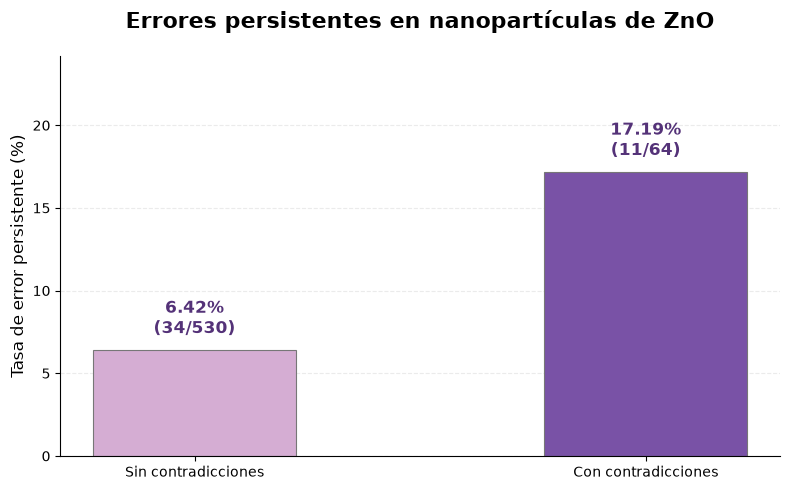

In [219]:
fig, ax = plt.subplots(figsize=(8, 5))

colores = ["#D5ADD3", "#7952A6"]

barras = ax.bar(
    resumen_zno.index,
    resumen_zno["Tasa de error persistente (%)"],
    color=colores,
    width=0.45,
    edgecolor="#777777",
    linewidth=0.8
)

for barra, (_, fila) in zip(
    barras, resumen_zno.iterrows()
):
    tasa = fila["Tasa de error persistente (%)"]
    errores = int(fila["Errores_persistentes"])
    total = int(fila["Observaciones"])

    ax.annotate(
        f"{tasa:.2f}%\n({errores}/{total})",
        xy=(
            barra.get_x() + barra.get_width() / 2,
            tasa
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#543278"
    )

ax.set_title(
    "Errores persistentes en nanopartículas de ZnO",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel(
    "Tasa de error persistente (%)",
    fontsize=12
)

ax.set_ylim(
    0,
    max(tasa_sin, tasa_con) * 1.35 + 1
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Al analizar exclusivamente las nanopartículas de ZnO, se observó que la tasa de errores persistentes fue del 17.19 % en los registros con etiquetas contradictorias, frente al 6.42% en aquellos sin contradicciones. Esto representó una diferencia de 10.77 puntos porcentuales y una tasa de error 2.68 veces mayor en presencia de contradicciones. Estos resultados reforzaron la hipótesis de que las inconsistencias del conjunto de datos podrían estar asociadas con las dificultades de clasificación, independientemente de la arquitectura del modelo. Sin embargo, al tratarse de un análisis descriptivo, no fue posible establecer una relación causal.

La optimización de hiperparámetros produjo mejoras marginales en el desempeño de los modelos, pero no resolvió la mayoría de los errores compartidos. El 95.83% de estos errores persistió después de la optimización y se concentró principalmente en las nanopartículas de ZnO y en determinados pliegues de validación.

Asimismo, se identificó una mayor tasa de errores persistentes en las observaciones con etiquetas contradictorias. Esto sugirió que mejorar la calidad de los datos e incorporar variables que permitan distinguir las condiciones experimentales podría ser más relevante que continuar incrementando la complejidad de los modelos.

### 12. Evaluación comparativa de los modelos optimizados

Se realizará una evaluación comparativa de SVM, Random Forest y XGBoost para estimar su capacidad de generalización después de la optimización de hiperparámetros.

Debido a que los resultados anteriores se obtuvieron utilizando los mismos pliegues empleados para seleccionar los hiperparámetros, se utilizará validación cruzada anidada estratificada por grupos. La validación cruzada anidada permite separar la selección de hiperparámetros de la evaluación del desempeño, reduciendo el sesgo asociado con utilizar las mismas particiones para ambos propósitos (Varma & Simon, 2006).

Se utilizará el F1 de la clase tóxica como métrica principal y se calcularán métricas adicionales para comparar el comportamiento de los clasificadores.

#### 12.1. Preparación de la evaluación comparativa

Se definirán cinco pliegues externos para evaluar los modelos y tres pliegues internos para seleccionar sus hiperparámetros. En ambos niveles se respetará la separación por grupos para evitar que observaciones relacionadas aparezcan simultáneamente en entrenamiento y validación.

In [228]:
# Validación externa: evaluación del desempeño
cv_externo = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Validación interna: selección de hiperparámetros
cv_interno = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=21
)

# Crear particiones externas
pliegues_externos = list(
    cv_externo.split(X, y, groups)
)

# Comprobar que no exista superposición de grupos
resumen_pliegues = []

grupos_array = np.asarray(groups)
y_array = np.asarray(y)

for i, (idx_train, idx_test) in enumerate(
    pliegues_externos, start=1
):
    grupos_train = set(grupos_array[idx_train])
    grupos_test = set(grupos_array[idx_test])

    interseccion = grupos_train.intersection(
        grupos_test
    )

    resumen_pliegues.append({
        "Pliegue": i,
        "Entrenamiento": len(idx_train),
        "Evaluación": len(idx_test),
        "Grupos train": len(grupos_train),
        "Grupos test": len(grupos_test),
        "Grupos compartidos": len(interseccion),
        "% tóxicos test": round(
            100 * y_array[idx_test].mean(), 2
        )
    })

tabla_pliegues_externos = pd.DataFrame(
    resumen_pliegues
)

display(tabla_pliegues_externos)

assert (
    tabla_pliegues_externos["Grupos compartidos"] == 0
).all(), "Se detectó superposición de grupos."

print("\nValidación externa preparada correctamente.")

,Pliegue,Entrenamiento,Evaluación,Grupos train,Grupos test,Grupos compartidos,% tóxicos test
0,1,724,157,34,8,0,51.59
1,2,731,150,35,7,0,56.00
2,3,729,152,33,9,0,53.95
3,4,613,268,32,10,0,52.99
4,5,727,154,34,8,0,56.49



Validación externa preparada correctamente.


La validación externa se dividió en cinco pliegues estratificados por grupos. Se comprobó que no existió superposición de grupos entre entrenamiento y evaluación en ninguno de ellos, evitando que observaciones relacionadas aparecieran en ambas particiones.

#### 12.2. Validación cruzada anidada de los modelos optimizados

Se evaluarán SVM, Random Forest y XGBoost mediante validación cruzada anidada, utilizando cinco pliegues externos para evaluar el desempeño y tres internos para seleccionar los hiperparámetros. Cada modelo conservará su mejor configuración preliminar de tratamiento de datos, balanceo y representación de características.

Además de las métricas de desempeño y los hiperparámetros seleccionados, se almacenarán las predicciones individuales de los conjuntos de evaluación externos para analizar los cambios en los patrones de error después de la optimización.

In [221]:
# Configuración de modelos y búsquedas internas
configuracion_modelos = {
    "SVM": {
        "estimador": estimador_svm,
        "parametros": {
            "pipeline__modelo__kernel": ["rbf"],
            "pipeline__modelo__C": [0.5, 1, 2],
            "pipeline__modelo__gamma": ["scale", 0.1, 0.15]
        },
        "tipo_busqueda": "grid"
    },

    "Random Forest": {
        "estimador": pipeline_rf,
        "parametros": {
            "modelo__n_estimators": [75, 100, 150],
            "modelo__max_depth": [8, 10, 12, 15],
            "modelo__min_samples_split": [3, 5, 7],
            "modelo__min_samples_leaf": [1, 2],
            "modelo__max_features": ["sqrt"]
        },
        "tipo_busqueda": "random",
        "n_iter": 15
    },

    "XGBoost": {
        "estimador": pipeline_xgb,
        "parametros": {
            "modelo__n_estimators": [200, 300, 400],
            "modelo__max_depth": [4, 5, 6],
            "modelo__learning_rate": [0.03, 0.05, 0.1],
            "modelo__subsample": [0.8, 0.85, 1.0],
            "modelo__colsample_bytree": [0.7, 0.85, 1.0],
            "modelo__min_child_weight": [1, 3],
            "modelo__reg_lambda": [0.1, 1, 5]
        },
        "tipo_busqueda": "random",
        "n_iter": 15
    }
}

print("Modelos configurados:")
for nombre in configuracion_modelos:
    print("-", nombre)

Modelos configurados:
- SVM
- Random Forest
- XGBoost


In [229]:
def evaluar_modelos_anidados(
    X, y, groups, configuraciones,
    pliegues_externos, cv_interno
):
    resultados = []
    hiperparametros = []
    predicciones = []

    grupos_array = np.asarray(groups)

    # Asegurar indexación por posición
    X = X.reset_index(drop=True)
    y = pd.Series(np.asarray(y)).reset_index(drop=True)

    for nombre, config in configuraciones.items():

        print(f"\nEvaluando {nombre}...")

        for i, (idx_train, idx_test) in enumerate(
            pliegues_externos, start=1
        ):
            X_train = X.iloc[idx_train]
            X_test = X.iloc[idx_test]
            y_train = y.iloc[idx_train]
            y_test = y.iloc[idx_test]

            grupos_train = grupos_array[idx_train]

            # Crear pliegues internos
            pliegues_internos = list(
                cv_interno.split(
                    X_train, y_train, grupos_train
                )
            )

            argumentos = dict(
                estimator=clone(config["estimador"]),
                param_grid=config["parametros"],
                scoring=f1_toxic,
                cv=pliegues_internos,
                refit=True,
                n_jobs=-1,
                error_score="raise"
            )

            # Seleccionar método de búsqueda
            if config["tipo_busqueda"] == "grid":

                busqueda = GridSearchCV(**argumentos)

            else:

                argumentos["param_distributions"] = (
                    argumentos.pop("param_grid")
                )

                argumentos["n_iter"] = config["n_iter"]
                argumentos["random_state"] = 42

                busqueda = RandomizedSearchCV(
                    **argumentos
                )

            # Optimización interna
            busqueda.fit(X_train, y_train)

            # Evaluación externa
            y_pred = busqueda.predict(X_test)

            tn, fp, fn, tp = confusion_matrix(
                y_test, y_pred, labels=[0, 1]
            ).ravel()

            # Guardar métricas
            resultados.append({
                "Modelo": nombre,
                "Pliegue": i,
                "F1": f1_score(
                    y_test, y_pred, zero_division=0
                ),
                "Precisión": precision_score(
                    y_test, y_pred, zero_division=0
                ),
                "Sensibilidad": recall_score(
                    y_test, y_pred, zero_division=0
                ),
                "Especificidad": (
                    tn / (tn + fp)
                    if (tn + fp) > 0 else np.nan
                )
            })

            # Guardar hiperparámetros
            hiperparametros.append({
                "Modelo": nombre,
                "Pliegue": i,
                "Mejores parámetros": busqueda.best_params_,
                "F1 interno": busqueda.best_score_
            })

            # Guardar predicciones individuales
            predicciones.append(
                pd.DataFrame({
                    "Modelo": nombre,
                    "Observación": idx_test,
                    "Pliegue": i,
                    "NPs": X_test["NPs"].to_numpy(),
                    "Real": y_test.to_numpy(),
                    "Predicción": y_pred,
                    "Error": y_test.to_numpy() != y_pred
                })
            )

            print(
                f"  Pliegue {i}/5 | "
                f"F1 externo: {resultados[-1]['F1']:.4f}"
            )

    return (
        pd.DataFrame(resultados),
        pd.DataFrame(hiperparametros),
        pd.concat(predicciones, ignore_index=True)
    )


# Ejecutar evaluación anidada
(
    resultados_anidados,
    parametros_anidados,
    predicciones_anidadas
) = evaluar_modelos_anidados(
    X=X,
    y=y,
    groups=groups,
    configuraciones=configuracion_modelos,
    pliegues_externos=pliegues_externos,
    cv_interno=cv_interno
)

display(resultados_anidados.round(4))

print(
    "\nPredicciones individuales guardadas:",
    len(predicciones_anidadas)
)


Evaluando SVM...
  Pliegue 1/5 | F1 externo: 0.8727
  Pliegue 2/5 | F1 externo: 0.6716
  Pliegue 3/5 | F1 externo: 0.9560
  Pliegue 4/5 | F1 externo: 0.8405
  Pliegue 5/5 | F1 externo: 0.9943

Evaluando Random Forest...
  Pliegue 1/5 | F1 externo: 0.9818
  Pliegue 2/5 | F1 externo: 0.7451
  Pliegue 3/5 | F1 externo: 0.9576
  Pliegue 4/5 | F1 externo: 0.8580
  Pliegue 5/5 | F1 externo: 0.9162

Evaluando XGBoost...
  Pliegue 1/5 | F1 externo: 0.9359
  Pliegue 2/5 | F1 externo: 0.7808
  Pliegue 3/5 | F1 externo: 0.9820
  Pliegue 4/5 | F1 externo: 0.8606
  Pliegue 5/5 | F1 externo: 0.9029


,Modelo,Pliegue,F1,Precisión,Sensibilidad,Especificidad
0,SVM,1,0.8727,0.8571,0.8889,0.8421
1,SVM,2,0.6716,0.9000,0.5357,0.9242
2,SVM,3,0.9560,0.9870,0.9268,0.9857
3,SVM,4,0.8405,0.7446,0.9648,0.6270
4,SVM,5,0.9943,0.9886,1.0000,0.9851
5,Random Forest,1,0.9818,0.9643,1.0000,0.9605
6,Random Forest,2,0.7451,0.8261,0.6786,0.8182
7,Random Forest,3,0.9576,0.9518,0.9634,0.9429
8,Random Forest,4,0.8580,0.7513,1.0000,0.6270
9,Random Forest,5,0.9162,0.8913,0.9425,0.8507



Predicciones individuales guardadas: 2643


In [223]:
metricas = [
    "F1", "Precisión",
    "Sensibilidad", "Especificidad"
]

resumen_anidado = (
    resultados_anidados
    .groupby("Modelo")[metricas]
    .agg(["mean", "std"])
)

display(resumen_anidado.round(4))

F1         Precisión         Sensibilidad          \
                 mean     std      mean     std         mean     std   
Modelo                                                                 
Random Forest  0.8917  0.0945    0.8770  0.0892       0.9169  0.1355   
SVM            0.8670  0.1255    0.8955  0.1016       0.8632  0.1877   
XGBoost        0.8924  0.0766    0.9021  0.0878       0.8976  0.1314   

              Especificidad          
                       mean     std  
Modelo                               
Random Forest        0.8399  0.1333  
SVM                  0.8728  0.1495  
XGBoost              0.8711  0.1383

XGBoost presentó el mayor F1 promedio (0.8924) y la menor variabilidad entre pliegues (0.0766), seguido de Random Forest (0.8917), que destacó por obtener la mayor sensibilidad (0.9169). SVM presentó el menor F1 promedio y la mayor variabilidad.

Los tres clasificadores obtuvieron su menor desempeño en el segundo pliegue, lo que sugirió la presencia de grupos de observaciones particularmente difíciles de clasificar, incluso después de la optimización de hiperparámetros.

#### 12.3.  Matrices de confusión

Se construirán las matrices de confusión a partir de las predicciones obtenidas en los cinco pliegues externos de la validación cruzada anidada. Se analizará la distribución de falsos positivos y falsos negativos de cada modelo, prestando especial atención a estos últimos debido al riesgo de clasificar nanopartículas tóxicas como no tóxicas.

Posteriormente, se compararán los errores con los identificados durante la sección 11 para determinar si los patrones de clasificación incorrecta persistieron bajo este esquema de evaluación.

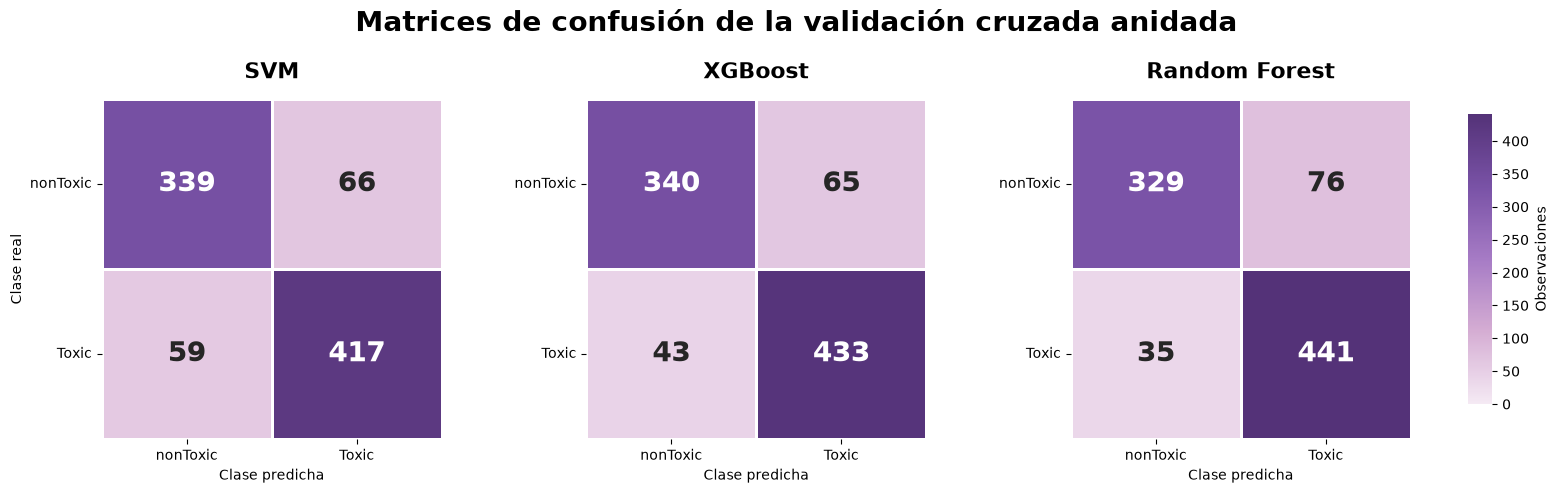

In [231]:
modelos = ["SVM", "XGBoost", "Random Forest"]

# Esquema de colores
cmap_morado = LinearSegmentedColormap.from_list(
    "rosa_morado",
    ["#F5EAF4", "#D5ADD3", "#A67BC5", "#7952A6", "#543278"]
)

# Construir matrices de confusión
matrices_anidadas = {}

for modelo in modelos:

    datos_modelo = predicciones_anidadas.loc[
        predicciones_anidadas["Modelo"] == modelo
    ]

    matrices_anidadas[modelo] = confusion_matrix(
        datos_modelo["Real"],
        datos_modelo["Predicción"],
        labels=[0, 1]
    )

# Escala de color compartida
vmax = max(
    matriz.max()
    for matriz in matrices_anidadas.values()
)

# Visualización
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

cbar_ax = fig.add_axes([0.92, 0.19, 0.015, 0.58])

for i, modelo in enumerate(modelos):

    sns.heatmap(
        matrices_anidadas[modelo],
        annot=True,
        fmt="d",
        cmap=cmap_morado,
        vmin=0,
        vmax=vmax,
        square=True,
        linewidths=2,
        linecolor="white",
        xticklabels=["nonToxic", "Toxic"],
        yticklabels=["nonToxic", "Toxic"],
        annot_kws={
            "fontsize": 20,
            "fontweight": "bold"
        },
        cbar=(i == 2),
        cbar_ax=cbar_ax if i == 2 else None,
        ax=axes[i]
    )

    axes[i].set_title(
        modelo,
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    axes[i].set_xlabel("Clase predicha")
    axes[i].set_ylabel("Clase real" if i == 0 else "")
    axes[i].tick_params(axis="y", rotation=0)

cbar_ax.set_ylabel("Observaciones")

fig.suptitle(
    "Matrices de confusión de la validación cruzada anidada",
    fontsize=20,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.06,
    right=0.89,
    bottom=0.12,
    top=0.80,
    wspace=0.35
)

plt.show()

XGBoost presentó el menor número de errores totales (108), mientras que Random Forest obtuvo el menor número de falsos negativos (35), mostrando una mayor capacidad para detectar nanopartículas tóxicas. Por su parte, SVM presentó el mayor número de errores totales (125).En comparación con la evaluación realizada durante la optimización de hiperparámetros, los tres modelos incrementaron su número de errores, siendo SVM el más afectado. Random Forest mantuvo su número de falsos negativos, aunque aumentaron sus falsos positivos. Estos resultados posicionaron a XGBoost y Random Forest como los modelos más competitivos. Desde una perspectiva de seguridad, Random Forest resultó especialmente interesante debido al riesgo asociado con clasificar nanopartículas tóxicas como no tóxicas.

El incremento de errores no implica necesariamente que la optimización haya perjudicado a los modelos, sino que la validación anidada proporciona una evaluación menos optimista de su desempeño.

#### 12.4. Coincidencia y persistencia de errores

Se analizará la coincidencia de errores entre los tres modelos bajo la validación cruzada anidada, con el propósito de determinar si los patrones de clasificación incorrecta identificados anteriormente se mantienen bajo un esquema de evaluación más riguroso.

##### 12.4.1. Coincidencia de errores entre modelos

Se calculará el número de observaciones mal clasificadas en común y el índice de Jaccard entre cada par de clasificadores. Asimismo, se identificará la cantidad de observaciones clasificadas incorrectamente por uno, dos o los tres modelos.

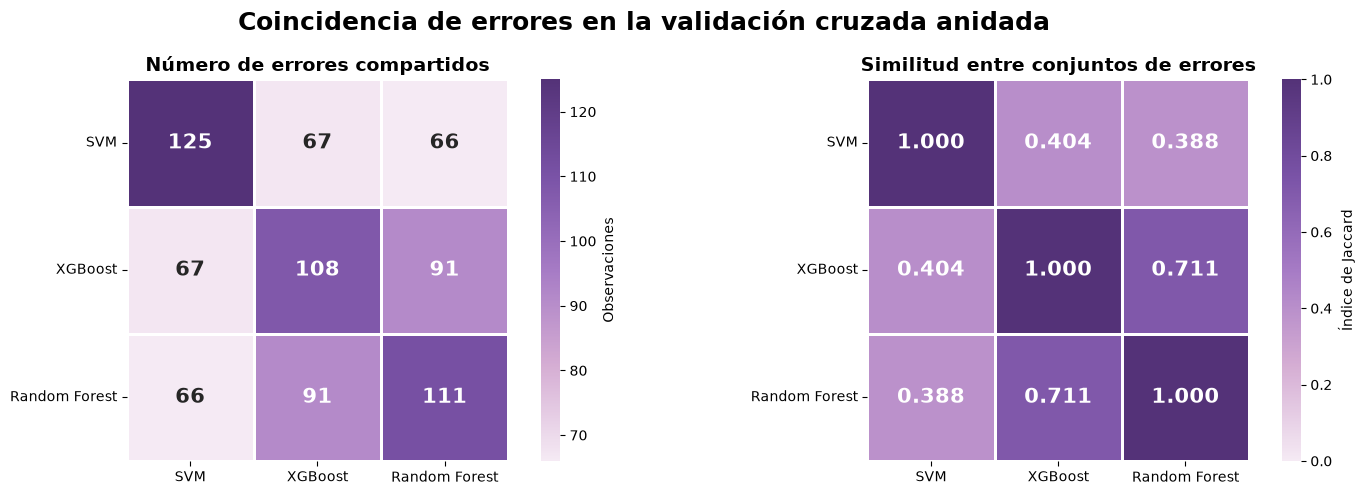

In [232]:
modelos = ["SVM", "XGBoost", "Random Forest"]

# Identificar observaciones mal clasificadas
errores_anidados = {
    modelo: set(
        predicciones_anidadas.loc[
            (predicciones_anidadas["Modelo"] == modelo) &
            (predicciones_anidadas["Error"]),
            "Observación"
        ]
    )
    for modelo in modelos
}

# Matrices de coincidencia
matriz_errores_anidados = pd.DataFrame(
    0, index=modelos, columns=modelos
)

matriz_jaccard_anidado = pd.DataFrame(
    0.0, index=modelos, columns=modelos
)

for modelo_a in modelos:
    for modelo_b in modelos:

        errores_a = errores_anidados[modelo_a]
        errores_b = errores_anidados[modelo_b]

        interseccion = errores_a & errores_b
        union = errores_a | errores_b

        matriz_errores_anidados.loc[
            modelo_a, modelo_b
        ] = len(interseccion)

        matriz_jaccard_anidado.loc[
            modelo_a, modelo_b
        ] = len(interseccion) / len(union) if union else 1.0

# Visualizar matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    matriz_errores_anidados,
    annot=True,
    fmt="d",
    cmap=cmap_morado,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"fontsize": 15, "fontweight": "bold"},
    cbar_kws={"label": "Observaciones"},
    ax=axes[0]
)

axes[0].set_title(
    "Número de errores compartidos",
    fontsize=14,
    fontweight="bold"
)

sns.heatmap(
    matriz_jaccard_anidado,
    annot=True,
    fmt=".3f",
    cmap=cmap_morado,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"fontsize": 15, "fontweight": "bold"},
    cbar_kws={"label": "Índice de Jaccard"},
    ax=axes[1]
)

axes[1].set_title(
    "Similitud entre conjuntos de errores",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)

fig.suptitle(
    "Coincidencia de errores en la validación cruzada anidada",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

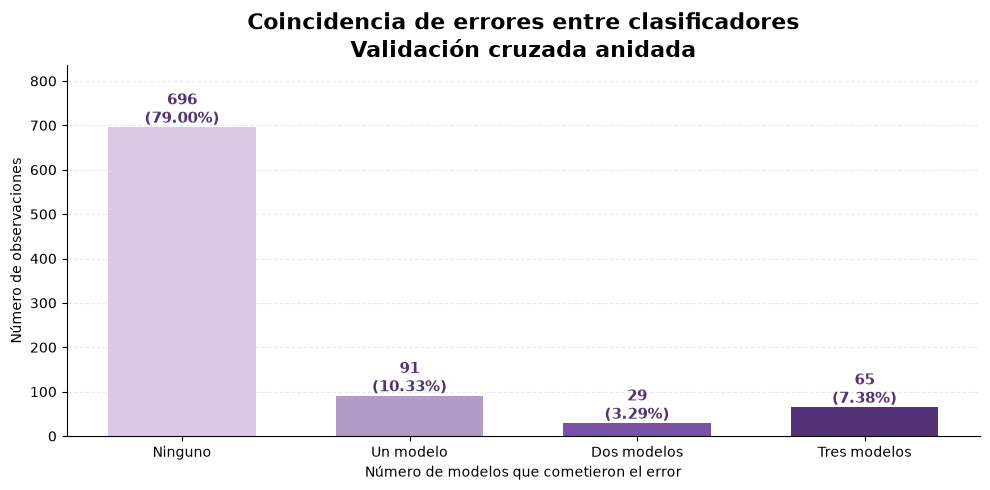

In [233]:
# Número de modelos que clasificaron incorrectamente
# cada observación
conteo_errores_anidados = (
    predicciones_anidadas
    .groupby("Observación")["Error"]
    .sum()
    .value_counts()
    .reindex(range(4), fill_value=0)
    .sort_index()
)

assert conteo_errores_anidados.sum() == len(X)

porcentajes_anidados = (
    conteo_errores_anidados / len(X) * 100
)

categorias = [
    "Ninguno",
    "Un modelo",
    "Dos modelos",
    "Tres modelos"
]

colores = [
    "#D9C9E5",
    "#B39BC8",
    "#7952A6",
    "#543278"
]

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    categorias,
    conteo_errores_anidados.values,
    color=colores,
    width=0.65
)

for barra, cantidad, porcentaje in zip(
    barras,
    conteo_errores_anidados.values,
    porcentajes_anidados.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 10,
        f"{cantidad}\n({porcentaje:.2f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#543278"
    )

ax.set_title(
    "Coincidencia de errores entre clasificadores\n"
    "Validación cruzada anidada",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Número de modelos que cometieron el error")
ax.set_ylabel("Número de observaciones")

ax.set_ylim(
    0, conteo_errores_anidados.max() * 1.20
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [234]:
comparacion_errores_etapas = pd.DataFrame({
    "Modelos que cometieron el error": categorias,
    "Antes de la optimización": [726, 77, 30, 48],
    "Después de la optimización": [734, 73, 26, 48],
    "Validación anidada": conteo_errores_anidados.values
})

comparacion_errores_etapas["Cambio respecto a la optimización"] = (
    comparacion_errores_etapas["Validación anidada"] -
    comparacion_errores_etapas["Después de la optimización"]
)

display(comparacion_errores_etapas)

# Observaciones mal clasificadas por los tres modelos
comunes_anidados = set.intersection(
    *(errores_anidados[modelo] for modelo in modelos)
)

print(
    "\nErrores compartidos por los tres modelos:",
    len(comunes_anidados)
)

print(
    f"Porcentaje del dataset: "
    f"{100 * len(comunes_anidados) / len(X):.2f}%"
)

,Modelos que cometieron el error,Antes de la optimización,Después de la optimización,Validación anidada,Cambio respecto a la optimización
0,Ninguno,726,734,696,-38
1,Un modelo,77,73,91,18
2,Dos modelos,30,26,29,3
3,Tres modelos,48,48,65,17



Errores compartidos por los tres modelos: 65
Porcentaje del dataset: 7.38%


XGBoost y Random Forest presentaron la mayor coincidencia de errores, con 91 observaciones mal clasificadas en común y un índice de Jaccard de 0.711, superior al obtenido antes y después de la optimización. Esta similitud podría estar relacionada con que ambos modelos se basan en ensambles de árboles de decisión. Por su parte, SVM mantuvo una menor similitud con ambos modelos, lo que sugirió cierta complementariedad entre sus patrones de clasificación.

El número de observaciones clasificadas incorrectamente por los tres modelos aumentó de 48 a 65, representando el 7.38% del conjunto de datos. Asimismo, el porcentaje de observaciones clasificadas correctamente por los tres modelos disminuyó del 83.31% al 79.00%.

**La coincidencia de errores bajo diferentes modelos y esquemas de evaluación sugirió que ciertas observaciones podrían presentar dificultades de clasificación asociadas con las características o limitaciones del conjunto de datos.** Sin embargo, será necesario analizar la persistencia individual de estos errores para determinar si corresponden a las mismas observaciones identificadas anteriormente.

##### 12.4.2. Persistencia de errores a través de las tres etapas

Se identificarán las observaciones clasificadas incorrectamente por los tres modelos antes de la optimización, después de la optimización y durante la validación cruzada anidada. Se calculará la proporción de errores que persistieron a través de las tres etapas, así como la cantidad de errores compartidos corregidos y nuevos errores compartidos.

Este análisis permitirá determinar si las dificultades de clasificación se mantuvieron a pesar de los cambios en los hiperparámetros y en el esquema de evaluación.

In [235]:
modelos = ["SVM", "XGBoost", "Random Forest"]

# Errores antes de la optimización
errores_antes = {
    modelo: set(
        predicciones_preliminares.loc[
            (predicciones_preliminares["Modelo"] == modelo) &
            (predicciones_preliminares["Error"]),
            "Observación"
        ]
    )
    for modelo in modelos
}

# Errores compartidos en cada etapa
comunes_antes = set.intersection(
    *(errores_antes[m] for m in modelos)
)

comunes_despues = set.intersection(
    *(set(errores_opt[m]) for m in modelos)
)

comunes_anidados = set.intersection(
    *(errores_anidados[m] for m in modelos)
)

# Verificar resultados anteriores
assert len(comunes_antes) == 48
assert len(comunes_despues) == 48
assert len(comunes_anidados) == 65

# Errores persistentes antes y después de optimizar
persistentes_11 = comunes_antes & comunes_despues

assert len(persistentes_11) == 46

# Errores persistentes en las tres etapas
persistentes_12 = (
    comunes_antes &
    comunes_despues &
    comunes_anidados
)

# Errores que dejaron de ser compartidos
no_persistentes_12 = (
    persistentes_11 - comunes_anidados
)

# Errores compartidos nuevos respecto a la optimización
nuevos_anidados = (
    comunes_anidados - comunes_despues
)

# Errores compartidos exclusivamente en la validación anidada
exclusivos_anidados = (
    comunes_anidados -
    (comunes_antes | comunes_despues)
)

# Resumen
resumen_persistencia_anidada = pd.DataFrame({
    "Categoría": [
        "Errores compartidos antes de optimizar",
        "Errores compartidos después de optimizar",
        "Errores compartidos en validación anidada",
        "Errores persistentes en las primeras dos etapas",
        "Errores persistentes en las tres etapas",
        "Errores que dejaron de ser persistentes",
        "Nuevos errores respecto a la optimización",
        "Errores exclusivos de la validación anidada"
    ],
    "Observaciones": [
        len(comunes_antes),
        len(comunes_despues),
        len(comunes_anidados),
        len(persistentes_11),
        len(persistentes_12),
        len(no_persistentes_12),
        len(nuevos_anidados),
        len(exclusivos_anidados)
    ]
})

display(resumen_persistencia_anidada)

# Tasa de persistencia
tasa_persistencia_anidada = (
    len(persistentes_12) / len(persistentes_11) * 100
)

print(
    f"\nPersistencia de errores en las tres etapas: "
    f"{tasa_persistencia_anidada:.2f}%"
)

print(
    f"Porcentaje del dataset con errores persistentes: "
    f"{100 * len(persistentes_12) / len(X):.2f}%"
)

,Categoría,Observaciones
0,Errores compartidos antes de optimizar,48
1,Errores compartidos después de optimizar,48
2,Errores compartidos en validación anidada,65
3,Errores persistentes en las primeras dos etapas,46
4,Errores persistentes en las tres etapas,45
5,Errores que dejaron de ser persistentes,1
6,Nuevos errores respecto a la optimización,18
7,Errores exclusivos de la validación anidada,16



Persistencia de errores en las tres etapas: 97.83%
Porcentaje del dataset con errores persistentes: 5.11%


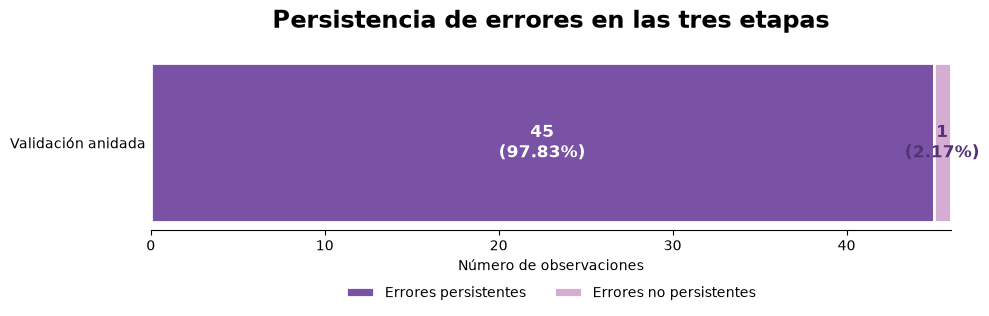

In [236]:
fig, ax = plt.subplots(figsize=(10, 3.5))

cantidades = [
    len(persistentes_12),
    len(no_persistentes_12)
]

etiquetas = [
    "Errores persistentes",
    "Errores no persistentes"
]

colores = ["#7952A6", "#D5ADD3"]

acumulado = 0

for cantidad, etiqueta, color in zip(
    cantidades, etiquetas, colores
):

    ax.barh(
        ["Validación anidada"],
        cantidad,
        left=acumulado,
        color=color,
        height=0.45,
        label=etiqueta,
        edgecolor="white",
        linewidth=2
    )

    if cantidad > 0:

        porcentaje = (
            cantidad / len(persistentes_11) * 100
        )

        ax.text(
            acumulado + cantidad / 2,
            0,
            f"{cantidad}\n({porcentaje:.2f}%)",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white" if color == "#7952A6" else "#543278"
        )

    acumulado += cantidad

ax.set_title(
    "Persistencia de errores en las tres etapas",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Número de observaciones")
ax.set_xlim(0, len(persistentes_11))

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=2,
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

De las 46 observaciones identificadas como errores persistentes antes y después de la optimización, 45 continuaron siendo clasificadas incorrectamente por los tres modelos durante la validación cruzada anidada, lo que representó una tasa de persistencia del 97.83% y el 5.11% del conjunto de datos.

Asimismo, se identificaron 16 observaciones que fueron clasificadas incorrectamente por los tres modelos exclusivamente durante la validación anidada.

**La elevada persistencia de los errores sugirió que las dificultades de clasificación no dependieron únicamente de los modelos o de sus hiperparámetros, sino que podrían estar asociadas con limitaciones inherentes al dataset**, como la presencia de etiquetas contradictorias, variables predictoras insuficientes o variabilidad experimental no registrada. Sin embargo, estos resultados no permitieron establecer las causas específicas de dichos errores.

##### 12.4.3. Relación entre errores persistentes y etiquetas contradictorias

Se analizará la relación entre la presencia de etiquetas contradictorias y los errores persistentes a través de las tres etapas de evaluación. El análisis se limitará a las nanopartículas de ZnO, comparando la tasa de error persistente entre las observaciones con y sin contradicciones. Se calculará la diferencia en puntos porcentuales y la razón entre ambas tasas para determinar si la relación identificada anteriormente se mantiene bajo la validación cruzada anidada.

In [237]:
# Reconstruir el conjunto de datos
datos_persistencia = X.reset_index(drop=True).copy()

datos_persistencia["Clase"] = np.asarray(y)
datos_persistencia["Observación"] = np.arange(len(X))

# Identificar combinaciones con etiquetas contradictorias
datos_persistencia["Contradicción"] = (
    datos_persistencia
    .groupby(
        columnas_predictoras,
        dropna=False
    )["Clase"]
    .transform("nunique")
    .gt(1)
)

# Identificar errores persistentes en las tres etapas
datos_persistencia["Error persistente"] = (
    datos_persistencia["Observación"]
    .isin(persistentes_12)
)

# Verificar resultados
assert datos_persistencia["Contradicción"].sum() == 64
assert datos_persistencia["Error persistente"].sum() == 45

# Seleccionar únicamente nanopartículas de ZnO
datos_zno_anidados = datos_persistencia.loc[
    datos_persistencia["NPs"] == "ZnO"
].copy()

# Calcular tasas de error persistente
tabla_contradicciones_anidada = (
    datos_zno_anidados
    .groupby("Contradicción")
    .agg(
        Observaciones=("Observación", "size"),
        Errores_persistentes=("Error persistente", "sum")
    )
)

tabla_contradicciones_anidada[
    "Observaciones_no_persistentes"
] = (
    tabla_contradicciones_anidada["Observaciones"] -
    tabla_contradicciones_anidada["Errores_persistentes"]
)

tabla_contradicciones_anidada[
    "Tasa de error persistente (%)"
] = (
    tabla_contradicciones_anidada["Errores_persistentes"] /
    tabla_contradicciones_anidada["Observaciones"] * 100
)

tabla_contradicciones_anidada = (
    tabla_contradicciones_anidada.rename(index={
        False: "Sin contradicciones",
        True: "Con contradicciones"
    })
)

display(tabla_contradicciones_anidada.round(2))

# Comparar tasas
tasa_sin = tabla_contradicciones_anidada.loc[
    "Sin contradicciones",
    "Tasa de error persistente (%)"
]

tasa_con = tabla_contradicciones_anidada.loc[
    "Con contradicciones",
    "Tasa de error persistente (%)"
]

diferencia_tasas = tasa_con - tasa_sin

razon_tasas = (
    tasa_con / tasa_sin if tasa_sin > 0 else np.nan
)

print(f"\nDiferencia: {diferencia_tasas:+.2f} puntos porcentuales")
print(f"Razón de tasas: {razon_tasas:.2f}")

,Observaciones,Errores_persistentes,Observaciones_no_persistentes,Tasa de error persistente (%)
Contradicción,,,,
Sin contradicciones,530,33,497,6.23
Con contradicciones,64,11,53,17.19



Diferencia: +10.96 puntos porcentuales
Razón de tasas: 2.76


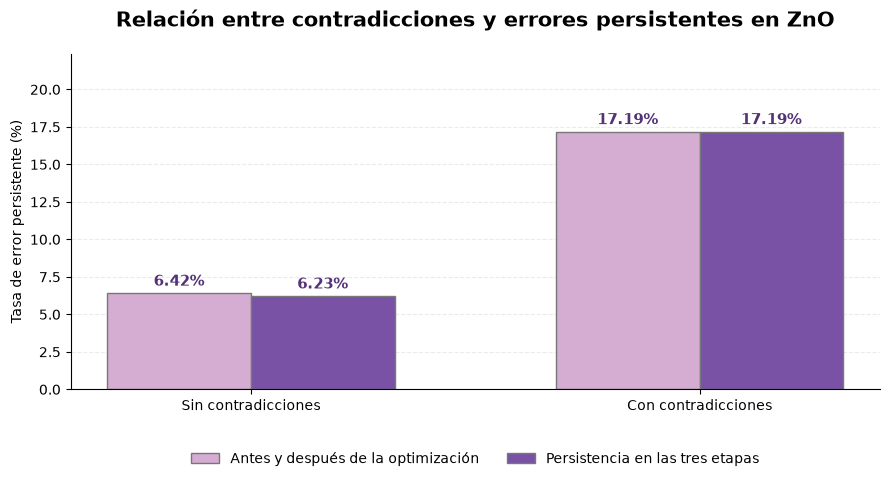

In [238]:
categorias = [
    "Sin contradicciones",
    "Con contradicciones"
]

# Resultados obtenidos en la sección 11.5
tasas_anteriores = [
    100 * 34 / 530,
    100 * 11 / 64
]

# Resultados de las tres etapas
tasas_actuales = [
    tasa_sin,
    tasa_con
]

x = np.arange(len(categorias))
ancho = 0.32

fig, ax = plt.subplots(figsize=(9, 5))

barras_antes = ax.bar(
    x - ancho / 2,
    tasas_anteriores,
    width=ancho,
    color="#D5ADD3",
    edgecolor="#777777",
    label="Antes y después de la optimización"
)

barras_anidadas = ax.bar(
    x + ancho / 2,
    tasas_actuales,
    width=ancho,
    color="#7952A6",
    edgecolor="#777777",
    label="Persistencia en las tres etapas"
)

# Etiquetas de valores
for barras in [barras_antes, barras_anidadas]:

    for barra in barras:

        valor = barra.get_height()

        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 0.5,
            f"{valor:.2f}%",
            ha="center",
            fontsize=11,
            fontweight="bold",
            color="#543278"
        )

ax.set_xticks(x)
ax.set_xticklabels(categorias)

ax.set_ylabel("Tasa de error persistente (%)")

ax.set_title(
    "Relación entre contradicciones y errores persistentes en ZnO",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_ylim(
    0,
    max(tasas_anteriores + tasas_actuales) * 1.30
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

La relación entre las etiquetas contradictorias y los errores persistentes se mantuvo bajo la validación cruzada anidada. Las observaciones de ZnO con contradicciones presentaron una tasa de error persistente del 17.19%, frente al 6.23% de aquellas sin contradicciones, lo que representó una diferencia de 10.96 puntos porcentuales y una razón de tasas de 2.76. Asimismo, las 11 observaciones contradictorias identificadas anteriormente continuaron siendo clasificadas incorrectamente por los tres modelos durante las tres etapas de evaluación.

**Estos resultados reforzaron la hipótesis de que las inconsistencias del conjunto de datos podrían limitar el desempeño predictivo de los modelos.** Sin embargo, la presencia de errores persistentes en observaciones sin contradicciones sugirió que también podrían existir otros factores, como variables predictoras insuficientes o condiciones experimentales no registradas. La asociación observada no permitió establecer una relación causal.

#### 12.5. Discusión y selección de modelos

La validación cruzada anidada permitió comparar el desempeño de los tres clasificadores mediante una evaluación externa a la búsqueda interna de hiperparámetros.

XGBoost obtuvo el mayor F1 promedio (0.8924 ± 0.0766), seguido de Random Forest (0.8917 ± 0.0945) y SVM (0.8670 ± 0.1255). Aunque XGBoost presentó una menor variabilidad entre pliegues, la diferencia de desempeño respecto a Random Forest fue prácticamente insignificante en términos numéricos.

También se observaron diferencias entre las métricas. Random Forest alcanzó la mayor sensibilidad (0.9169), lo que resulta relevante para identificar nanopartículas potencialmente tóxicas, mientras que XGBoost obtuvo la mayor precisión (0.9021). Las matrices de confusión respaldaron estos resultados: Random Forest presentó el menor número de falsos negativos (35), mientras que XGBoost presentó el menor número de errores totales (108). Esto refleja un compromiso entre detectar observaciones tóxicas y reducir las clasificaciones incorrectas.

Por su parte, SVM presentó un desempeño promedio inferior y mayor variabilidad, aunque alcanzó resultados competitivos en algunos pliegues. Esto sugiere que su comportamiento puede ser más sensible a las características de los grupos utilizados para la evaluación.

El análisis de coincidencia de errores mostró una mayor similitud entre Random Forest y XGBoost, con un índice de Jaccard de 0.711, lo que podría estar relacionado con su arquitectura basada en ensambles de árboles de decisión. Asimismo, 45 de las 46 observaciones identificadas previamente como errores persistentes continuaron siendo clasificadas incorrectamente por los tres modelos, a pesar de los cambios en los hiperparámetros y en el esquema de evaluación.

La elevada persistencia de estos errores (97.83%), junto con una tasa de error persistente 2.76 veces mayor en los registros contradictorios de ZnO, sugirió que parte de las dificultades de clasificación podría estar asociada con limitaciones del conjunto de datos y no únicamente con los modelos empleados. Sin embargo, no fue posible establecer una relación causal.

En consecuencia, se seleccionaron **Random Forest y XGBoost como modelos principales** para los análisis posteriores, conservando SVM como referencia comparativa.

Finalmente, aunque la validación por grupos permitió evaluar los modelos sobre observaciones relacionadas con grupos no vistos durante el entrenamiento, todavía no se ha determinado su capacidad para generalizar a tipos de nanopartículas completamente desconocidos. Para investigar esta limitación, se realizará un experimento *Leave-One-Nanoparticle-Type-Out*.

### 13. Evaluación de generalización a tipos de nanopartículas no vistos

Se evaluará la capacidad de generalización de los modelos mediante una estrategia *Leave-One-Nanoparticle-Type-Out*, en la que cada tipo de nanopartícula se excluirá completamente del entrenamiento y se utilizará como conjunto de evaluación. Este procedimiento permitirá determinar si los patrones aprendidos a partir de las propiedades fisicoquímicas de ciertos tipos de nanopartículas pueden transferirse a otros materiales.

Se evaluarán Random Forest y XGBoost como modelos principales, conservando SVM como referencia comparativa.

#### 13.1. Preparación de las particiones

Se analizará la cantidad de observaciones y la distribución de clases de cada tipo de nanopartícula. Posteriormente, se construirán cinco particiones, utilizando cuatro tipos para entrenamiento y uno para evaluación. Antes de entrenar los modelos, se comprobará que el tipo de nanopartícula utilizado para evaluación no aparezca en el conjunto de entrenamiento.

In [ ]:
# Preparar los datos para el análisis
datos_np = X[["NPs"]].copy().reset_index(drop=True)
datos_np["Toxicidad"] = np.asarray(y)

# Distribución de clases por tipo de nanopartícula
distribucion_np = pd.crosstab(
    datos_np["NPs"],
    datos_np["Toxicidad"]
).reindex(columns=[0, 1], fill_value=0)

distribucion_np = distribucion_np.rename(
    columns={0: "No tóxicas", 1: "Tóxicas"}
)

distribucion_np["Total"] = distribucion_np.sum(axis=1)

distribucion_np["% tóxicas"] = (
    100 * distribucion_np["Tóxicas"]
    / distribucion_np["Total"]
)

display(distribucion_np.round(2))


In [ ]:
# Cada tipo de nanopartícula define un grupo
tipos_np = X["NPs"].to_numpy()

logo_np = LeaveOneGroupOut()

pliegues_np = list(
    logo_np.split(X, y, groups=tipos_np)
)

resumen_np = []

for i, (idx_train, idx_test) in enumerate(
    pliegues_np, start=1
):
    tipos_train = set(tipos_np[idx_train])
    tipos_test = set(tipos_np[idx_test])

    assert tipos_train.isdisjoint(tipos_test), (
        "Se detectó un tipo compartido."
    )

    resumen_np.append({
        "Pliegue": i,
        "NP excluida": ", ".join(sorted(tipos_test)),
        "Entrenamiento": len(idx_train),
        "Evaluación": len(idx_test),
        "Grupos compartidos": len(
            tipos_train.intersection(tipos_test)
        ),
        "% tóxicas test": round(
            100 * np.asarray(y)[idx_test].mean(), 2
        )
    })

tabla_particiones_np = pd.DataFrame(resumen_np)

display(tabla_particiones_np)

print(
    "\nParticiones Leave-One-Nanoparticle-Type-Out "
    "preparadas correctamente."
)

Las particiones *Leave-One-Nanoparticle-Type-Out* se construyeron correctamente, sin superposición de tipos de nanopartículas entre entrenamiento y evaluación. Se identificaron diferencias importantes en la cantidad de observaciones y la distribución de clases. ZnO concentró la mayor cantidad de registros (594), mientras que Al₂O₃ y Fe₂O₃ contaron únicamente con 18 observaciones cada uno, todas clasificadas como no tóxicas.

También se observó un fuerte desbalance en TiO₂, con solo un 3% de observaciones tóxicas, en contraste con CuO (78.43%) y ZnO (72.39%).

Estas diferencias deberán considerarse al interpretar los resultados, ya que algunas métricas no estarán definidas para materiales que contienen una sola clase. Por ello, la evaluación incluirá métricas por clase y matrices de confusión, evitando depender exclusivamente del F1.

#### 13.2. Evaluación Leave-One-Nanoparticle-Type-Out

Se evaluará la capacidad de generalización de SVM, Random Forest y XGBoost mediante cinco particiones, dejando fuera un tipo de nanopartícula en cada una. En este experimento se excluirá la variable categórica `NPs` de las características predictoras, utilizando únicamente las propiedades fisicoquímicas. Esto permitirá estudiar si los patrones aprendidos de otros materiales pueden transferirse a un tipo de nanopartícula desconocido.

Se conservarán las estrategias de entrenamiento seleccionadas anteriormente para cada modelo, adaptando el preprocesamiento a las variables numéricas disponibles. La evaluación considerará las diferencias en tamaño y distribución de clases entre materiales.

In [ ]:
# Variables fisicoquímicas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

X_np = X[variables_numericas].copy()

# SVM: sin duplicados + oversampling
pipeline_svm_np = ImbPipeline([
    ("escalado", StandardScaler()),
    ("balanceo", RandomOverSampler(random_state=42)),
    ("modelo", SVC(
        kernel="rbf",
        C=1,
        gamma=0.15,
        random_state=42
    ))
])

estimador_svm_np = ClasificadorSinDuplicados(
    pipeline=pipeline_svm_np
)

# Random Forest: Mutual Information
selector_mi_np = SelectKBest(
    score_func=partial(
        mutual_info_classif,
        random_state=42
    ),
    k=5
)

pipeline_rf_np = Pipeline([
    ("escalado", StandardScaler()),
    ("seleccion", selector_mi_np),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=1
    ))
])

# XGBoost: sin reducción
pipeline_xgb_np = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=0.85,
        min_child_weight=1,
        reg_lambda=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

modelos_np = {
    "SVM": estimador_svm_np,
    "Random Forest": pipeline_rf_np,
    "XGBoost": pipeline_xgb_np
}

print("Preparación completada.")
print("Características utilizadas:", X_np.shape[1])
print("Modelos:", list(modelos_np.keys()))
print("Particiones:", len(pliegues_np))

##### 13.2.1. Evaluación de los tres modelos

Se ejecutará el procedimiento *Leave-One-Nanoparticle-Type-Out* para SVM, Random Forest y XGBoost. En cada iteración, los modelos se entrenarán utilizando cuatro tipos de nanopartículas y se evaluarán sobre el material excluido.

Se calcularán F1, precisión, sensibilidad, especificidad, exactitud y exactitud balanceada. Cuando alguna clase no esté presente en el conjunto de evaluación, las métricas que dependan de ella se reportarán como no definidas.

También se almacenarán las matrices de confusión y las predicciones individuales para facilitar los análisis posteriores. La eliminación de duplicados, el balanceo y la selección de características se realizarán exclusivamente durante el entrenamiento, evitando utilizar información del material excluido.

In [ ]:
resultados_np = []
predicciones_np = []
matrices_np = {}

y_np = np.asarray(y)
tipos_np = X["NPs"].to_numpy()

for nombre_modelo, estimador in modelos_np.items():

    print(f"\nEvaluando {nombre_modelo}...")

    for idx_train, idx_test in pliegues_np:

        material = str(tipos_np[idx_test][0])

        X_train = X_np.iloc[idx_train]
        X_test = X_np.iloc[idx_test]

        y_train = y_np[idx_train]
        y_test = y_np[idx_test]

        # Entrenar exclusivamente con los otros materiales
        modelo = clone(estimador)
        modelo.fit(X_train, y_train)

        # Predecir el material excluido
        y_pred = modelo.predict(X_test)

        # Matriz de confusión con ambas clases
        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        hay_positivos = (tp + fn) > 0
        hay_negativos = (tn + fp) > 0
        hay_pred_positivos = (tp + fp) > 0

        sensibilidad = (
            tp / (tp + fn)
            if hay_positivos else np.nan
        )

        especificidad = (
            tn / (tn + fp)
            if hay_negativos else np.nan
        )

        precision = (
            tp / (tp + fp)
            if hay_pred_positivos else np.nan
        )

        # F1 tóxico solo si la clase positiva existe
        f1 = (
            f1_score(
                y_test, y_pred,
                pos_label=1,
                zero_division=0
            )
            if hay_positivos else np.nan
        )

        # Promedio de recalls de clases presentes
        recalls = [
            valor for valor in
            [sensibilidad, especificidad]
            if not np.isnan(valor)
        ]
        exactitud_balanceada = np.mean(recalls)

        resultados_np.append({
            "Modelo": nombre_modelo,
            "NP excluida": material,
            "N": len(idx_test),
            "% tóxicas": 100 * np.mean(y_test),
            "F1": f1,
            "Precisión": precision,
            "Sensibilidad": sensibilidad,
            "Especificidad": especificidad,
            "Exactitud": accuracy_score(
                y_test, y_pred
            ),
            "Exactitud balanceada": exactitud_balanceada,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        matrices_np[(nombre_modelo, material)] = np.array([
            [tn, fp],
            [fn, tp]
        ])

        # Guardar predicciones individuales
        for indice, real, predicho in zip(
            idx_test, y_test, y_pred
        ):
            predicciones_np.append({
                "Modelo": nombre_modelo,
                "Índice": indice,
                "NP excluida": material,
                "Real": int(real),
                "Predicción": int(predicho)
            })

        print(
            f"  {material}: "
            f"F1 = {f1:.4f}, "
            f"Exactitud = {accuracy_score(y_test, y_pred):.4f}"
        )

# Convertir resultados a tablas
resultados_np = pd.DataFrame(resultados_np)
predicciones_np = pd.DataFrame(predicciones_np)

display(
    resultados_np[
        [
            "Modelo", "NP excluida", "N",
            "F1", "Precisión", "Sensibilidad",
            "Especificidad", "Exactitud",
            "Exactitud balanceada"
        ]
    ].round(4)
)

La evaluación mostró diferencias importantes en la capacidad de generalización de los modelos según el material excluido.

Random Forest y XGBoost obtuvieron los mejores resultados en CuO, ambos con un F1 de 0.9877. En ZnO, XGBoost presentó el mejor desempeño (F1 = 0.9208), mientras que SVM y Random Forest mostraron una tendencia a clasificar las observaciones como tóxicas.

En contraste, TiO₂ fue el material más difícil de predecir. Aunque los tres modelos identificaron todas las observaciones tóxicas, produjeron numerosos falsos positivos, obteniendo valores de F1 entre 0.0889 y 0.2667.

Para Al₂O₃ y Fe₂O₃, que únicamente contienen observaciones no tóxicas, no fue posible evaluar el F1 de la clase tóxica. SVM y Random Forest clasificaron correctamente todas sus observaciones, mientras que XGBoost presentó algunos falsos positivos en Fe₂O₃.

En conjunto, los resultados evidenciaron que un buen desempeño en validación cruzada por grupos no garantiza una generalización equivalente a materiales completamente desconocidos. Esto destaca la importancia de considerar las diferencias entre tipos de nanopartículas al desarrollar modelos predictivos de toxicidad.

#### 13.3. Comparación visual por tipo de nanopartícula

Se visualizarán los resultados de la evaluación *Leave-One-Nanoparticle-Type-Out* para comparar el desempeño de SVM, Random Forest y XGBoost sobre materiales no observados durante el entrenamiento.

Para Al₂O₃ y Fe₂O₃, que no contienen observaciones tóxicas, el F1 de la clase positiva permanecerá sin definir.

In [ ]:
orden_modelos = ["SVM", "Random Forest", "XGBoost"]
orden_np = ["Al2O3", "CuO", "Fe2O3", "TiO2", "ZnO"]

tabla_f1_np = (
    resultados_np
    .pivot(index="Modelo", columns="NP excluida", values="F1")
    .reindex(index=orden_modelos, columns=orden_np)
)

cmap = LinearSegmentedColormap.from_list(
    "morado_rosa",
    ["#F7D6E6", "#C49AD9", "#7952A6"]
)
cmap.set_bad("#E6E6E6")

fig, ax = plt.subplots(figsize=(9, 4))

imagen = ax.imshow(
    np.ma.masked_invalid(tabla_f1_np.to_numpy(dtype=float)),
    cmap=cmap,
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(orden_np)))
ax.set_xticklabels(
    ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"]
)
ax.set_yticks(range(len(orden_modelos)))
ax.set_yticklabels(orden_modelos)

for i in range(len(orden_modelos)):
    for j in range(len(orden_np)):
        valor = tabla_f1_np.iloc[i, j]
        etiqueta = "N/D" if pd.isna(valor) else f"{valor:.3f}"

        ax.text(
            j, i, etiqueta,
            ha="center",
            va="center",
            color="white" if pd.notna(valor) and valor > 0.7 else "#333333",
            fontweight="bold"
        )

fig.colorbar(imagen, ax=ax, label="F1 de la clase tóxica")
ax.set_title("Generalización a tipos de nanopartículas no vistos")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True
)

colores = ["#D5ADD3", "#A67BC5", "#7952A6"]
x = np.arange(len(orden_np))
ancho = 0.25

for ax, metrica in zip(
    axes, ["Sensibilidad", "Especificidad"]
):
    tabla = (
        resultados_np
        .pivot(
            index="NP excluida",
            columns="Modelo",
            values=metrica
        )
        .reindex(index=orden_np, columns=orden_modelos)
    )

    for i, modelo in enumerate(orden_modelos):
        ax.bar(
            x + (i - 1) * ancho,
            tabla[modelo],
            width=ancho,
            color=colores[i],
            label=modelo
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"]
    )
    ax.set_title(metrica)
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Valor de la métrica")
axes[1].legend(loc="upper right")

fig.suptitle(
    "Sensibilidad y especificidad por material",
    fontsize=13
)

plt.tight_layout()
plt.show()

In [ ]:
cmap_confusion = LinearSegmentedColormap.from_list(
    "confusion_morada",
    ["#F8E7F0", "#B58BCB", "#68439A"]
)

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9),
    constrained_layout=True
)

for i, modelo in enumerate(orden_modelos):
    for j, material in enumerate(orden_np):

        ax = axes[i, j]
        matriz = matrices_np[(modelo, material)]

        # Escala relativa a cada matriz
        ax.imshow(
            matriz,
            cmap=cmap_confusion,
            vmin=0,
            vmax=max(1, matriz.max())
        )

        for fila in range(2):
            for columna in range(2):
                valor = matriz[fila, columna]

                ax.text(
                    columna, fila,
                    str(valor),
                    ha="center",
                    va="center",
                    fontsize=11,
                    fontweight="bold",
                    color=(
                        "white"
                        if valor > matriz.max() * 0.55
                        else "#333333"
                    )
                )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(["No tóx.", "Tóx."])
        ax.set_yticklabels(["No tóx.", "Tóx."])

        if i == 0:
            ax.set_title(
                ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"][j],
                fontsize=12
            )

        if j == 0:
            ax.set_ylabel(
                f"{modelo}\nClase real",
                fontsize=10
            )

        if i == 2:
            ax.set_xlabel("Predicción")

fig.suptitle(
    "Matrices de confusión por modelo y material",
    fontsize=15
)

plt.show()


Las visualizaciones confirmaron que la capacidad de generalización de los modelos dependió considerablemente del tipo de nanopartícula excluido.

Random Forest y XGBoost obtuvieron resultados elevados en CuO, mientras que XGBoost presentó el mejor desempeño en ZnO. En contraste, TiO₂ representó el mayor desafío para los tres clasificadores, con valores bajos de F1 debido a la gran cantidad de falsos positivos.

Las matrices de confusión mostraron que una sensibilidad elevada no necesariamente estuvo acompañada de una buena especificidad. Particularmente, SVM y Random Forest tendieron a clasificar casi todas las observaciones de ZnO como tóxicas, mientras que XGBoost logró distinguir una mayor proporción de observaciones no tóxicas.

Para Al₂O₃ y Fe₂O₃, la ausencia de observaciones tóxicas impidió evaluar el F1 de la clase positiva. Aunque la mayoría de los modelos clasificaron correctamente estas observaciones, los resultados deben interpretarse considerando el tamaño reducido de ambos conjuntos.

En general, los resultados evidenciaron limitaciones importantes en la transferencia de patrones de toxicidad entre materiales, especialmente cuando sus distribuciones de clases y características difieren de las utilizadas durante el entrenamiento.

#### 13.4. Discusión de la capacidad de generalización

La evaluación *Leave-One-Nanoparticle-Type-Out* mostró que un buen desempeño en validación cruzada por grupos no garantiza una generalización equivalente a tipos de nanopartículas desconocidos.

Los resultados variaron considerablemente según el material. Random Forest y XGBoost alcanzaron un F1 de 0.9877 en CuO, mientras que XGBoost obtuvo 0.9208 en ZnO. En contraste, los tres modelos presentaron dificultades en TiO₂, principalmente debido a la gran cantidad de falsos positivos, a pesar de alcanzar una sensibilidad de 1.0.

Estas diferencias podrían relacionarse con el desbalance de clases, la distribución desigual de observaciones y las propiedades fisicoquímicas de cada material. Además, Al₂O₃ y Fe₂O₃ contaron únicamente con 18 observaciones no tóxicas cada uno, lo que limitó su evaluación.

Los análisis anteriores también evidenciaron limitaciones en la calidad del conjunto de datos, particularmente en ZnO, donde las observaciones con etiquetas contradictorias presentaron una tasa de error persistente 2.76 veces mayor. Sin embargo, las dificultades de generalización observadas en TiO₂, material sin contradicciones identificadas, sugirieron que las inconsistencias en las etiquetas no fueron la única posible limitación del desempeño predictivo.

Otra limitación es que los hiperparámetros se seleccionaron previamente utilizando información de todos los materiales, por lo que este experimento debe considerarse exploratorio. Asimismo, la exclusión de la variable `NPs` modificó la representación de las características, por lo que las diferencias de desempeño respecto a la validación anterior no pueden atribuirse exclusivamente a la evaluación sobre materiales desconocidos.

En general, **XGBoost mostró el desempeño más competitivo en algunos materiales, pero ningún modelo fue superior en todos los casos**. Los resultados destacan la necesidad de contar con datos más diversos, consistentes y equilibrados para mejorar la generalización de los modelos de predicción de toxicidad.

### 14. Conclusiones generales
En este proyecto se evaluaron diferentes modelos de aprendizaje automático para predecir la toxicidad de nanopartículas de óxidos metálicos a partir de sus propiedades fisicoquímicas y condiciones experimentales. Se analizaron los efectos de la representación de características, el tratamiento de registros duplicados y contradictorios, las técnicas de balanceo y la optimización de hiperparámetros. Asimismo, se exploraron las limitaciones del conjunto de datos y la capacidad de generalización de los modelos.


#### 14.1. Respuesta a las preguntas de investigación

**1. ¿Qué tan efectivos son los modelos de aprendizaje automático para predecir la toxicidad de nanopartículas a partir de sus propiedades fisicoquímicas y condiciones experimentales?**

Los resultados mostraron que los modelos de aprendizaje automático fueron capaces de predecir la toxicidad con un desempeño favorable. XGBoost y Random Forest obtuvieron los mejores resultados durante la validación cruzada anidada, con un F1 promedio de 0.8924 y 0.8917, respectivamente. XGBoost destacó por su menor variabilidad entre pliegues y menor número de errores totales, mientras que Random Forest presentó una mayor sensibilidad y un menor número de falsos negativos.

Asimismo, los modelos tradicionales y de ensamble superaron a la red neuronal multicapa en la evaluación preliminar, lo que mostró que una mayor complejidad del modelo no necesariamente se tradujo en un mejor desempeño para este conjunto de datos.

**2. ¿Cómo influyen las técnicas de selección y reducción de características en el desempeño predictivo de los modelos?**

La reducción de dimensionalidad y la selección de características no mejoraron de manera generalizada el desempeño predictivo. La mayoría de los modelos alcanzaron sus mejores resultados utilizando todas las características originales, mientras que Random Forest se benefició de la selección mediante Mutual Information.

Estos resultados mostraron que la conveniencia de aplicar técnicas de selección o reducción de características dependió del modelo utilizado y que reducir la dimensionalidad no necesariamente representó una ventaja predictiva.

**3. ¿Cómo afectan los registros duplicados, las etiquetas contradictorias y las técnicas de balanceo al desempeño de los modelos de clasificación?**

El tratamiento de registros duplicados modificó considerablemente la distribución de clases, generando un mayor desbalance que motivó la aplicación de técnicas como Random Oversampling y SMOTE-NC. Sin embargo, no se identificó una estrategia de tratamiento y balanceo universalmente superior, ya que su efecto dependió del clasificador.

Por otro lado, el análisis de errores permitió identificar 45 observaciones que fueron clasificadas incorrectamente por los tres modelos antes y después de la optimización, así como durante la validación cruzada anidada. Además, las observaciones de ZnO con etiquetas contradictorias presentaron una tasa de error persistente 2.76 veces mayor que aquellas sin contradicciones.

Estos resultados sugirieron que la calidad y consistencia de los datos podrían representar una limitación importante del desempeño predictivo, que no necesariamente puede resolverse mediante la optimización de hiperparámetros o el incremento de la complejidad de los modelos.

**4. ¿Qué capacidad tienen los modelos para generalizar sus predicciones a tipos de nanopartículas no vistos durante el entrenamiento?**

La evaluación Leave-One-Nanoparticle-Type-Out mostró que la capacidad de generalización dependió considerablemente del material evaluado. Aunque se obtuvieron resultados favorables en materiales como CuO y ZnO, los tres modelos presentaron dificultades para clasificar las nanopartículas de TiO₂.

Por lo tanto, un buen desempeño en la validación cruzada por grupos no garantizó una capacidad de generalización equivalente hacia materiales desconocidos. Esto evidenció la necesidad de contar con conjuntos de datos más diversos y representativos antes de considerar la aplicación de estos modelos a nuevos tipos de nanopartículas.

#### 14.2. Limitaciones del estudio

A pesar de los resultados obtenidos, se identificaron las siguientes limitaciones:

- **Tamaño y representatividad del conjunto de datos:** el número de observaciones fue limitado y su distribución entre los cinco tipos de nanopartículas fue considerablemente desigual.

- **Calidad de los datos:** la elevada presencia de registros duplicados y etiquetas contradictorias dificultó el aprendizaje de patrones consistentes. Además, la conservación de duplicados en los pliegues de evaluación pudo influir en las métricas obtenidas.

- **Generalización:** la evaluación sobre materiales no vistos tuvo un carácter exploratorio, debido a la selección previa de hiperparámetros, la modificación de las características predictoras y la ausencia de un conjunto de datos externo para la validación.

### Reflexión final

Uno de los principales hallazgos de este proyecto fue que mejorar el desempeño predictivo no depende exclusivamente de seleccionar modelos más complejos u optimizar sus hiperparámetros. La elevada persistencia de errores entre clasificadores con diferentes mecanismos de aprendizaje destacó la importancia de la calidad, consistencia y representatividad de los datos.

En este sentido, los resultados sugirieron que mejorar el conjunto de datos podría ser más relevante que continuar incrementando la complejidad de los modelos para avanzar hacia una predicción de toxicidad más confiable y generalizable.

## Referencias

- Escorihuela, L., et al. (2018). Toward computational and experimental characterisation for risk assessment of metal oxide nanoparticles. *Environmental Science: Nano, 5*, 2241–2251. https://doi.org/10.1039/C8EN00389K

- Forest, V. (2022). Experimental and computational nanotoxicology—Complementary approaches for nanomaterial hazard assessment. *Nanomaterials, 12*(8), 1346. https://doi.org/10.3390/nano12081346

- Sayes, C. M., & Warheit, D. B. (2009). Characterization of nanomaterials for toxicity assessment. *WIREs Nanomedicine and Nanobiotechnology, 1*(6), 660–670. https://doi.org/10.1002/wnan.58

- Puzyn, T., et al. (2011). Using nano-QSAR to predict the cytotoxicity of metal oxide nanoparticles. *Nature Nanotechnology, 6*, 175–178. https://doi.org/10.1038/nnano.2011.10

- Banaye Yazdipour, A., et al. (2023). Predicting the toxicity of nanoparticles using artificial intelligence tools: A systematic review. *Nanotoxicology*. https://doi.org/10.1080/17435390.2023.2186279

- Eker, F., et al. (2024). A comprehensive review of nanoparticles: From classification to application and toxicity. *Molecules, 29*(15), 3482. https://doi.org/10.3390/molecules29153482

- UCI Machine Learning. (s. f.). *Nanoparticle Toxicity Dataset* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/ucimachinelearning/nanoparticle-toxicity-dataset

- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A: Mathematical, Physical and Engineering Sciences, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202

- Kraskov, A., Stögbauer, H., & Grassberger, P. (2004). Estimating mutual information. *Physical Review E, 69*(6), 066138. https://doi.org/10.1103/PhysRevE.69.066138

- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research, 3*, 1157–1182. https://www.jmlr.org/papers/v3/guyon03a.html

- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239

- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

- Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth International Group.

- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*, 273–297. https://doi.org/10.1007/BF00994018

- Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32. https://doi.org/10.1023/A:1010933404324

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). Association for Computing Machinery. https://doi.org/10.1145/2939672.2939785

- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org/

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305. https://www.jmlr.org/papers/v13/bergstra12a.html

- Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91

- Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

### Declaración de uso de IA
Para el desarrollo de esta práctica se utilizó ChatGPT (OpenAI) como herramienta de apoyo. Los resultados, el código y las interpretaciones obtenidas fueron revisados y ajustados antes de su incorporación a la tarea. 